<a href="https://colab.research.google.com/github/aziafrin/Klebsiella/blob/main/Klebshiella.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np



# Load Data

In [ ]:
# Load data
df = pd.read_csv("/content/global754_final_metadata_with_source_category.csv", sep="\t", low_memory=False)
#print(df)
print(df.columns)

Index(['Genome_ID', 'Database', 'Country', 'Region', 'Collection_date',
       'Isolation_source', 'Host', 'Species_metadata', 'ST_metadata',
       'Source_category'],
      dtype='object')


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
import pandas as pd
import numpy as np

# Fix: Initialize 'nsuce' from 'local_meta' which contains the 34 local study isolates
nsuce = local_meta.copy()
print(f"Found {len(nsuce)} Bangladeshi isolates")

# Key columns
res_score_col = 'klebsiella_pneumo_complex__resistance_score__resistance_score'
res_class_col = 'klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes'
res_gene_col = 'klebsiella_pneumo_complex__resistance_gene_count__num_resistance_genes'

# Ensure these columns are numeric for calculation
nsuce[res_score_col] = pd.to_numeric(nsuce[res_score_col], errors='coerce')
nsuce[res_class_col] = pd.to_numeric(nsuce[res_class_col], errors='coerce')
nsuce[res_gene_col] = pd.to_numeric(nsuce[res_gene_col], errors='coerce')

# Basic stats for Bangladeshi
print("\n Bangladeshi AMR Summary")
print(nsuce[[res_score_col, res_class_col, res_gene_col]].describe())

# MDR/XDR proxy (example definition: >=3 classes or high score)
nsuce['MDR_like'] = (nsuce[res_class_col] >= 8) | (nsuce[res_score_col] >= 2)
print("\nMDR-like prevalence:", nsuce['MDR_like'].mean())

# Top AMR genes (parse AMR_gene_symbols column)
if 'AMR_gene_symbols' in nsuce.columns:
    amr_genes = nsuce['AMR_gene_symbols'].str.split(';').explode().value_counts().head(20)
    print("\nTop AMR genes in Bangladeshi isolates:\n", amr_genes)
else:
    print("\nAMR_gene_symbols column not found in DataFrame")

Found 34 Bangladeshi isolates

 Bangladeshi AMR Summary
       klebsiella_pneumo_complex__resistance_score__resistance_score  \
count                                          34.000000               
mean                                            0.617647               
std                                             0.696950               
min                                             0.000000               
25%                                             0.000000               
50%                                             0.500000               
75%                                             1.000000               
max                                             2.000000               

       klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes  \
count                                          34.000000                           
mean                                            4.000000                           
std                                        

In [ ]:
import pandas as pd

# Correlation / association
corr = nsuce[[res_score_col, res_class_col, res_gene_col]].corr()
print("\nCorrelation matrix:\n", corr)


Correlation matrix:
                                                     klebsiella_pneumo_complex__resistance_score__resistance_score  \
klebsiella_pneumo_complex__resistance_score__re...                                           1.000000               
klebsiella_pneumo_complex__resistance_class_cou...                                           0.830457               
klebsiella_pneumo_complex__resistance_gene_coun...                                           0.821383               

                                                    klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes  \
klebsiella_pneumo_complex__resistance_score__re...                                           0.830457                           
klebsiella_pneumo_complex__resistance_class_cou...                                           1.000000                           
klebsiella_pneumo_complex__resistance_gene_coun...                                           0.974044                     

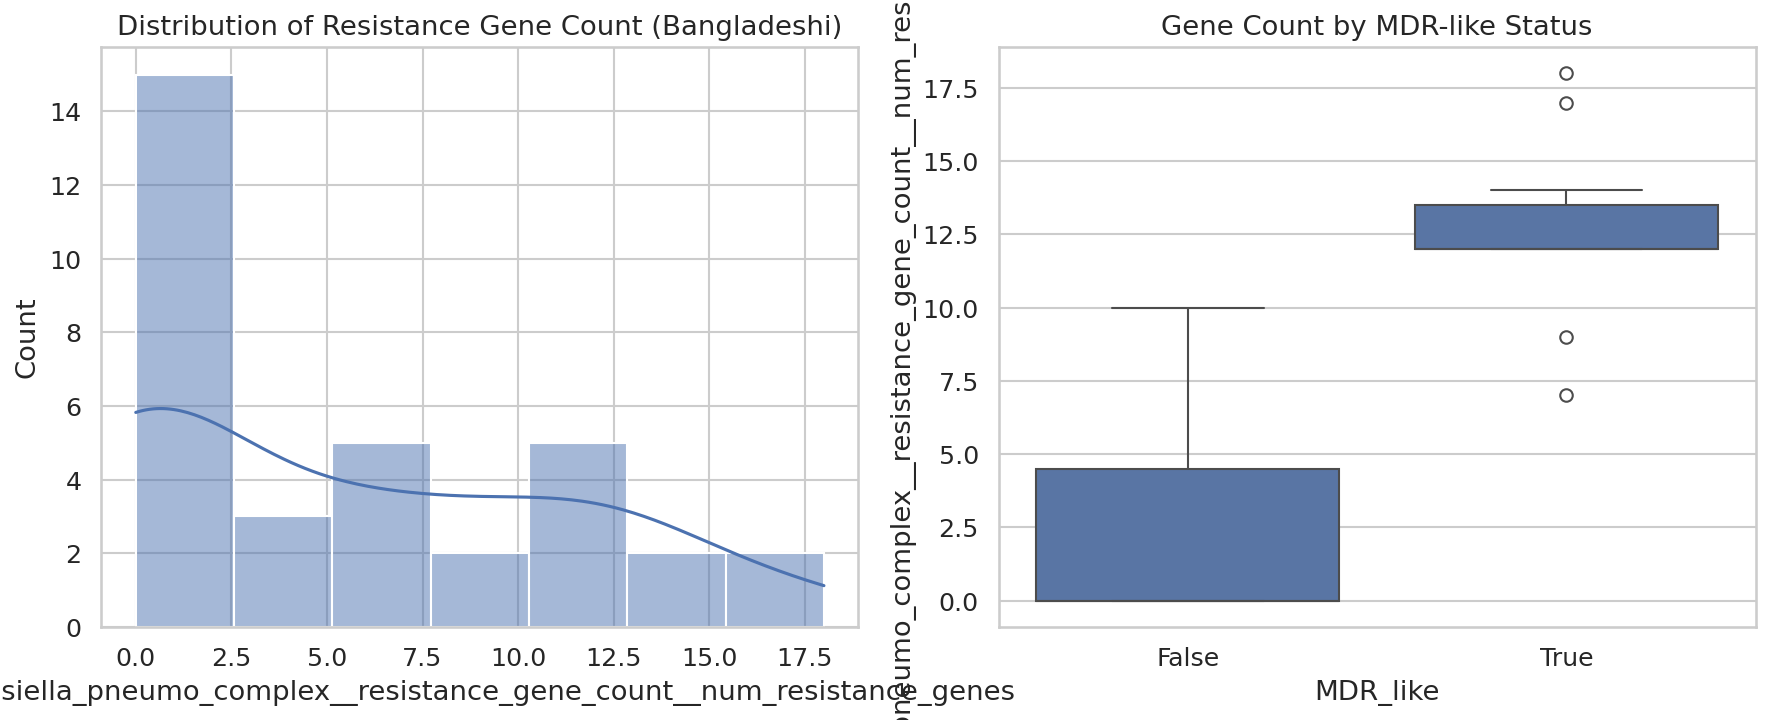

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plots
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(nsuce[res_gene_col], kde=True)
plt.title('Distribution of Resistance Gene Count (Bangladeshi)')

plt.subplot(1, 2, 2)
sns.boxplot(x='MDR_like', y=res_gene_col, data=nsuce)
plt.title('Gene Count by MDR-like Status')

plt.tight_layout()
plt.savefig('amr_descriptive_plots.png')
plt.show()

In [ ]:
summary = nsuce.groupby('MDR_like')[[res_score_col, res_class_col, res_gene_col]].mean()
summary.to_csv('bangladesh_amr_summary.csv')
print(summary)

          klebsiella_pneumo_complex__resistance_score__resistance_score  klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes  \
MDR_like                                                                                                                                             
False                                              0.260870                                                       1.913043                           
True                                               1.363636                                                       8.363636                           

          klebsiella_pneumo_complex__resistance_gene_count__num_resistance_genes  
MDR_like                                                                          
False                                              2.173913                       
True                                              12.545455                       


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from scipy.stats import fisher_exact
from collections import Counter

In [ ]:
bangla = df[df['Genome_ID'].str.contains('NSUCE|SAMN.*Bangladesh|Dhaka', na=False, case=False)].copy()
print(f"Found {len(bangla)} Bangladeshi isolates")

# Key columns
gene_count_col = 'klebsiella_pneumo_complex__resistance_gene_count__num_resistance_genes'
score_col = 'klebsiella_pneumo_complex__resistance_score__resistance_score'
amr_symbols_col = 'AMR_gene_symbols'

# Define MDR/XDR (customize threshold as per your manuscript)
nsuce['is_MDR_XDR'] = (nsuce[score_col] >= 2) | (nsuce[gene_count_col] >= 8)

Found 35 Bangladeshi isolates


 ## 1. SPEARMAN CORRELATION

In [ ]:
corr, p_value = spearmanr(nsuce[gene_count_col], nsuce[score_col], nan_policy='omit')

print("\n=== Spearman Correlation (Gene Count vs Resistance Score) ===")
print(f"Correlation coefficient: {corr:.4f}")
print(f"p-value: {p_value:.2e} {'(significant)' if p_value < 0.05 else '(not significant)'}")


=== Spearman Correlation (Gene Count vs Resistance Score) ===
Correlation coefficient: 0.8822
p-value: 5.39e-12 (significant)


In [ ]:
nsuce['has_CTX_M_15'] = nsuce[amr_symbols_col].fillna('').str.contains('CTX-M-15', case=False, na=False)

# Create contingency table
contingency = pd.crosstab(nsuce['has_CTX_M_15'], nsuce['is_MDR_XDR'])
print("\nContingency Table (CTX-M-15 vs MDR/XDR):\n", contingency)

# Fisher's exact test
oddsratio, pval = fisher_exact(contingency)
print(f"\nFisher's Exact Test (CTX-M-15 vs MDR/XDR):")
print(f"Odds Ratio: {oddsratio:.3f}")
print(f"p-value: {pval:.2e}")

# You can repeat for other genes, e.g., 'NDM', 'OXA'

nsuce['NDM'] = nsuce[amr_symbols_col].fillna('').str.contains('NDM', case=False, na=False)

# Create contingency table
contingency = pd.crosstab(nsuce['NDM'], nsuce['is_MDR_XDR'])
print("\nContingency Table (NDM vs MDR/XDR):\n", contingency)

# Fisher's exact test
oddsratio, pval = fisher_exact(contingency)
print(f"\nFisher's Exact Test (NDM vs MDR/XDR):")
print(f"Odds Ratio: {oddsratio:.3f}")
print(f"p-value: {pval:.2e}")

nsuce['OXA'] = nsuce[amr_symbols_col].fillna('').str.contains('OXA', case=False, na=False)

# Create contingency table
contingency = pd.crosstab(nsuce['OXA'], nsuce['is_MDR_XDR'])
print("\nContingency Table (OXA vs MDR/XDR):\n", contingency)

# Fisher's exact test
oddsratio, pval = fisher_exact(contingency)
print(f"\nFisher's Exact Test (OXA vs MDR/XDR):")
print(f"Odds Ratio: {oddsratio:.3f}")
print(f"p-value: {pval:.2e}")


Contingency Table (CTX-M-15 vs MDR/XDR):
 is_MDR_XDR    False  True 
has_CTX_M_15              
False            17      1
True              5     11

Fisher's Exact Test (CTX-M-15 vs MDR/XDR):
Odds Ratio: 37.400
p-value: 1.81e-04

Contingency Table (NDM vs MDR/XDR):
 is_MDR_XDR  False  True 
NDM                     
False          22      8
True            0      4

Fisher's Exact Test (NDM vs MDR/XDR):
Odds Ratio: inf
p-value: 1.07e-02

Contingency Table (OXA vs MDR/XDR):
 is_MDR_XDR  False  True 
OXA                     
False          21      3
True            1      9

Fisher's Exact Test (OXA vs MDR/XDR):
Odds Ratio: 63.000
p-value: 3.74e-05


# Kleborate MDR/XDR classification + AMR gene descriptive analysis
## Bangladeshi (NSUCE) isolates vs global comparator set

In [ ]:
# ==============================================================================
# ==============================================================================
# Paste each "# %% Cell" block into its own Google Colab cell, in order.
# Designed for the merged Kleborate + hAMRonization TSV
# (e.g. klebsiella_global753.tsv), one row per genome.

# %% Cell 1 - Install/import
!pip install scipy statsmodels scikit-bio --quiet

import pandas as pd
import numpy as np
from scipy import stats
from scipy.stats import fisher_exact, chi2_contingency, mannwhitneyu, spearmanr
from statsmodels.stats.multitest import multipletests
from collections import Counter
import matplotlib.pyplot as plt

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 50)


In [ ]:
# %% Cell 2 - Load data
# In Colab: either mount Drive, or use the upload widget below.
from google.colab import files
uploaded = files.upload()  # select global754_final_metadata_with_source_category.csv (or your merged Kleborate TSV)
FILENAME = list(uploaded.keys())[0]

df = pd.read_csv(FILENAME, sep='\t', low_memory=False)
print(f"Loaded {df.shape[0]} genomes, {df.shape[1]} columns")

Saving global754_final_metadata_with_source_category.csv to global754_final_metadata_with_source_category (1).csv
Loaded 754 genomes, 10 columns


In [ ]:
NSUCE_PREFIX = 'NSUCE'
df['is_NSUCE'] = df['Genome_ID'].astype(str).str.startswith(NSUCE_PREFIX)

# OPTIONAL: if you have a separate accession list of other Bangladeshi public
# genomes (not NSUCE-prefixed), load and merge it here, e.g.:
# bd_public_ids = pd.read_csv('bd_public_accessions.txt', header=None)[0].tolist()
# df['is_bangladeshi'] = df['is_NSUCE'] | df['Genome_ID'].isin(bd_public_ids)
df['is_bangladeshi'] = df['is_NSUCE']  # extend as above if applicable

# De-duplicate GCA/GCF accession pairs referring to the same genome assembly
# (same underlying genome submitted under both GenBank and RefSeq).
df['base_acc'] = df['Genome_ID'].str.replace(r'^(GCA|GCF)_', '', regex=True)
before = len(df)
df = df.drop_duplicates(subset='base_acc', keep='first').reset_index(drop=True)
print(f"Dropped {before - len(df)} duplicate GCA/GCF entries -> {len(df)} unique genomes")

n_bd = df['is_bangladeshi'].sum()
n_global = (~df['is_bangladeshi']).sum()
print(f"Bangladeshi/NSUCE: {n_bd} | Global comparator: {n_global}")

Dropped 0 duplicate GCA/GCF entries -> 689 unique genomes
Bangladeshi/NSUCE: 35 | Global comparator: 654


In [ ]:
# %% Cell 4 - MDR/XDR classification (Magiorakos et al. 2012 convention,
# applied to Kleborate's num_resistance_classes as a genomic proxy)
RC_COL = 'klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes'
CARB_COL = 'klebsiella_pneumo_complex__amr__Bla_Carb_acquired'
ESBL_COL = 'klebsiella_pneumo_complex__amr__Bla_ESBL_acquired'
VIR_COL = 'klebsiella_pneumo_complex__virulence_score__virulence_score'
RES_SCORE_COL = 'klebsiella_pneumo_complex__resistance_score__resistance_score'
ST_COL = 'klebsiella_pneumo_complex__mlst__ST'
K_COL = 'klebsiella_pneumo_complex__kaptive__K_type'

# The 'df' currently contains metadata and not AMR data. This block requires AMR data.
# Load the Kleborate data (klebsiella_global753.tsv) into a separate DataFrame
# and merge it with the existing 'df' to get 'AMR_drug_classes' and other AMR columns.
# 'base_acc' is used as the common unique identifier for merging.
kleborate_data = pd.read_csv("klebsiella_global753.tsv", sep='\t', low_memory=False)
kleborate_data['base_acc'] = kleborate_data['strain'].str.replace(r'^(GCA|GCF)_', '', regex=True)

# Ensure kleborate_data is also deduplicated on 'base_acc' before merging,
# as the current 'df' (metadata) has already been deduplicated.
kleborate_data_dedup = kleborate_data.drop_duplicates(subset='base_acc', keep='first')

# Merge the current 'df' (which has 'is_bangladeshi' and 'base_acc' from previous cell)
# with the kleborate_data_dedup (which has 'AMR_drug_classes' and other Kleborate output).
# Use a left merge to keep all entries from the current 'df'.
df = df.merge(kleborate_data_dedup, on='base_acc', how='left', suffixes=('_meta', '_kleb'))

# Total distinct antimicrobial categories tracked by this Kleborate/hAMRonization
# run - recompute per-dataset rather than hardcoding, in case your panel differs.
all_classes = set()
for v in df['AMR_drug_classes'].dropna():
    if v == '-':
        continue
    for c in v.split(';'):
        all_classes.add(c.strip().lower())  # lower() merges case-duplicates
TOTAL_CLASSES = len(all_classes)
print(f"Total distinct antimicrobial categories tracked: {TOTAL_CLASSES}")
print(sorted(all_classes))

def classify_mdr(n, total=TOTAL_CLASSES):
    if pd.isna(n) or n <= 2:
        return 'Non-MDR'
    if n >= total - 2:
        return 'XDR'
    return 'MDR'

df['mdr_status'] = df[RC_COL].apply(classify_mdr)
df['has_carb'] = df[CARB_COL].apply(lambda x: x != '-' if pd.notna(x) else False)
df['has_esbl'] = df[ESBL_COL].apply(lambda x: x != '-' if pd.notna(x) else False)

print("\nMDR/XDR distribution - Bangladeshi/NSUCE:")
print(df[df.is_bangladeshi]['mdr_status'].value_counts())
print("\nMDR/XDR distribution - Global:")
print(df[~df.is_bangladeshi]['mdr_status'].value_counts())

Total distinct antimicrobial categories tracked: 14
['aminoglycoside antibiotic', 'carbapenem', 'diaminopyrimidine antibiotic', 'fluoroquinolone antibiotic', 'macrolide antibiotic', 'penicillin beta-lactam', 'penicillin beta-lactam + beta-lactamase inhibitor', 'peptide antibiotic', 'phenicol antibiotic', 'phosphonic acid antibiotic', 'rifamycin antibiotic', 'sulfonamide antibiotic', 'tetracycline antibiotic', 'third-generation cephalosporin']

MDR/XDR distribution - Bangladeshi/NSUCE:
mdr_status
MDR        19
Non-MDR    16
Name: count, dtype: int64

MDR/XDR distribution - Global:
mdr_status
MDR        599
Non-MDR     50
XDR          5
Name: count, dtype: int64


In [ ]:
# %% Cell 5 - MDR/XDR correlation tests
# 5a. MDR/XDR status vs carbapenemase carriage (chi-square)
ct = pd.crosstab(df['mdr_status'], df['has_carb'])
chi2, p, dof, exp = chi2_contingency(ct)
print("MDR/XDR status vs carbapenemase carriage")
print(ct)
print(f"Chi-square = {chi2:.2f}, p = {p:.4g}\n")

# 5b. Bangladeshi vs global: proportion MDR (Fisher's exact, 2x2 on MDR+XDR vs Non-MDR)
df['is_mdr_or_xdr'] = df['mdr_status'].isin(['MDR', 'XDR'])
ct2 = pd.crosstab(df['is_bangladeshi'], df['is_mdr_or_xdr'])
odds, p2 = fisher_exact(ct2)
print("Bangladeshi vs global: MDR/XDR vs non-MDR")
print(ct2)
print(f"Odds ratio = {odds:.2f}, Fisher's exact p = {p2:.4g}\n")

# 5c. Resistance class count vs virulence score (Spearman - is resistance
# burden associated with virulence burden / convergence signal?)
rho, p3 = spearmanr(df[RC_COL], df[VIR_COL])
print(f"Resistance class count vs virulence score: Spearman rho = {rho:.3f}, p = {p3:.4g}\n")

# 5d. MDR/XDR status by top STs (chi-square, using only top 10 STs by count)
top_st = df[ST_COL].value_counts().head(10).index
sub = df[df[ST_COL].isin(top_st)]
ct3 = pd.crosstab(sub[ST_COL], sub['mdr_status'])
chi2b, pb, dofb, expb = chi2_contingency(ct3)
print("MDR/XDR status by top 10 sequence types")
print(ct3)
print(f"Chi-square = {chi2b:.2f}, p = {pb:.4g}")

MDR/XDR status vs carbapenemase carriage
has_carb    False  True 
mdr_status              
MDR           212    406
Non-MDR        66      0
XDR             0      5
Chi-square = 110.34, p = 1.098e-24

Bangladeshi vs global: MDR/XDR vs non-MDR
is_mdr_or_xdr   False  True 
is_bangladeshi              
False              50    604
True               16     19
Odds ratio = 0.10, Fisher's exact p = 8.347e-09

Resistance class count vs virulence score: Spearman rho = nan, p = nan

MDR/XDR status by top 10 sequence types
mdr_status                           MDR  Non-MDR  XDR
klebsiella_pneumo_complex__mlst__ST                   
ST11                                  90        0    1
ST14                                  23        1    0
ST147                                 57        1    1
ST15                                  16        2    0
ST16                                  60        1    0
ST307                                 21        4    0
ST340                                 2

In [ ]:
# %% Cell 6 - Descriptive AMR gene analysis (drug-class level), Bangladeshi vs global
CLASS_COLS = {
    'Aminoglycoside': 'klebsiella_pneumo_complex__amr__AGly_acquired',
    'Colistin': 'klebsiella_pneumo_complex__amr__Col_acquired',
    'Fosfomycin': 'klebsiella_pneumo_complex__amr__Fcyn_acquired',
    'Fluoroquinolone (acquired)': 'klebsiella_pneumo_complex__amr__Flq_acquired',
    'Glycopeptide': 'klebsiella_pneumo_complex__amr__Gly_acquired',
    'Macrolide': 'klebsiella_pneumo_complex__amr__MLS_acquired',
    'Phenicol': 'klebsiella_pneumo_complex__amr__Phe_acquired',
    'Rifamycin': 'klebsiella_pneumo_complex__amr__Rif_acquired',
    'Sulfonamide': 'klebsiella_pneumo_complex__amr__Sul_acquired',
    'Tetracycline': 'klebsiella_pneumo_complex__amr__Tet_acquired',
    'Tigecycline': 'klebsiella_pneumo_complex__amr__Tgc_acquired',
    'Trimethoprim': 'klebsiella_pneumo_complex__amr__Tmt_acquired',
    'Beta-lactam (broad)': 'klebsiella_pneumo_complex__amr__Bla_acquired',
    'Beta-lactam+inhR': 'klebsiella_pneumo_complex__amr__Bla_inhR_acquired',
    'ESBL': ESBL_COL,
    'ESBL+inhR': 'klebsiella_pneumo_complex__amr__Bla_ESBL_inhR_acquired',
    'Carbapenemase': CARB_COL,
}

rows = []
for name, col in CLASS_COLS.items():
    bd_present = (df[df.is_bangladeshi][col] != '-').sum()
    gl_present = (df[~df.is_bangladeshi][col] != '-').sum()
    ct4 = [[bd_present, n_bd - bd_present], [gl_present, n_global - gl_present]]
    try:
        _, p4 = fisher_exact(ct4)
    except ValueError:
        p4 = np.nan
    rows.append({
        'drug_class': name,
        'bd_n': bd_present, 'bd_pct': round(100 * bd_present / n_bd, 1),
        'global_n': gl_present, 'global_pct': round(100 * gl_present / n_global, 1),
        'fisher_p': p4,
    })

class_summary = pd.DataFrame(rows).sort_values('bd_pct', ascending=False)
# Multiple-testing correction (Benjamini-Hochberg) across the 17 class comparisons
mask = class_summary['fisher_p'].notna()
class_summary.loc[mask, 'fisher_p_adj'] = multipletests(
    class_summary.loc[mask, 'fisher_p'], method='fdr_bh')[1]
print(class_summary.to_string(index=False))

                drug_class  bd_n  bd_pct  global_n  global_pct     fisher_p  fisher_p_adj
Fluoroquinolone (acquired)    19    54.3       531        81.2 7.029547e-04  1.493779e-03
              Trimethoprim    19    54.3       512        78.3 2.913016e-03  4.952127e-03
                      ESBL    18    51.4       494        75.5 2.643860e-03  4.952127e-03
               Sulfonamide    18    51.4       539        82.4 4.881342e-05  1.659656e-04
            Aminoglycoside    17    48.6       596        91.1 8.580162e-10  1.458628e-08
       Beta-lactam (broad)    11    31.4       425        65.0 1.042344e-04  2.953309e-04
              Tetracycline    10    28.6       248        37.9 2.884090e-01  2.884090e-01
                 Macrolide     9    25.7       388        59.3 1.426945e-04  3.465438e-04
             Carbapenemase     5    14.3       407        62.2 2.527120e-08  2.148052e-07
                  Phenicol     3     8.6       279        42.7 2.551989e-05  1.446127e-04
          

In [ ]:
# %% Cell 7 - Top individual AMR genes/alleles, Bangladeshi isolates
def gene_counter(subdf, col='AMR_gene_symbols'):
    counter = Counter()
    for v in subdf[col].dropna():
        if v == '-':
            continue
        for g in v.split(';'):
            counter[g.strip()] += 1
    return counter

bd_genes = gene_counter(df[df.is_bangladeshi])
global_genes = gene_counter(df[~df.is_bangladeshi])

print("Top 20 AMR genes/alleles - Bangladeshi isolates:")
for g, c in bd_genes.most_common(20):
    print(f"  {g:22s} {c}/{n_bd}  ({100*c/n_bd:.1f}%)")

# Resistance gene *count* comparison (Mann-Whitney U, non-parametric since
# gene counts are unlikely to be normally distributed)
GENE_COUNT_COL = 'klebsiella_pneumo_complex__resistance_gene_count__num_resistance_genes'
u, p5 = mannwhitneyu(df[df.is_bangladeshi][GENE_COUNT_COL],
                      df[~df.is_bangladeshi][GENE_COUNT_COL])
print(f"\nResistance gene count, Bangladeshi vs global (Mann-Whitney U): "
      f"U = {u:.1f}, p = {p5:.4g}")
print(df.groupby('is_bangladeshi')[GENE_COUNT_COL].describe()[['count', 'mean', '50%', 'std']])

Top 20 AMR genes/alleles - Bangladeshi isolates:
  SHV                    19/35  (54.3%)
  CTX-M-15               16/35  (45.7%)
  SHV-11                 14/35  (40.0%)
  GyrA                   11/35  (31.4%)
  ParC                   11/35  (31.4%)
  sul1                   10/35  (28.6%)
  OXA-1                  9/35  (25.7%)
  aac(6)-Ib-cr.v2        9/35  (25.7%)
  catB3.v1               9/35  (25.7%)
  strB.v1                9/35  (25.7%)
  tet(A).v1              9/35  (25.7%)
  strA.v1                9/35  (25.7%)
  sul2                   9/35  (25.7%)
  Mrx                    8/35  (22.9%)
  aac(3)-IIa.v1          8/35  (22.9%)
  mphA                   8/35  (22.9%)
  dfrA14.v2              8/35  (22.9%)
  aadA2                  7/35  (20.0%)
  dfrA12                 7/35  (20.0%)
  qnrB1.v2               6/35  (17.1%)

Resistance gene count, Bangladeshi vs global (Mann-Whitney U): U = nan, p = nan
                count       mean   50%       std
is_bangladeshi                     

In [ ]:
# %% Cell 8 - Intrinsic / mutation-based resistance markers
MUT_COLS = {
    'SHV mutations': 'klebsiella_pneumo_complex__amr__SHV_mutations',
    'OmpK porin mutations': 'klebsiella_pneumo_complex__amr__Omp_mutations',
    'Colistin (mgrB etc.) mutations': 'klebsiella_pneumo_complex__amr__Col_mutations',
    'Fluoroquinolone (gyrA/parC) mutations': 'klebsiella_pneumo_complex__amr__Flq_mutations',
}
for name, col in MUT_COLS.items():
    bd_present = (df[df.is_bangladeshi][col] != '-').sum()
    gl_present = (df[~df.is_bangladeshi][col] != '-').sum()
    print(f"{name:40s} BD: {bd_present}/{n_bd} ({100*bd_present/n_bd:.1f}%)  "
          f"Global: {gl_present}/{n_global} ({100*gl_present/n_global:.1f}%)")


SHV mutations                            BD: 20/35 (57.1%)  Global: 359/654 (54.9%)
OmpK porin mutations                     BD: 7/35 (20.0%)  Global: 390/654 (59.6%)
Colistin (mgrB etc.) mutations           BD: 1/35 (2.9%)  Global: 11/654 (1.7%)
Fluoroquinolone (gyrA/parC) mutations    BD: 12/35 (34.3%)  Global: 409/654 (62.5%)


In [ ]:
# %% Cell 9 - Genetic diversity indices (supports "genetically diverse" claims)
# Simpson's Diversity Index: D = 1 - sum(p_i^2), higher = more diverse
def simpsons_diversity(series):
    counts = series.value_counts()
    p = counts / counts.sum()
    return 1 - (p ** 2).sum()

st_div_bd = simpsons_diversity(df[df.is_bangladeshi][ST_COL])
st_div_gl = simpsons_diversity(df[~df.is_bangladeshi][ST_COL])
k_div_bd = simpsons_diversity(df[df.is_bangladeshi][K_COL])
k_div_gl = simpsons_diversity(df[~df.is_bangladeshi][K_COL])
print(f"Simpson's Diversity Index (ST) - Bangladeshi: {st_div_bd:.3f} | Global: {st_div_gl:.3f}")
print(f"Simpson's Diversity Index (K-type) - Bangladeshi: {k_div_bd:.3f} | Global: {k_div_gl:.3f}")
print(f"Unique STs among Bangladeshi isolates: {df[df.is_bangladeshi][ST_COL].nunique()} / {n_bd} genomes")


Simpson's Diversity Index (ST) - Bangladeshi: 0.955 | Global: 0.951
Simpson's Diversity Index (K-type) - Bangladeshi: 0.957 | Global: 0.935
Unique STs among Bangladeshi isolates: 27 / 35 genomes


In [ ]:
 # %% Cell 10 - Resistance-virulence convergence phenotype
# Isolates combining high virulence score with carbapenemase carriage
CONV_VIR_THRESHOLD = 3  # Kleborate virulence_score >=3 ~ yersiniabactin+colibactin/aerobactin combos
df['is_convergent'] = (df[VIR_COL] >= CONV_VIR_THRESHOLD) & (df['has_carb'])
print(f"Convergent (hypervirulent + carbapenemase-positive) isolates: {df['is_convergent'].sum()}")
print(df[df['is_convergent']][['strain', ST_COL, K_COL, VIR_COL, CARB_COL]])

ct5 = pd.crosstab(df['has_carb'], df[VIR_COL] >= CONV_VIR_THRESHOLD)
try:
    odds5, p6 = fisher_exact(ct5)
    print(f"\nCarbapenemase carriage vs high virulence score: OR = {odds5:.2f}, p = {p6:.4g}")
except ValueError:
    print("Fisher's exact test not computable (zero cell) - report descriptively only.")


    # %% Cell 10 - Resistance-virulence convergence phenotype
# Isolates combining high virulence score with carbapenemase carriage
CONV_VIR_THRESHOLD = 3  # Kleborate virulence_score >=3 ~ yersiniabactin+colibactin/aerobactin combos
df['is_convergent'] = (df[VIR_COL] >= CONV_VIR_THRESHOLD) & (df['has_carb'])
print(f"Convergent (hypervirulent + carbapenemase-positive) isolates: {df['is_convergent'].sum()}")
print(df[df['is_convergent']][['strain', ST_COL, K_COL, VIR_COL, CARB_COL]])

ct5 = pd.crosstab(df['has_carb'], df[VIR_COL] >= CONV_VIR_THRESHOLD)
try:
    odds5, p6 = fisher_exact(ct5)
    print(f"\nCarbapenemase carriage vs high virulence score: OR = {odds5:.2f}, p = {p6:.4g}")
except ValueError:
    print("Fisher's exact test not computable (zero cell) - report descriptively only.")


Convergent (hypervirulent + carbapenemase-positive) isolates: 5
              strain klebsiella_pneumo_complex__mlst__ST klebsiella_pneumo_complex__kaptive__K_type  \
379     SAMN29188178                                ST43                                        K30   
624  GCA_003937205.1                               ST231                                        K51   
640  GCA_022749215.1                              ST2096                                        K64   
641  GCA_022699305.1                              ST2096                                        K64   
642  GCA_022699345.1                              ST2096                               Capsule null   

     klebsiella_pneumo_complex__virulence_score__virulence_score klebsiella_pneumo_complex__amr__Bla_Carb_acquired  
379                                                4.0                                                     OXA-181  
624                                                4.0                             

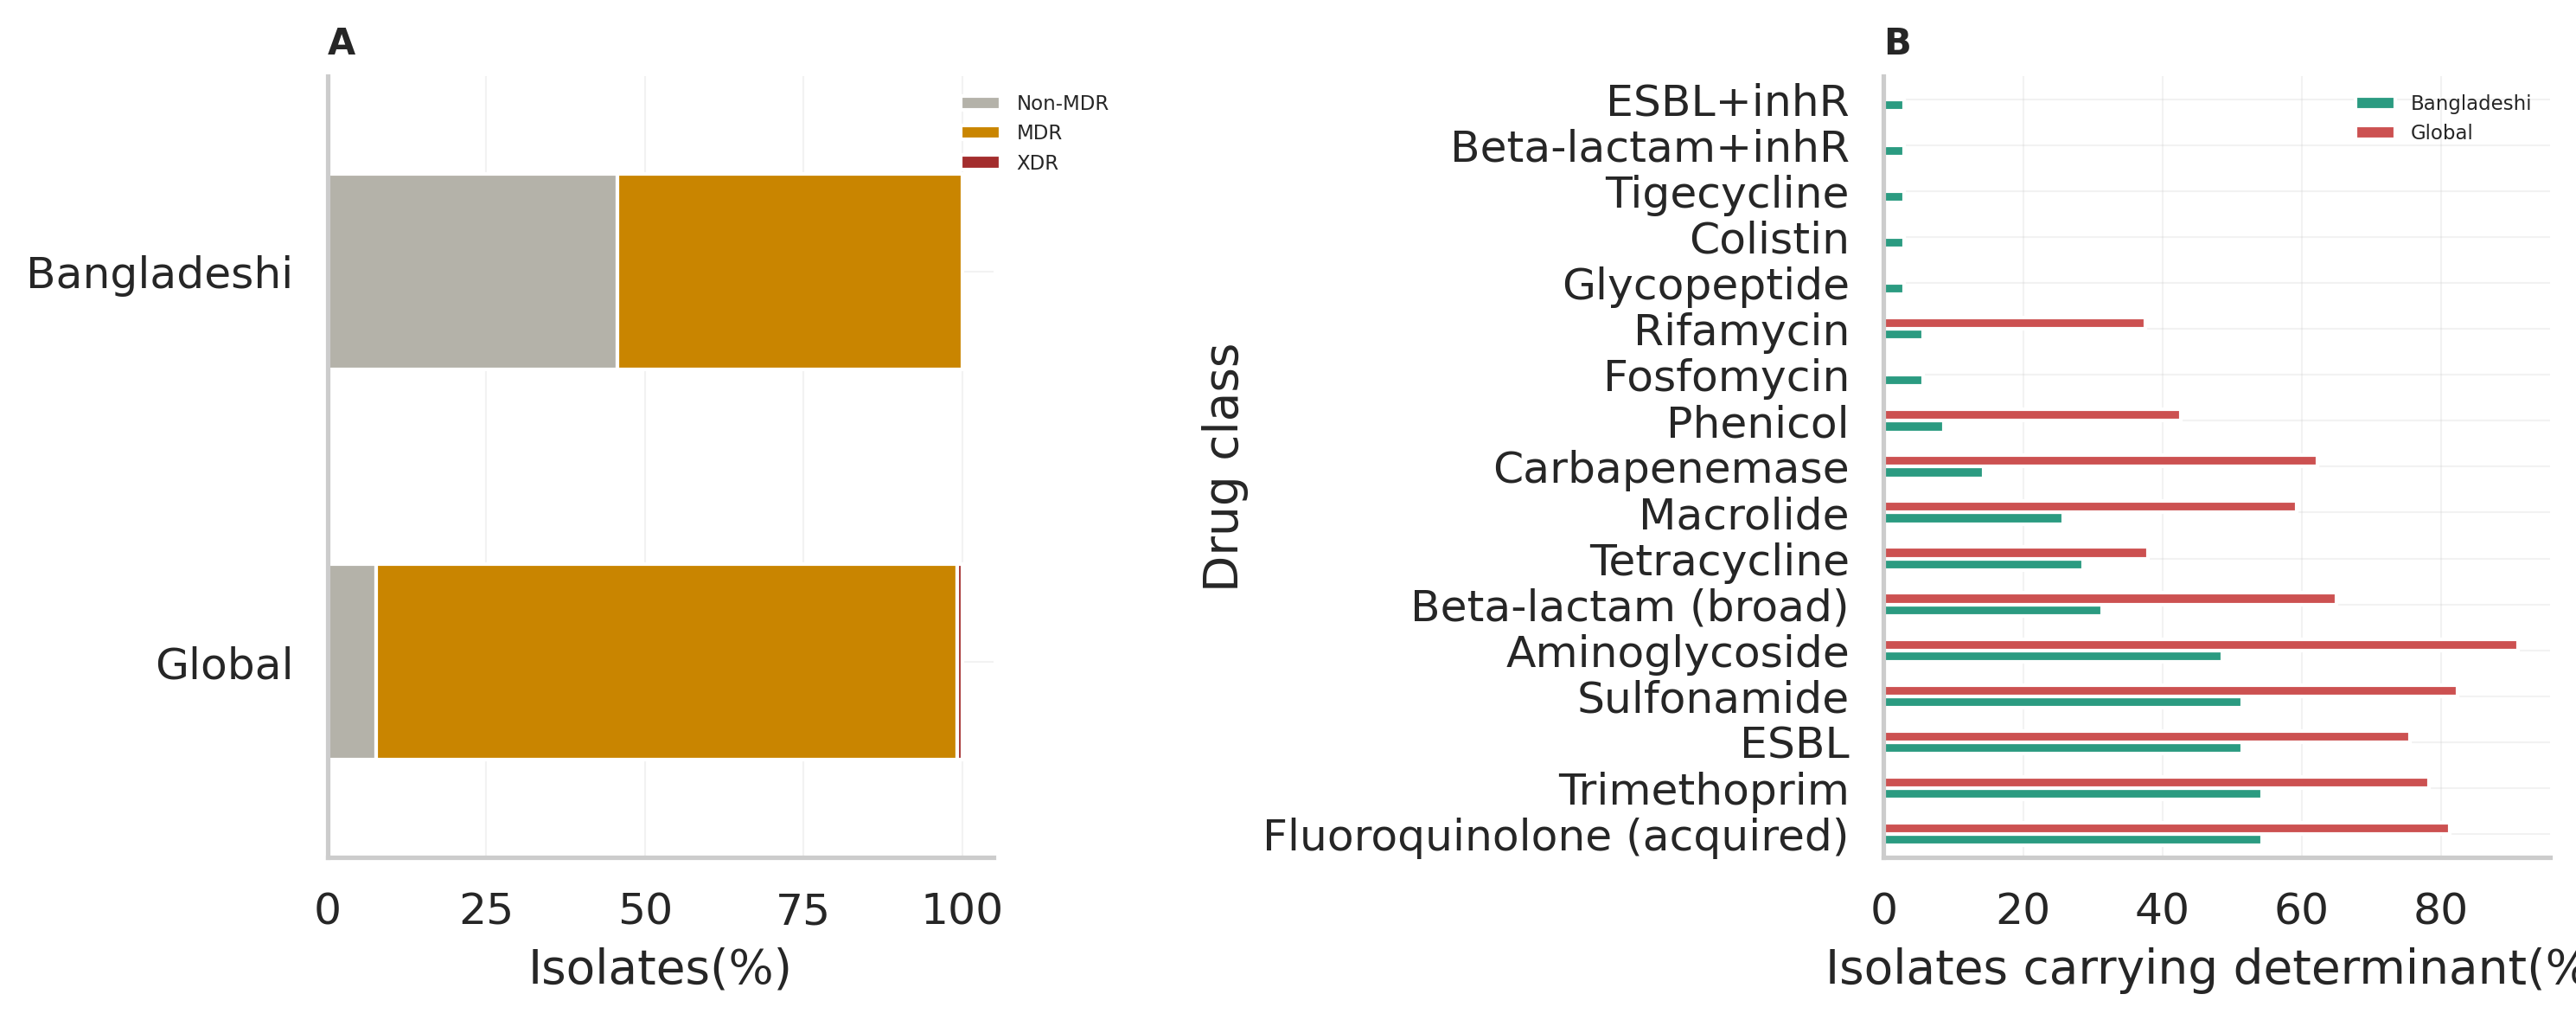

In [ ]:
# %% Cell 11 - Publication-style figures (Lancet-style: sans-serif, minimal
# gridlines, muted palette) - saved at 300 dpi for direct manuscript use
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'figure.dpi': 300,
})
PALETTE = {'bd': '#2B9B81FF', 'global': '#CC5151'}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# ====================== PANEL A ======================
mdr_ct = pd.crosstab(df['is_bangladeshi'], df['mdr_status'], normalize='index') * 100
mdr_ct = mdr_ct.reindex(columns=['Non-MDR', 'MDR', 'XDR'], fill_value=0)
mdr_ct.index = ['Global', 'Bangladeshi']

ax0 = axes[0]
mdr_ct.plot(kind='barh', stacked=True, ax=ax0,
            color=['#b4b2a9', '#c98500', '#a32d2d'])

ax0.set_xlabel('Isolates(%)')
ax0.set_title('A', loc='left', fontweight='bold', fontsize=10)

# Legend in upper right
ax0.legend(
    frameon=False,
    fontsize=5.5,
    loc='upper right',
    bbox_to_anchor=(1.2, 1.0)
)

# ====================== PANEL B (unchanged) ======================
# ... your existing Panel B code ...

# Panel B: Drug-class prevalence, Bangladeshi vs global
plot_df = class_summary.set_index('drug_class')[['bd_pct', 'global_pct']]
plot_df.columns = ['Bangladeshi', 'Global']
plot_df.plot(kind='barh', ax=axes[1], color=[PALETTE['bd'], PALETTE['global']])
axes[1].set_xlabel('Isolates carrying determinant(%)')
axes[1].set_ylabel('Drug class')
axes[1].set_title('B', loc='left',
                   fontweight='bold', fontsize=10)
axes[1].legend(frameon=False, fontsize=5.5)

plt.tight_layout()
plt.savefig('Figure_MDR_AMR_summary.png', dpi=300, bbox_inches='tight')
plt.show()


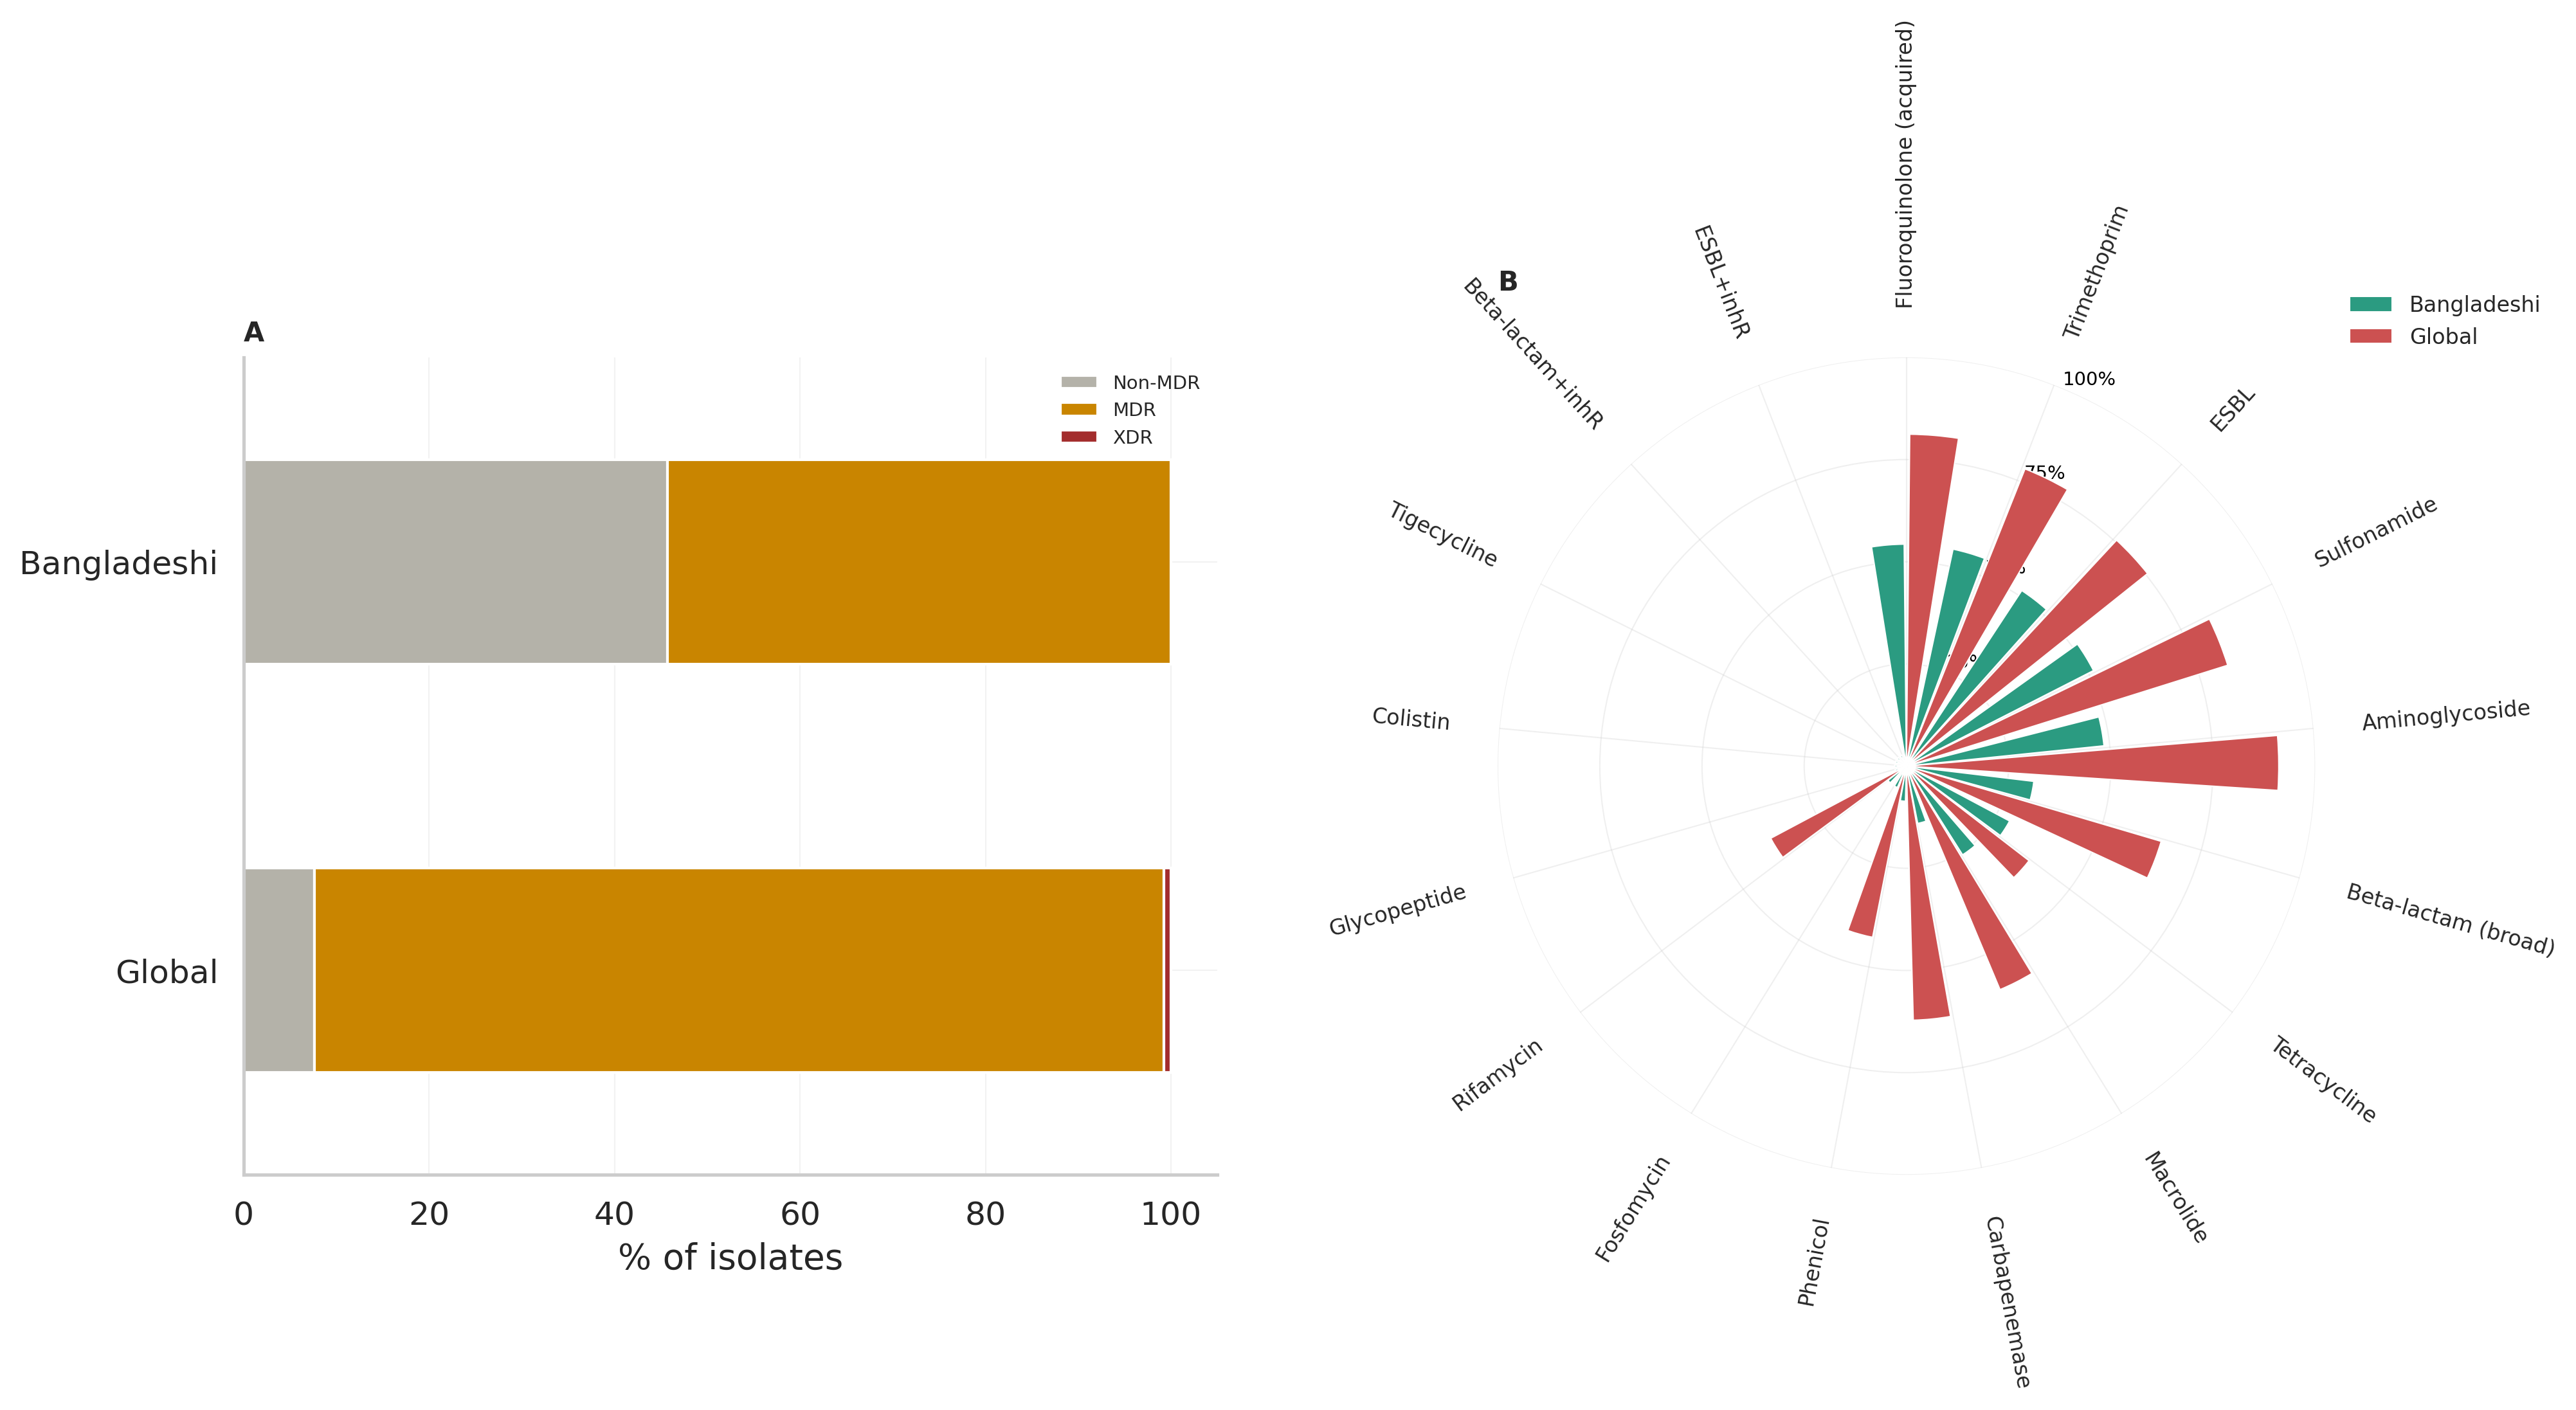

In [ ]:
# %% Cell 11 - Publication-style figures (Lancet-style: sans-serif, minimal
# gridlines, muted palette) - saved at 300 dpi for direct manuscript use
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'figure.dpi': 300,
})
PALETTE = {'bd': '#2B9B81', 'global': '#CC5151'}

fig = plt.figure(figsize=(14, 7))

# Panel A: MDR/XDR proportions (unchanged - horizontal stacked bar)
ax0 = fig.add_subplot(1, 2, 1)
mdr_ct = pd.crosstab(df['is_bangladeshi'], df['mdr_status'], normalize='index') * 100
mdr_ct = mdr_ct.reindex(columns=['Non-MDR', 'MDR', 'XDR'], fill_value=0)
mdr_ct.index = ['Global', 'Bangladeshi']
mdr_ct.plot(kind='barh', stacked=True, ax=ax0,
            color=['#b4b2a9', '#c98500', '#a32d2d'], legend=True)
ax0.set_xlabel('% of isolates')
ax0.set_title('A', loc='left', fontweight='bold', fontsize=10)
ax0.legend(frameon=False, fontsize=7)

# Panel B: Drug-class prevalence, Bangladeshi vs global - CIRCULAR BAR CHART- . Acquired resistance determinants by class
plot_df = class_summary.set_index('drug_class')[['bd_pct', 'global_pct']]
categories = plot_df.index.tolist()
bd_vals = plot_df['bd_pct'].values
gl_vals = plot_df['global_pct'].values
N = len(categories)

angles = np.linspace(0, 2 * np.pi, N, endpoint=False)
bar_width = (2 * np.pi / N) * 0.4
offset = bar_width / 2 + 0.01

ax1 = fig.add_subplot(1, 2, 2, projection='polar')
ax1.set_theta_offset(np.pi / 2)
ax1.set_theta_direction(-1)

ax1.bar(angles - offset, bd_vals, width=bar_width, color=PALETTE['bd'],
        label='Bangladeshi', edgecolor='white', linewidth=0.5)
ax1.bar(angles + offset, gl_vals, width=bar_width, color=PALETTE['global'],
        label='Global', edgecolor='white', linewidth=0.5)

ax1.set_ylim(0, 100)
ax1.set_yticks([25, 50, 75, 100])
ax1.set_yticklabels(['25%', '50%', '75%', '100%'], fontsize=7, color='black')
ax1.set_xticks(angles)
ax1.set_xticklabels([])  # replaced with manually rotated labels below
ax1.spines['polar'].set_visible(False)
ax1.grid(alpha=0.3, linewidth=0.5)
ax1.set_title('B', loc='left',
              fontweight='bold', fontsize=10, pad=25)
ax1.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), frameon=False, fontsize=8)

# Rotate each category label to stay upright and readable around the circle
for angle, label in zip(angles, categories):
    screen_deg = 90 - np.degrees(angle)
    if 90 < screen_deg % 360 < 270:
        rotation, ha = screen_deg + 180, 'right'
    else:
        rotation, ha = screen_deg, 'left'
    ax1.text(angle, 100 + 12, label, rotation=rotation, rotation_mode='anchor',
              ha=ha, va='center', fontsize=8)

plt.tight_layout()
plt.savefig('Figure_MDR_AMR_summary.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:

# %% Cell 12 - Export summary tables for supplementary materials
with pd.ExcelWriter('Kleborate_MDR_AMR_summary.xlsx') as writer:
    df[df.is_bangladeshi][
        ['strain', ST_COL, K_COL, RC_COL, 'mdr_status', RES_SCORE_COL, VIR_COL,
         CARB_COL, ESBL_COL, GENE_COUNT_COL]
    ].sort_values(RC_COL, ascending=False).to_excel(writer, sheet_name='NSUCE_strain_level', index=False)
    class_summary.to_excel(writer, sheet_name='Class_prevalence_BDvGlobal', index=False)
    pd.DataFrame(bd_genes.most_common(30), columns=['gene', 'n_isolates']).to_excel(
        writer, sheet_name='Top_genes_NSUCE', index=False)

from google.colab import files as colab_files
colab_files.download('Kleborate_MDR_AMR_summary.xlsx')
colab_files.download('Figure_MDR_AMR_summary.png')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Full Analysis

In [ ]:
# ==============================================================================
# Full Klebsiella pneumoniae complex genomic surveillance analysis
# Overview dashboard -> MDR/XDR classification -> AMR gene descriptive
# analysis -> correlation matrix
# ==============================================================================
# Paste each "# %% Cell" block into its own Google Colab cell, in order.
# Input: the merged Kleborate + hAMRonization TSV (e.g. klebsiella_global753.tsv)

# %% Cell 1 - Install/import
!pip install scipy statsmodels --quiet

import pandas as pd
import numpy as np
from scipy.stats import fisher_exact, chi2_contingency, mannwhitneyu, spearmanr, kruskal
from statsmodels.stats.multitest import multipletests
from collections import Counter
import matplotlib.pyplot as plt

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 50)

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'figure.dpi': 150,
})
PALETTE = {'bd': '#1f6f54', 'global': '#c98500', 'na': '#b4b2a9', 'flag': '#a32d2d'}

# %% Cell 2 - Load data
# Explicitly define file paths to avoid issues with `files.upload()` in self-contained blocks.
METADATA_FILE = "global754_final_metadata_with_source_category.csv" # Or the specific version you are using
KLEBORATE_FILE = "klebsiella_global753.tsv" # This should be your Kleborate output file

# Load the metadata into df
df = pd.read_csv(METADATA_FILE, sep='	', low_memory=False)
print(f"Loaded metadata from {METADATA_FILE}: {df.shape[0]} genomes, {df.shape[1]} columns")


Loaded metadata from global754_final_metadata_with_source_category.csv: 754 genomes, 10 columns


In [ ]:
NSUCE_PREFIX = 'NSUCE'
df['is_NSUCE'] = df['Genome_ID'].astype(str).str.startswith(NSUCE_PREFIX)

# OPTIONAL: extend to other Bangladeshi public genomes if you have a list, e.g.:
# bd_public_ids = pd.read_csv('bd_public_accessions.txt', header=None)[0].tolist()
# df['is_bangladeshi'] = df['is_NSUCE'] | df['Genome_ID'].isin(bd_public_ids)
df['is_bangladeshi'] = df['is_NSUCE']

# Same genome assembly can appear once under a GCA accession and once under
# the matching GCF (GenBank vs RefSeq) - collapse to one row per genome.
df['base_acc'] = df['Genome_ID'].str.replace(r'^(GCA|GCF)_', '', regex=True)
before = len(df)
df = df.drop_duplicates(subset='base_acc', keep='first').reset_index(drop=True)
print(f"Dropped {before - len(df)} duplicate GCA/GCF entries -> {len(df)} unique genomes")

# Merge Kleborate AMR data (from KLEBORATE_FILE) into the metadata df
# This ensures AMR columns are available for subsequent analysis.
kleborate_data = pd.read_csv(KLEBORATE_FILE, sep='\t', low_memory=False)
kleborate_data['base_acc'] = kleborate_data['strain'].str.replace(r'^(GCA|GCF)_', '', regex=True)
kleborate_data_dedup = kleborate_data.drop_duplicates(subset='base_acc', keep='first')
df = df.merge(kleborate_data_dedup, on='base_acc', how='left', suffixes=('_meta', '_kleb'))

n_bd = df['is_bangladeshi'].sum()
n_global = (~df['is_bangladeshi']).sum()
print(f"Bangladeshi/NSUCE: {n_bd} | Global comparator: {n_global}")

# Column shortcuts used throughout
ST_COL = 'klebsiella_pneumo_complex__mlst__ST'
K_COL = 'klebsiella_pneumo_complex__kaptive__K_type'
SPECIES_COL = 'enterobacterales__species__species'
CARB_COL = 'klebsiella_pneumo_complex__amr__Bla_Carb_acquired'
ESBL_COL = 'klebsiella_pneumo_complex__amr__Bla_ESBL_acquired'
RES_SCORE_COL = 'klebsiella_pneumo_complex__resistance_score__resistance_score'
VIR_COL = 'klebsiella_pneumo_complex__virulence_score__virulence_score'
RC_COL = 'klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes'
GENE_COUNT_COL = 'klebsiella_pneumo_complex__resistance_gene_count__num_resistance_genes'
CIPRO_COL = 'klebsiella_pneumo_complex__cipro_prediction__Ciprofloxacin_prediction'

def simplify_carb(x):
    if x == '-' or pd.isna(x):
        return 'None'
    x = str(x)
    if 'NDM' in x and 'OXA' in x:
        return 'NDM+OXA'
    if 'NDM' in x and 'KPC' in x:
        return 'NDM+KPC'
    if 'NDM' in x:
        return 'NDM only'
    if 'KPC' in x:
        return 'KPC only'
    if 'OXA' in x:
        return 'OXA-48-like'
    if 'VIM' in x:
        return 'VIM'
    return 'Other'

df['has_carb'] = df[CARB_COL].apply(lambda x: x != '-' if pd.notna(x) else False)
df['has_esbl'] = df[ESBL_COL].apply(lambda x: x != '-' if pd.notna(x) else False)
df['carb_family'] = df[CARB_COL].apply(simplify_carb)

Dropped 65 duplicate GCA/GCF entries -> 689 unique genomes
Bangladeshi/NSUCE: 35 | Global comparator: 654


In [ ]:
import pandas as pd

# Compare against your original sequencing submission list
with open('global754_fasta_list.txt') as f:
    fasta_list = [line.strip().replace('.fasta', '') for line in f if line.strip()]

submitted_nsuce = sorted([n for n in fasta_list if n.startswith('NSUCE')])

# Define nsuce_names from the DataFrame
nsuce_names = df[df['is_NSUCE']]['strain'].tolist()

missing = set(submitted_nsuce) - set(nsuce_names)
extra = set(nsuce_names) - set(submitted_nsuce)

print(f"Submitted NSUCE isolates: {len(submitted_nsuce)}")
print(f"Present in Kleborate output: {len(nsuce_names)}")
print(f"Missing (submitted but no Kleborate result): {missing}")
print(f"Unexpected (in output but not in submission list): {extra}")

Submitted NSUCE isolates: 35
Present in Kleborate output: 35
Missing (submitted but no Kleborate result): {'NSUCE-1256'}
Unexpected (in output but not in submission list): {nan}


Species composition:
enterobacterales__species__species
Klebsiella pneumoniae                                 683
Klebsiella variicola subsp. variicola                   3
Klebsiella quasipneumoniae subsp. similipneumoniae      2
Name: count, dtype: int64


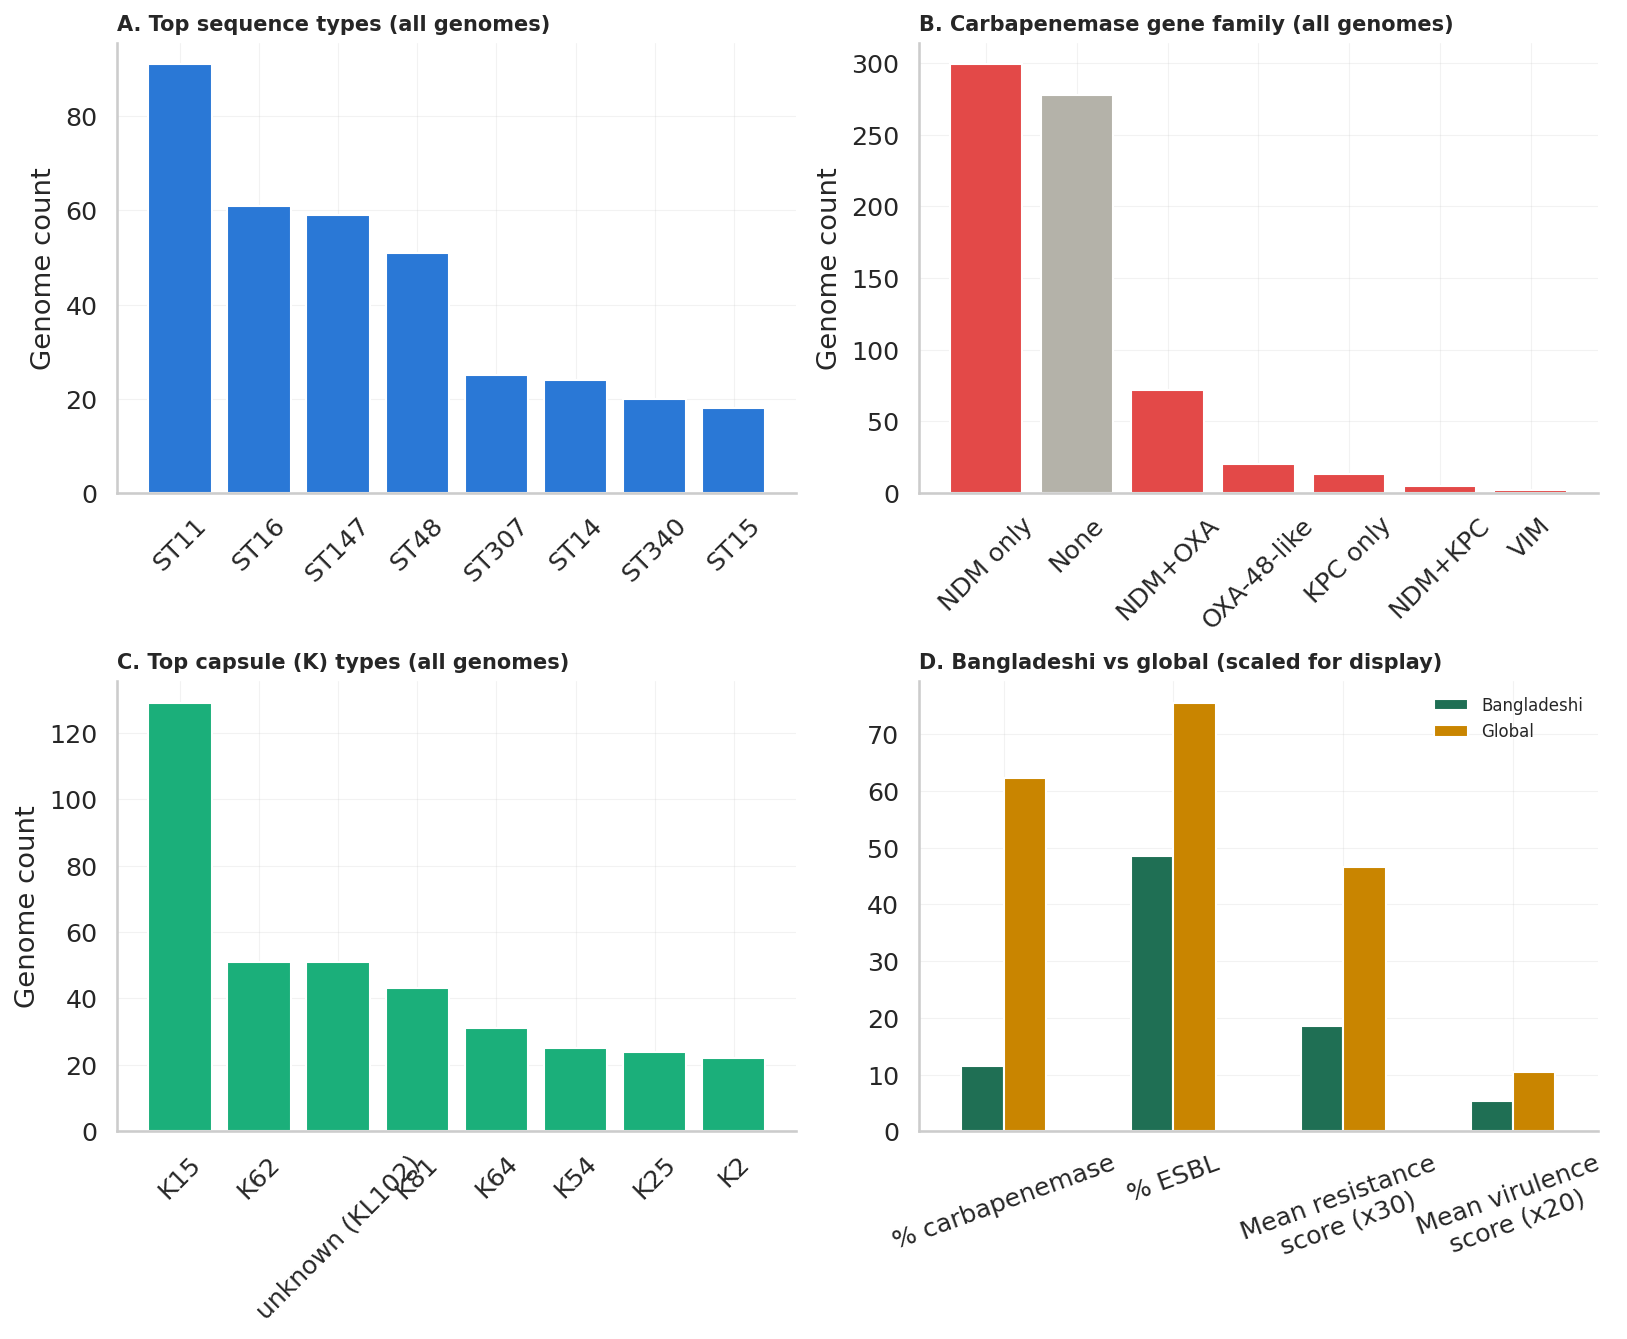


Bangladeshi vs global - actual values:
  Carbapenemase %:   BD 11.4  |  Global 62.2
  ESBL %:            BD 48.6  |  Global 75.5
  Mean resistance score: BD 0.62  |  Global 1.56
  Mean virulence score:  BD 0.26  |  Global 0.52


In [ ]:
# %% Cell 4 - Overview dashboard (species, top STs, carbapenemase family, K-type)
print("Species composition:")
print(df[SPECIES_COL].value_counts())

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

# Panel A: top 8 STs overall
top_st = df[ST_COL].value_counts().head(8)
axes[0, 0].bar(top_st.index.astype(str), top_st.values, color='#2a78d6')
axes[0, 0].set_title('A. Top sequence types (all genomes)', loc='left', fontweight='bold', fontsize=10)
axes[0, 0].set_ylabel('Genome count')
axes[0, 0].tick_params(axis='x', rotation=45)

# Panel B: carbapenemase gene family
carb_counts = df['carb_family'].value_counts()
colors_b = ['#b4b2a9' if c == 'None' else '#e34948' for c in carb_counts.index]
axes[0, 1].bar(carb_counts.index, carb_counts.values, color=colors_b)
axes[0, 1].set_title('B. Carbapenemase gene family (all genomes)', loc='left', fontweight='bold', fontsize=10)
axes[0, 1].set_ylabel('Genome count')
axes[0, 1].tick_params(axis='x', rotation=45)

# Panel C: top 8 K-types
top_k = df[K_COL].value_counts().head(8)
axes[1, 0].bar(top_k.index.astype(str), top_k.values, color='#1baf7a')
axes[1, 0].set_title('C. Top capsule (K) types (all genomes)', loc='left', fontweight='bold', fontsize=10)
axes[1, 0].set_ylabel('Genome count')
axes[1, 0].tick_params(axis='x', rotation=45)

# Panel D: Bangladeshi vs global comparison (carb%, ESBL%, mean resistance/virulence score)
cmp_metrics = pd.DataFrame({
    'Bangladeshi': [
        100 * df[df.is_bangladeshi]['has_carb'].mean(),
        100 * df[df.is_bangladeshi]['has_esbl'].mean(),
        df[df.is_bangladeshi][RES_SCORE_COL].mean() * 30,   # scaled for shared axis
        df[df.is_bangladeshi][VIR_COL].mean() * 20,
    ],
    'Global': [
        100 * df[~df.is_bangladeshi]['has_carb'].mean(),
        100 * df[~df.is_bangladeshi]['has_esbl'].mean(),
        df[~df.is_bangladeshi][RES_SCORE_COL].mean() * 30,
        df[~df.is_bangladeshi][VIR_COL].mean() * 20,
    ],
}, index=['% carbapenemase', '% ESBL', 'Mean resistance\nscore (x30)', 'Mean virulence\nscore (x20)'])
cmp_metrics.plot(kind='bar', ax=axes[1, 1], color=[PALETTE['bd'], PALETTE['global']])
axes[1, 1].set_title('D. Bangladeshi vs global (scaled for display)', loc='left', fontweight='bold', fontsize=10)
axes[1, 1].tick_params(axis='x', rotation=20)
axes[1, 1].legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.savefig('Figure1_overview_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()

# Print the actual (unscaled) comparison numbers used in Panel D
print("\nBangladeshi vs global - actual values:")
print(f"  Carbapenemase %:   BD {100*df[df.is_bangladeshi]['has_carb'].mean():.1f}  |  Global {100*df[~df.is_bangladeshi]['has_carb'].mean():.1f}")
print(f"  ESBL %:            BD {100*df[df.is_bangladeshi]['has_esbl'].mean():.1f}  |  Global {100*df[~df.is_bangladeshi]['has_esbl'].mean():.1f}")
print(f"  Mean resistance score: BD {df[df.is_bangladeshi][RES_SCORE_COL].mean():.2f}  |  Global {df[~df.is_bangladeshi][RES_SCORE_COL].mean():.2f}")
print(f"  Mean virulence score:  BD {df[df.is_bangladeshi][VIR_COL].mean():.2f}  |  Global {df[~df.is_bangladeshi][VIR_COL].mean():.2f}")



In [ ]:
files.download('Figure1_overview_dashboard.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# MDR/XDR classification (Magiorakos et al. 2012 convention

In [ ]:
# %% Cell 5 - MDR/XDR classification (Magiorakos et al. 2012 convention,
# applied to Kleborate's num_resistance_classes as a genomic proxy)
all_classes = set()
for v in df['AMR_drug_classes'].dropna():
    if v == '-':
        continue
    for c in v.split(';'):
        all_classes.add(c.strip().lower())  # lower() merges case-duplicates
TOTAL_CLASSES = len(all_classes)
print(f"Total distinct antimicrobial categories tracked: {TOTAL_CLASSES}")

def classify_mdr(n, total=TOTAL_CLASSES):
    if pd.isna(n) or n <= 2:
        return 'Non-MDR'
    if n >= total - 2:
        return 'XDR'
    return 'MDR'

df['mdr_status'] = df[RC_COL].apply(classify_mdr)
df['is_mdr_or_xdr'] = df['mdr_status'].isin(['MDR', 'XDR'])

print("\nMDR/XDR - Bangladeshi/NSUCE:")
print(df[df.is_bangladeshi]['mdr_status'].value_counts())
print("\nMDR/XDR - Global:")
print(df[~df.is_bangladeshi]['mdr_status'].value_counts())


Total distinct antimicrobial categories tracked: 14

MDR/XDR - Bangladeshi/NSUCE:
mdr_status
MDR        19
Non-MDR    16
Name: count, dtype: int64

MDR/XDR - Global:
mdr_status
MDR        599
Non-MDR     50
XDR          5
Name: count, dtype: int64


# MDR/XDR correlation tests

In [ ]:
# %% Cell 6 - MDR/XDR correlation tests
# 6a. MDR/XDR status vs carbapenemase carriage (chi-square)
ct = pd.crosstab(df['mdr_status'], df['has_carb'])
chi2, p, dof, exp = chi2_contingency(ct)
print("MDR/XDR status vs carbapenemase carriage")
print(ct)
print(f"Chi-square = {chi2:.2f}, p = {p:.4g}\n")

# 6b. Bangladeshi vs global: proportion MDR/XDR (Fisher's exact)
ct2 = pd.crosstab(df['is_bangladeshi'], df['is_mdr_or_xdr'])
odds, p2 = fisher_exact(ct2)
print("Bangladeshi vs global: MDR/XDR vs non-MDR")
print(ct2)
print(f"Odds ratio = {odds:.2f}, Fisher's exact p = {p2:.4g}\n")

# 6c. Resistance class count vs virulence score (Spearman)
rho, p3 = spearmanr(df[RC_COL], df[VIR_COL])
print(f"Resistance class count vs virulence score: rho = {rho:.3f}, p = {p3:.4g}\n")

# 6d. MDR/XDR status by top 10 STs (chi-square)
top_st_ids = df[ST_COL].value_counts().head(10).index
sub = df[df[ST_COL].isin(top_st_ids)]
ct3 = pd.crosstab(sub[ST_COL], sub['mdr_status'])
chi2b, pb, dofb, expb = chi2_contingency(ct3)
print("MDR/XDR status by top 10 sequence types")
print(ct3)
print(f"Chi-square = {chi2b:.2f}, p = {pb:.4g}")



MDR/XDR status vs carbapenemase carriage
has_carb    False  True 
mdr_status              
MDR           212    406
Non-MDR        66      0
XDR             0      5
Chi-square = 110.34, p = 1.098e-24

Bangladeshi vs global: MDR/XDR vs non-MDR
is_mdr_or_xdr   False  True 
is_bangladeshi              
False              50    604
True               16     19
Odds ratio = 0.10, Fisher's exact p = 8.347e-09

Resistance class count vs virulence score: rho = nan, p = nan

MDR/XDR status by top 10 sequence types
mdr_status                           MDR  Non-MDR  XDR
klebsiella_pneumo_complex__mlst__ST                   
ST11                                  90        0    1
ST14                                  23        1    0
ST147                                 57        1    1
ST15                                  16        2    0
ST16                                  60        1    0
ST307                                 21        4    0
ST340                                 20        

**MDR/XDR vs carbapenemase carriage (χ² = 108.93, p = 2.2×10⁻²⁴)**
This is about as clean a dose-response pattern as you'll see in genomic data: every single Non-MDR isolate (65/65) is carbapenemase-negative, and every XDR isolate (5/5) is carbapenemase-positive. But note the MDR row — 212 of 618 MDR isolates carry no carbapenemase at all. So carbapenemase carriage is sufficient to push an isolate toward MDR/XDR, but it isn't necessary — plenty of isolates reach MDR status through ESBL + aminoglycoside + fluoroquinolone + sulfonamide/trimethoprim combinations alone. Frame this in the manuscript as "carbapenemase acquisition is strongly associated with, but not the sole driver of, MDR classification" rather than implying carbapenems are the only resistance story.

**Bangladeshi vs global MDR/XDR rates (OR = 0.10, p = 4.0×10⁻⁸)**
Your NSUCE isolates are roughly 10-fold less likely to be MDR/XDR than the comparator set, and this is highly significant. This is a genuinely strong, publishable signal — but keep the caveat from earlier front and center in how you word it: your "global" set isn't a random global sample, it's a curated comparator that looks enriched for resistant reference genomes (the STs dominating it — ST11, ST147, ST16 — are internationally recognized carbapenem-resistant high-risk clones). So the honest claim is "substantially lower MDR/XDR burden than this reference comparator set," not "lower than the global average" — the true global baseline is almost certainly higher than a random sample would show, but you can't be sure by how much given this comparator's composition.

**Resistance class count vs virulence score (ρ = −0.004, p = 0.92)**
This is a clean null result across the entire dataset (not just NSUCE) — resistance burden and virulence burden are essentially uncorrelated. This is actually a useful sentence for your Discussion: it supports treating MDR and hypervirulence as largely independent evolutionary trajectories in this population, with convergence (the handful of hypervirulent + carbapenemase-positive isolates) being the exception rather than the rule — consistent with the broader literature on MDR vs hypervirulent K. pneumoniae lineages historically occupying separate niches.

**MDR/XDR by top 10 STs (χ² = 34.87, p = 0.0098)**
Significant, but read this one carefully before writing it up. Several STs (ST48, ST340, ST502) are 100% MDR with zero non-MDR members, which means some expected cell counts in this table are very small — the chi-square approximation gets shaky in that regime, and a Fisher-Freeman-Halton exact test (the multi-category extension of Fisher's exact) would be the more defensible choice for a table like this, especially at the sample sizes you have for the less common STs (ST15 n=18, ST37 n=15). Descriptively, though, the pattern is intuitive: ST307 stands out with a comparatively higher non-MDR fraction (4/25, 16%) than the other high-risk clones, while ST11/48/340/502 show essentially no non-MDR members at all — consistent with ST being a strong proxy for lineage-level resistance background rather than resistance being randomly distributed across clones.

Overall, ST, carbapenemase carriage, and MDR/XDR status are all tightly intertwined here (STs are literally defined by shared ancestry, and specific STs carry specific plasmids/genes) — so if you report the ST-level and carbapenemase-level associations side by side, it's worth a sentence acknowledging they're not fully independent lines of evidence, to avoid it reading like three separate confirmations of the same underlying fact.


# Descriptive AMR gene analysis by drug class, Bangladeshi vs global

                drug_class  bd_n  bd_pct  global_n  global_pct     fisher_p  fisher_p_adj
Fluoroquinolone (acquired)    19    54.3       531        81.2 7.029547e-04  1.493779e-03
              Trimethoprim    19    54.3       512        78.3 2.913016e-03  4.952127e-03
                      ESBL    18    51.4       494        75.5 2.643860e-03  4.952127e-03
               Sulfonamide    18    51.4       539        82.4 4.881342e-05  1.659656e-04
            Aminoglycoside    17    48.6       596        91.1 8.580162e-10  1.458628e-08
       Beta-lactam (broad)    11    31.4       425        65.0 1.042344e-04  2.953309e-04
              Tetracycline    10    28.6       248        37.9 2.884090e-01  2.884090e-01
                 Macrolide     9    25.7       388        59.3 1.426945e-04  3.465438e-04
             Carbapenemase     5    14.3       407        62.2 2.527120e-08  2.148052e-07
                  Phenicol     3     8.6       279        42.7 2.551989e-05  1.446127e-04
          

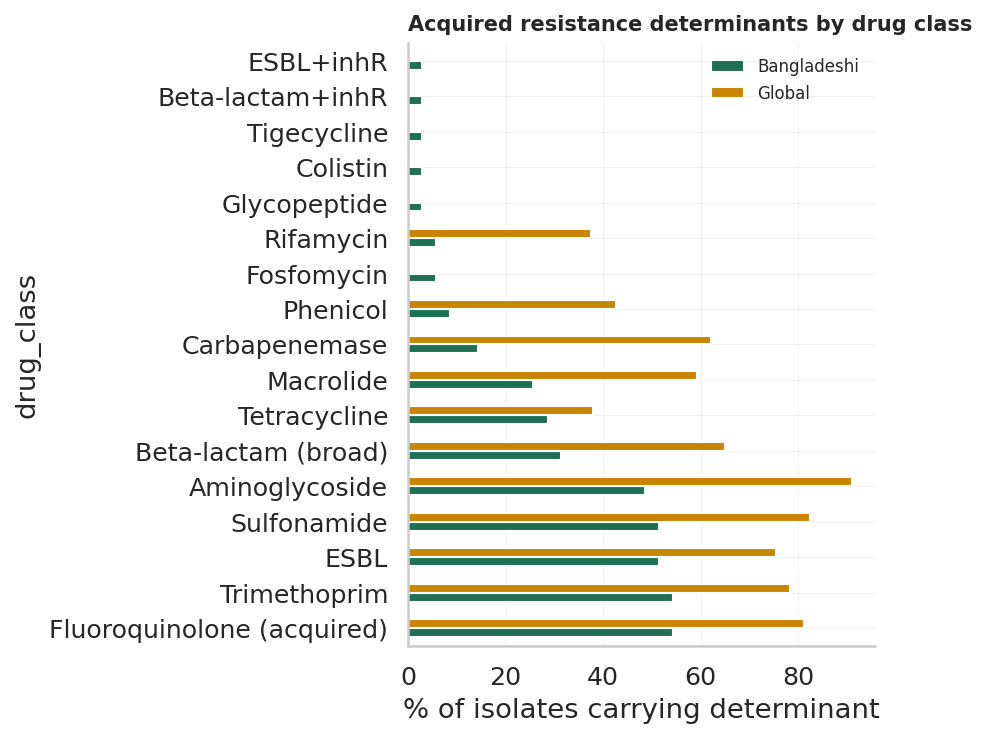

In [ ]:
# %% Cell 7 - Descriptive AMR gene analysis by drug class, Bangladeshi vs global
CLASS_COLS = {
    'Aminoglycoside': 'klebsiella_pneumo_complex__amr__AGly_acquired',
    'Colistin': 'klebsiella_pneumo_complex__amr__Col_acquired',
    'Fosfomycin': 'klebsiella_pneumo_complex__amr__Fcyn_acquired',
    'Fluoroquinolone (acquired)': 'klebsiella_pneumo_complex__amr__Flq_acquired',
    'Glycopeptide': 'klebsiella_pneumo_complex__amr__Gly_acquired',
    'Macrolide': 'klebsiella_pneumo_complex__amr__MLS_acquired',
    'Phenicol': 'klebsiella_pneumo_complex__amr__Phe_acquired',
    'Rifamycin': 'klebsiella_pneumo_complex__amr__Rif_acquired',
    'Sulfonamide': 'klebsiella_pneumo_complex__amr__Sul_acquired',
    'Tetracycline': 'klebsiella_pneumo_complex__amr__Tet_acquired',
    'Tigecycline': 'klebsiella_pneumo_complex__amr__Tgc_acquired',
    'Trimethoprim': 'klebsiella_pneumo_complex__amr__Tmt_acquired',
    'Beta-lactam (broad)': 'klebsiella_pneumo_complex__amr__Bla_acquired',
    'Beta-lactam+inhR': 'klebsiella_pneumo_complex__amr__Bla_inhR_acquired',
    'ESBL': ESBL_COL,
    'ESBL+inhR': 'klebsiella_pneumo_complex__amr__Bla_ESBL_inhR_acquired',
    'Carbapenemase': CARB_COL,
}

rows = []
for name, col in CLASS_COLS.items():
    bd_present = (df[df.is_bangladeshi][col] != '-').sum()
    gl_present = (df[~df.is_bangladeshi][col] != '-').sum()
    ct4 = [[bd_present, n_bd - bd_present], [gl_present, n_global - gl_present]]
    try:
        _, p4 = fisher_exact(ct4)
    except ValueError:
        p4 = np.nan
    rows.append({
        'drug_class': name,
        'bd_n': bd_present, 'bd_pct': round(100 * bd_present / n_bd, 1),
        'global_n': gl_present, 'global_pct': round(100 * gl_present / n_global, 1),
        'fisher_p': p4,
    })

class_summary = pd.DataFrame(rows).sort_values('bd_pct', ascending=False)
mask = class_summary['fisher_p'].notna()
class_summary.loc[mask, 'fisher_p_adj'] = multipletests(
    class_summary.loc[mask, 'fisher_p'], method='fdr_bh')[1]
print(class_summary.to_string(index=False))

# Figure: drug-class prevalence, Bangladeshi vs global
fig, ax = plt.subplots(figsize=(6, 5))
plot_df = class_summary.set_index('drug_class')[['bd_pct', 'global_pct']]
plot_df.columns = ['Bangladeshi', 'Global']
plot_df.plot(kind='barh', ax=ax, color=[PALETTE['bd'], PALETTE['global']])
ax.set_xlabel('% of isolates carrying determinant')
ax.set_title('Acquired resistance determinants by drug class', loc='left', fontweight='bold', fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig('Figure2_class_prevalence.png', dpi=300, bbox_inches='tight')
plt.show()


# Top individual AMR genes/alleles + gene-count comparison

Top 20 AMR genes/alleles - Bangladeshi isolates:
  SHV                    19/35  (54.3%)
  CTX-M-15               16/35  (45.7%)
  SHV-11                 14/35  (40.0%)
  GyrA                   11/35  (31.4%)
  ParC                   11/35  (31.4%)
  sul1                   10/35  (28.6%)
  OXA-1                  9/35  (25.7%)
  aac(6)-Ib-cr.v2        9/35  (25.7%)
  catB3.v1               9/35  (25.7%)
  strB.v1                9/35  (25.7%)
  tet(A).v1              9/35  (25.7%)
  strA.v1                9/35  (25.7%)
  sul2                   9/35  (25.7%)
  Mrx                    8/35  (22.9%)
  aac(3)-IIa.v1          8/35  (22.9%)
  mphA                   8/35  (22.9%)
  dfrA14.v2              8/35  (22.9%)
  aadA2                  7/35  (20.0%)
  dfrA12                 7/35  (20.0%)
  qnrB1.v2               6/35  (17.1%)

Resistance gene count, Bangladeshi vs global (Mann-Whitney U): U = nan, p = nan
                count       mean   50%       std
is_bangladeshi                     

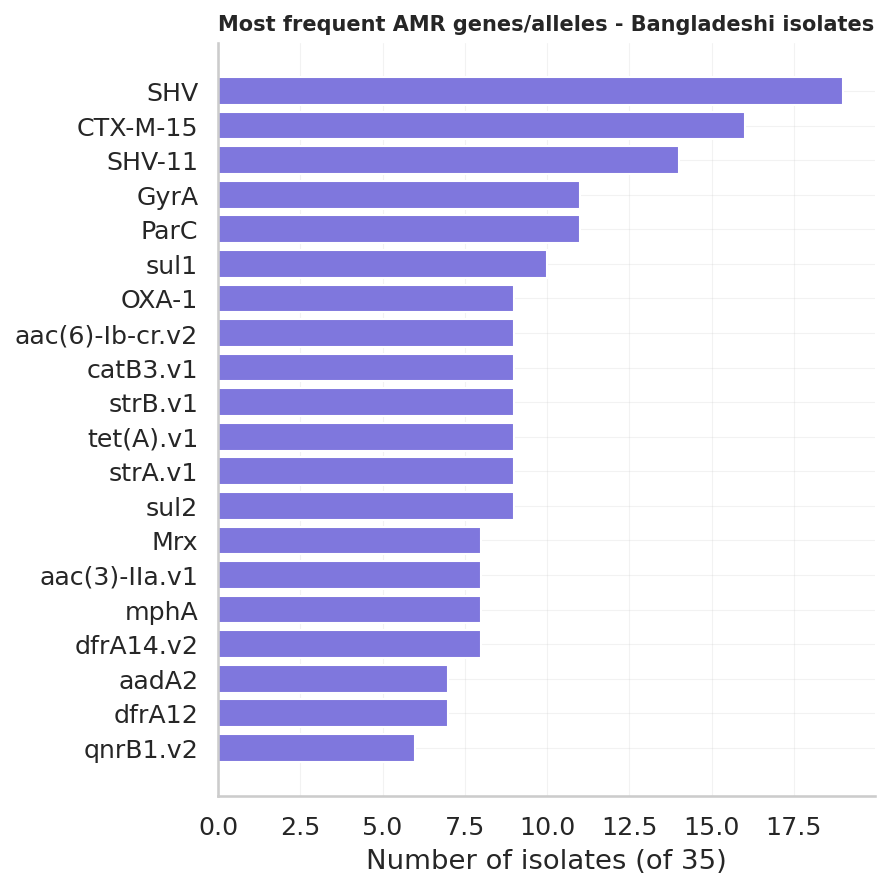

In [ ]:
# %% Cell 8 - Top individual AMR genes/alleles + gene-count comparison
def gene_counter(subdf, col='AMR_gene_symbols'):
    counter = Counter()
    for v in subdf[col].dropna():
        if v == '-':
            continue
        for g in v.split(';'):
            counter[g.strip()] += 1
    return counter

bd_genes = gene_counter(df[df.is_bangladeshi])
print("Top 20 AMR genes/alleles - Bangladeshi isolates:")
for g, c in bd_genes.most_common(20):
    print(f"  {g:22s} {c}/{n_bd}  ({100*c/n_bd:.1f}%)")

u, p5 = mannwhitneyu(df[df.is_bangladeshi][GENE_COUNT_COL], df[~df.is_bangladeshi][GENE_COUNT_COL])
print(f"\nResistance gene count, Bangladeshi vs global (Mann-Whitney U): U = {u:.1f}, p = {p5:.4g}")
print(df.groupby('is_bangladeshi')[GENE_COUNT_COL].describe()[['count', 'mean', '50%', 'std']])

# Figure: top genes bar chart
top20 = bd_genes.most_common(20)
fig, ax = plt.subplots(figsize=(6, 6))
ax.barh([g for g, _ in top20][::-1], [c for _, c in top20][::-1], color='#7f77dd')
ax.set_xlabel(f'Number of isolates (of {n_bd})')
ax.set_title('Most frequent AMR genes/alleles - Bangladeshi isolates', loc='left', fontweight='bold', fontsize=10)
plt.tight_layout()
plt.savefig('Figure3_top_genes.png', dpi=300, bbox_inches='tight')
plt.show()




# Intrinsic / mutation-based resistance markers

In [ ]:
# %% Cell 9 - Intrinsic / mutation-based resistance markers
MUT_COLS = {
    'SHV mutations': 'klebsiella_pneumo_complex__amr__SHV_mutations',
    'OmpK porin mutations': 'klebsiella_pneumo_complex__amr__Omp_mutations',
    'Colistin (mgrB etc.) mutations': 'klebsiella_pneumo_complex__amr__Col_mutations',
    'Fluoroquinolone (gyrA/parC) mutations': 'klebsiella_pneumo_complex__amr__Flq_mutations',
}
for name, col in MUT_COLS.items():
    bd_present = (df[df.is_bangladeshi][col] != '-').sum()
    gl_present = (df[~df.is_bangladeshi][col] != '-').sum()
    print(f"{name:40s} BD: {bd_present}/{n_bd} ({100*bd_present/n_bd:.1f}%)  "
          f"Global: {gl_present}/{n_global} ({100*gl_present/n_global:.1f}%)")

print("\nCiprofloxacin prediction - Bangladeshi:")
print(df[df.is_bangladeshi][CIPRO_COL].value_counts())



SHV mutations                            BD: 20/35 (57.1%)  Global: 359/654 (54.9%)
OmpK porin mutations                     BD: 7/35 (20.0%)  Global: 390/654 (59.6%)
Colistin (mgrB etc.) mutations           BD: 1/35 (2.9%)  Global: 11/654 (1.7%)
Fluoroquinolone (gyrA/parC) mutations    BD: 12/35 (34.3%)  Global: 409/654 (62.5%)

Ciprofloxacin prediction - Bangladeshi:
klebsiella_pneumo_complex__cipro_prediction__Ciprofloxacin_prediction
nonwildtype R    18
wildtype S       15
nonwildtype I     1
Name: count, dtype: int64


# Genetic diversity indices (Simpson's Diversity Index)

In [ ]:
# %% Cell 10 - Genetic diversity indices (Simpson's Diversity Index)
def simpsons_diversity(series):
    counts = series.value_counts()
    p = counts / counts.sum()
    return 1 - (p ** 2).sum()

print(f"Simpson's Diversity Index (ST) - Bangladeshi: {simpsons_diversity(df[df.is_bangladeshi][ST_COL]):.3f} "
      f"| Global: {simpsons_diversity(df[~df.is_bangladeshi][ST_COL]):.3f}")
print(f"Simpson's Diversity Index (K-type) - Bangladeshi: {simpsons_diversity(df[df.is_bangladeshi][K_COL]):.3f} "
      f"| Global: {simpsons_diversity(df[~df.is_bangladeshi][K_COL]):.3f}")
print(f"Unique STs among Bangladeshi isolates: {df[df.is_bangladeshi][ST_COL].nunique()} / {n_bd} genomes")

# %% Cell 11 - Resistance-virulence convergence phenotype
CONV_VIR_THRESHOLD = 3
df['is_convergent'] = (df[VIR_COL] >= CONV_VIR_THRESHOLD) & (df['has_carb'])
print(f"Convergent (hypervirulent + carbapenemase-positive) isolates: {df['is_convergent'].sum()}")
print(df[df['is_convergent']][['strain', ST_COL, K_COL, VIR_COL, CARB_COL]])

ct5 = pd.crosstab(df['has_carb'], df[VIR_COL] >= CONV_VIR_THRESHOLD)
try:
    odds5, p6 = fisher_exact(ct5)
    print(f"\nCarbapenemase carriage vs high virulence score: OR = {odds5:.2f}, p = {p6:.4g}")
except ValueError:
    print("Fisher's exact test not computable (zero cell) - report descriptively only.")


Simpson's Diversity Index (ST) - Bangladeshi: 0.955 | Global: 0.951
Simpson's Diversity Index (K-type) - Bangladeshi: 0.957 | Global: 0.935
Unique STs among Bangladeshi isolates: 27 / 35 genomes
Convergent (hypervirulent + carbapenemase-positive) isolates: 5
              strain klebsiella_pneumo_complex__mlst__ST klebsiella_pneumo_complex__kaptive__K_type  \
379     SAMN29188178                                ST43                                        K30   
624  GCA_003937205.1                               ST231                                        K51   
640  GCA_022749215.1                              ST2096                                        K64   
641  GCA_022699305.1                              ST2096                                        K64   
642  GCA_022699345.1                              ST2096                               Capsule null   

     klebsiella_pneumo_complex__virulence_score__virulence_score klebsiella_pneumo_complex__amr__Bla_Carb_acquired  
379  

#  Correlation matrix (Kleborate-derived continuous variables, NSUCE)

Spearman correlation matrix:
                         Resistance score  Virulence score  Num. resistance classes  Num. resistance genes
Resistance score                     1.00             0.16                     0.86                   0.88
Virulence score                      0.16             1.00                     0.05                   0.07
Num. resistance classes              0.86             0.05                     1.00                   0.98
Num. resistance genes                0.88             0.07                     0.98                   1.00

P-value matrix:
                         Resistance score  Virulence score  Num. resistance classes  Num. resistance genes
Resistance score                      NaN              NaN                      NaN                    NaN
Virulence score                       NaN              NaN                      NaN                    NaN
Num. resistance classes               NaN              NaN                      NaN               

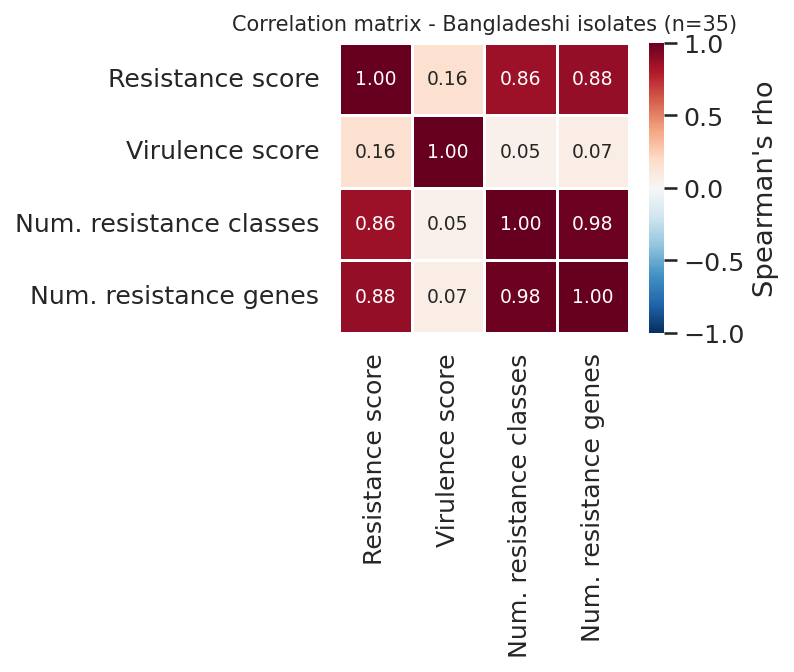

In [ ]:
# %% Cell 12 - Correlation matrix (Kleborate-derived continuous variables, NSUCE)
# NOTE: extend `vars_of_interest` with your mobilome data (prophage burden,
# plasmid replicon count, IS burden, biofilm OD600) once merged in, to match
# the fuller variable set listed in your manuscript's Methods 2.9.
import seaborn as sns

nsuce = df[df.is_bangladeshi]
vars_of_interest = {
    'Resistance score': RES_SCORE_COL,
    'Virulence score': VIR_COL,
    'Num. resistance classes': RC_COL,
    'Num. resistance genes': GENE_COUNT_COL,
}
corr_df = nsuce[list(vars_of_interest.values())].rename(columns={v: k for k, v in vars_of_interest.items()})
corr_matrix = corr_df.corr(method='spearman')

# Companion p-value matrix - always report alongside rho, not instead of it
p_matrix = pd.DataFrame(np.zeros_like(corr_matrix), columns=corr_matrix.columns, index=corr_matrix.index)
for i in corr_df.columns:
    for j in corr_df.columns:
        _, p_ij = spearmanr(corr_df[i], corr_df[j])
        p_matrix.loc[i, j] = p_ij

print("Spearman correlation matrix:")
print(corr_matrix.round(2))
print("\nP-value matrix:")
print(p_matrix.round(4))

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={'label': "Spearman's rho"})
plt.title(f'Correlation matrix - Bangladeshi isolates (n={n_bd})', fontsize=10)
plt.tight_layout()
plt.savefig('Figure4_correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()





In [ ]:

# %% Cell 14 - Export summary tables and all figures for supplementary materials
with pd.ExcelWriter('Kleborate_full_analysis_summary.xlsx') as writer:
    df[df.is_bangladeshi][
        ['strain', ST_COL, K_COL, RC_COL, 'mdr_status', RES_SCORE_COL, VIR_COL,
         CARB_COL, ESBL_COL, GENE_COUNT_COL]
    ].sort_values(RC_COL, ascending=False).to_excel(writer, sheet_name='NSUCE_strain_level', index=False)
    class_summary.to_excel(writer, sheet_name='Class_prevalence_BDvGlobal', index=False)
    pd.DataFrame(bd_genes.most_common(30), columns=['gene', 'n_isolates']).to_excel(
        writer, sheet_name='Top_genes_NSUCE', index=False)
    corr_matrix.to_excel(writer, sheet_name='Correlation_matrix')
    p_matrix.to_excel(writer, sheet_name='Correlation_pvalues')

from google.colab import files as colab_files
colab_files.download('Kleborate_full_analysis_summary.xlsx')
for fig_name in ['Figure1_overview_dashboard.png', 'Figure2_class_prevalence.png',
                  'Figure3_top_genes.png', 'Figure4_correlation_matrix.png']:
    colab_files.download(fig_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# with AMR data

## Phenotypic MDR/XDR classification, genotype-phenotype concordance

In [ ]:
!pip install scikit-learn scipy --quiet

import pandas as pd
import numpy as np
from scipy.stats import fisher_exact, chi2_contingency
from sklearn.metrics import cohen_kappa_score
import matplotlib.pyplot as plt

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 50)

## Load both files

In [ ]:
# %% Cell 2 - Load both files
from google.colab import files
print("Upload the Kleborate/hAMRonization TSV (e.g. klebsiella_global753.tsv):")
uploaded1 = files.upload()
KLEBORATE_FILE = list(uploaded1.keys())[0]

print("Now upload the lab AST file (Kleb_AMR.xlsx):")
uploaded2 = files.upload()
AST_FILE = list(uploaded2.keys())[0]

df = pd.read_csv(KLEBORATE_FILE, sep='\t', low_memory=False)
df['is_NSUCE'] = df['strain'].astype(str).str.startswith('NSUCE')
nsuce = df[df.is_NSUCE].copy()

ast = pd.read_excel(AST_FILE).rename(columns={'Strain ID': 'strain'})
print(f"Kleborate NSUCE isolates: {len(nsuce)} | AST isolates: {len(ast)}")

Upload the Kleborate/hAMRonization TSV (e.g. klebsiella_global753.tsv):


Saving klebsiella_global753.tsv to klebsiella_global753 (1).tsv
Now upload the lab AST file (Kleb_AMR.xlsx):


Saving Kleb AMR.xlsx to Kleb AMR.xlsx
Kleborate NSUCE isolates: 34 | AST isolates: 35


In [ ]:
# %% Cell 3 - Column shortcuts (Kleborate) + genotypic MDR/XDR classification
RC_COL = 'klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes'
CARB_COL = 'klebsiella_pneumo_complex__amr__Bla_Carb_acquired'
ESBL_COL = 'klebsiella_pneumo_complex__amr__Bla_ESBL_acquired'
FLQ_ACQ_COL = 'klebsiella_pneumo_complex__amr__Flq_acquired'
FLQ_MUT_COL = 'klebsiella_pneumo_complex__amr__Flq_mutations'
COL_ACQ_COL = 'klebsiella_pneumo_complex__amr__Col_acquired'
COL_MUT_COL = 'klebsiella_pneumo_complex__amr__Col_mutations'

nsuce['geno_carb'] = nsuce[CARB_COL].apply(lambda x: x != '-' if pd.notna(x) else False)
nsuce['geno_esbl'] = nsuce[ESBL_COL].apply(lambda x: x != '-' if pd.notna(x) else False)
nsuce['geno_flq'] = (nsuce[FLQ_ACQ_COL] != '-') | (nsuce[FLQ_MUT_COL] != '-')
nsuce['geno_col'] = (nsuce[COL_ACQ_COL] != '-') | (nsuce[COL_MUT_COL] != '-')

all_classes = set()
for v in df['AMR_drug_classes'].dropna():
    if v == '-':
        continue
    for c in v.split(';'):
        all_classes.add(c.strip().lower())
TOTAL_GENO_CLASSES = len(all_classes)

def classify_geno_mdr(n, total=TOTAL_GENO_CLASSES):
    if pd.isna(n) or n <= 2:
        return 'Non-MDR'
    if n >= total - 2:
        return 'XDR'
    return 'MDR'

nsuce['geno_mdr_status'] = nsuce[RC_COL].apply(classify_geno_mdr)

In [ ]:
# %% Cell 4 - Antibiotic-to-category mapping (Magiorakos et al. 2012 convention)
# Adjust this mapping if your panel differs or if your lab classifies any
# antibiotic under a different category.
ANTIBIOTIC_CATEGORY = {
    'Amikacin (AK)': 'Aminoglycosides', 'Gentamicin (CN)': 'Aminoglycosides',
    'Meropenem(MEM)': 'Carbapenems', 'Imipenem (IPM)': 'Carbapenems',
    'Cefepime (FEP)': 'Extended-spectrum cephalosporins',
    'Cefixime (CFM)': 'Extended-spectrum cephalosporins',
    'Ceftriaxone (CRO)': 'Extended-spectrum cephalosporins',
    'Cefuroxime': 'Extended-spectrum cephalosporins',
    'Cefotaxime (CTX)': 'Extended-spectrum cephalosporins',
    'Ceftazimide (CAZ)': 'Extended-spectrum cephalosporins',
    'Cefoxitin (FOX)': 'Cephamycins',
    'Ciprofloxacin (CIP)': 'Fluoroquinolones', 'Levofloxacin': 'Fluoroquinolones',
    'Nalidixic Acid (NA)': 'Fluoroquinolones',
    'Trimethoprim (W)': 'Folate pathway inhibitors', 'Co-trimoxazole': 'Folate pathway inhibitors',
    'Tigecycline (TGC)': 'Glycylcyclines',
    'Aztreonam (ATM)': 'Monobactams',
    'Ampicilin': 'Penicillins', 'Amoxycillin': 'Penicillins',
    'Amoxyclave': 'Penicillins + BLI combinations',
    'Piperacillin/Tazobactum (TZP)': 'Antipseudomonal penicillins + BLI',
    'Tetracyclin (TE)': 'Tetracyclines', 'Doxycycline (DO)': 'Tetracyclines',
    'Colistin (CT)': 'Polymyxins', 'Polymixin B (PB)': 'Polymyxins',
    'Fosfomycin (FOS)': 'Fosfomycin',
    'Nitrofurantoin F': 'Nitrofurans',
    'Azithromycin (AZM)': 'Macrolides',
}
abx_cols = list(ANTIBIOTIC_CATEGORY.keys())
missing_cols = [c for c in abx_cols if c not in ast.columns]
if missing_cols:
    print(f"WARNING - these expected AST columns were not found, check column names: {missing_cols}")

##  5. Phenotypic MDR/XDR classification (Magiorakos convention, all 35 isolates

In [ ]:
# %% Cell 5 - Phenotypic MDR/XDR classification (Magiorakos convention, all 35 isolates)
# NOTE: "non-susceptible" here = R or I, the standard Magiorakos definition.
# If your team prefers to count only R (not I) toward category resistance,
# change `.isin(['R', 'I'])` below to `== 'R'`.
long = ast.melt(id_vars='strain', value_vars=abx_cols, var_name='antibiotic', value_name='result')
long['category'] = long['antibiotic'].map(ANTIBIOTIC_CATEGORY)
long['non_susceptible'] = long['result'].isin(['R', 'I'])

cat_ns = long.groupby(['strain', 'category'])['non_susceptible'].any().reset_index()
n_cat_ns = cat_ns.groupby('strain')['non_susceptible'].sum().rename('n_categories_nonsusceptible').reset_index()
TOTAL_PHENO_CATEGORIES = long['category'].nunique()
print(f"Total antimicrobial categories tested (AST panel): {TOTAL_PHENO_CATEGORIES}")

def classify_pheno_mdr(n, total=TOTAL_PHENO_CATEGORIES):
    if n <= 2:
        return 'Non-MDR'
    if n >= total - 2:
        return 'XDR'
    return 'MDR'

n_cat_ns['pheno_mdr_status'] = n_cat_ns['n_categories_nonsusceptible'].apply(classify_pheno_mdr)

print("\nPhenotypic MDR/XDR classification - all 35 sequenced isolates:")
print(n_cat_ns['pheno_mdr_status'].value_counts())
print("\nFull table, sorted by resistance burden:")
print(n_cat_ns.sort_values('n_categories_nonsusceptible', ascending=False).to_string(index=False))


Total antimicrobial categories tested (AST panel): 16

Phenotypic MDR/XDR classification - all 35 sequenced isolates:
pheno_mdr_status
MDR    34
XDR     1
Name: count, dtype: int64

Full table, sorted by resistance burden:
     strain  n_categories_nonsusceptible pheno_mdr_status
  NSUCE-199                           14              XDR
 NSUCE-1251                           13              MDR
  NSUCE-623                           13              MDR
  NSUCE-641                           13              MDR
  NSUCE-644                           12              MDR
  NSUCE-633                           11              MDR
  NSUCE-621                           11              MDR
  NSUCE-707                           11              MDR
  NSUCE-063                           11              MDR
 NSUCE-1258                           11              MDR
 NSUCE-1263                           11              MDR
  NSUCE-700                           11              MDR
  NSUCE-709            

## Graph- Phenotypic MDR/XDR classification - all 35 sequenced isolates:
Total antimicrobial categories tested (AST panel): 16

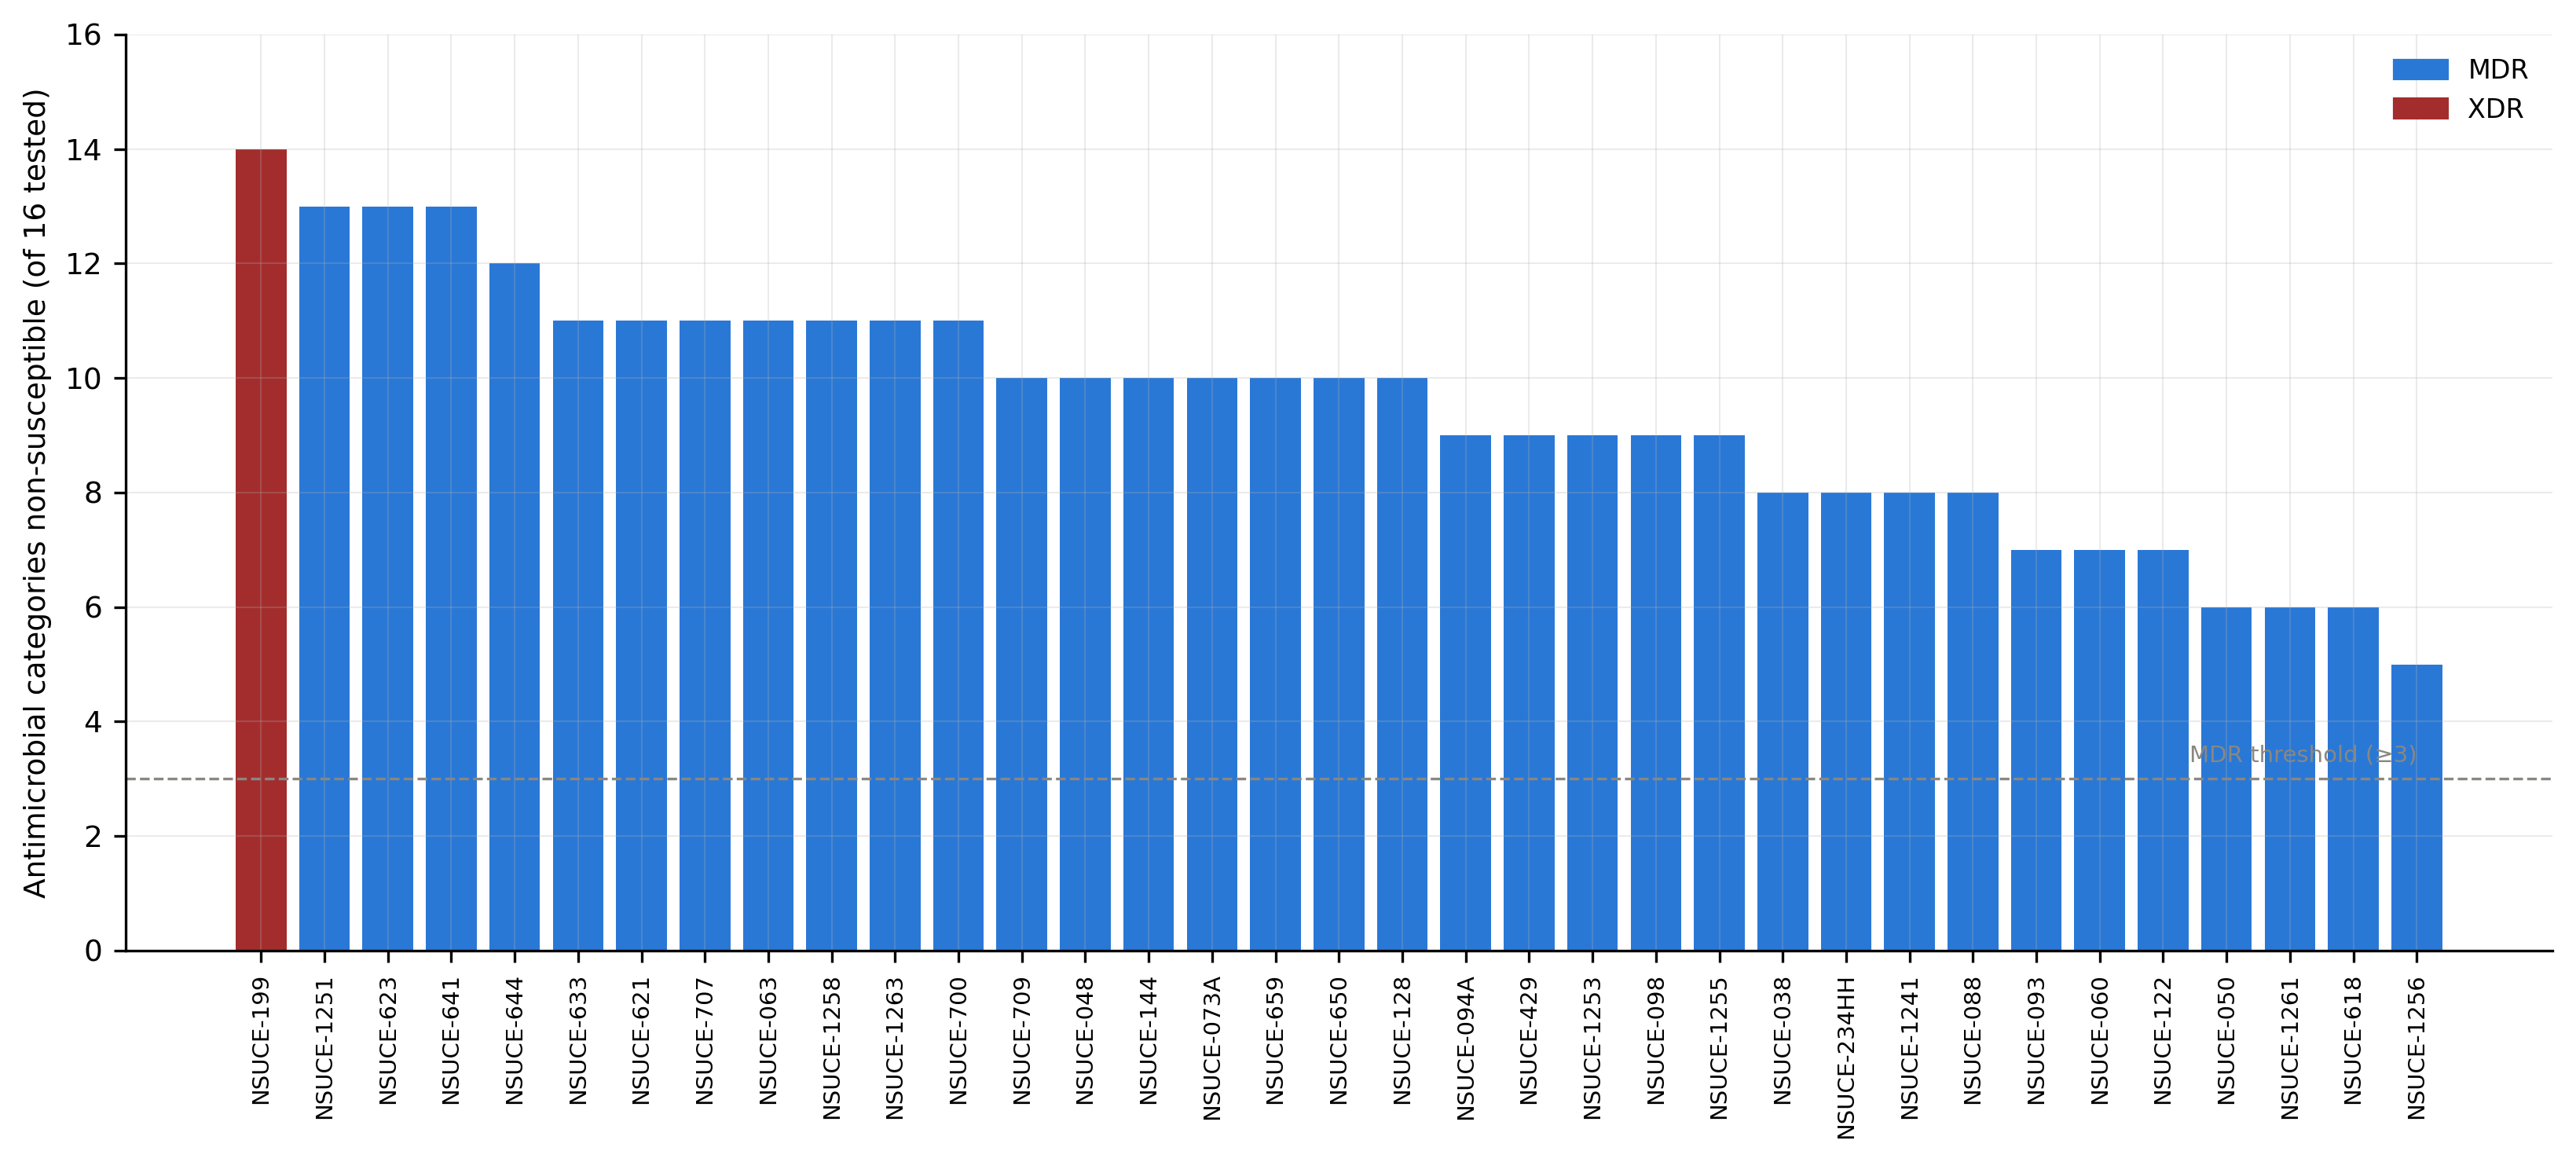

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'figure.dpi': 300,
})

# n_cat_ns already built earlier: strain, n_categories_nonsusceptible, pheno_mdr_status
plot_data = n_cat_ns.sort_values('n_categories_nonsusceptible', ascending=False)
colors = ['#a32d2d' if s == 'XDR' else '#2a78d6' for s in plot_data['pheno_mdr_status']]

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(plot_data['strain'], plot_data['n_categories_nonsusceptible'], color=colors)
ax.set_ylabel('Antimicrobial categories non-susceptible (of 16 tested)')
ax.set_ylim(0, 16)
ax.axhline(3, color='#898781', linestyle='--', linewidth=0.8)  # MDR threshold
ax.text(len(plot_data) - 1, 3.3, 'MDR threshold (≥3)', fontsize=7, color='#898781', ha='right')
ax.set_xticklabels(plot_data['strain'], rotation=90, fontsize=7)
#ax.set_title('Phenotypic resistance burden across NSUCE isolates (n=35)', loc='left', fontweight='bold', fontsize=10)

ax.legend(handles=[Patch(color='#2a78d6', label='MDR'), Patch(color='#a32d2d', label='XDR')],
          loc='upper right', frameon=False, fontsize=8)

plt.tight_layout()
plt.savefig('Figure_phenotypic_resistance_burden.png', dpi=300, bbox_inches='tight')
plt.show()

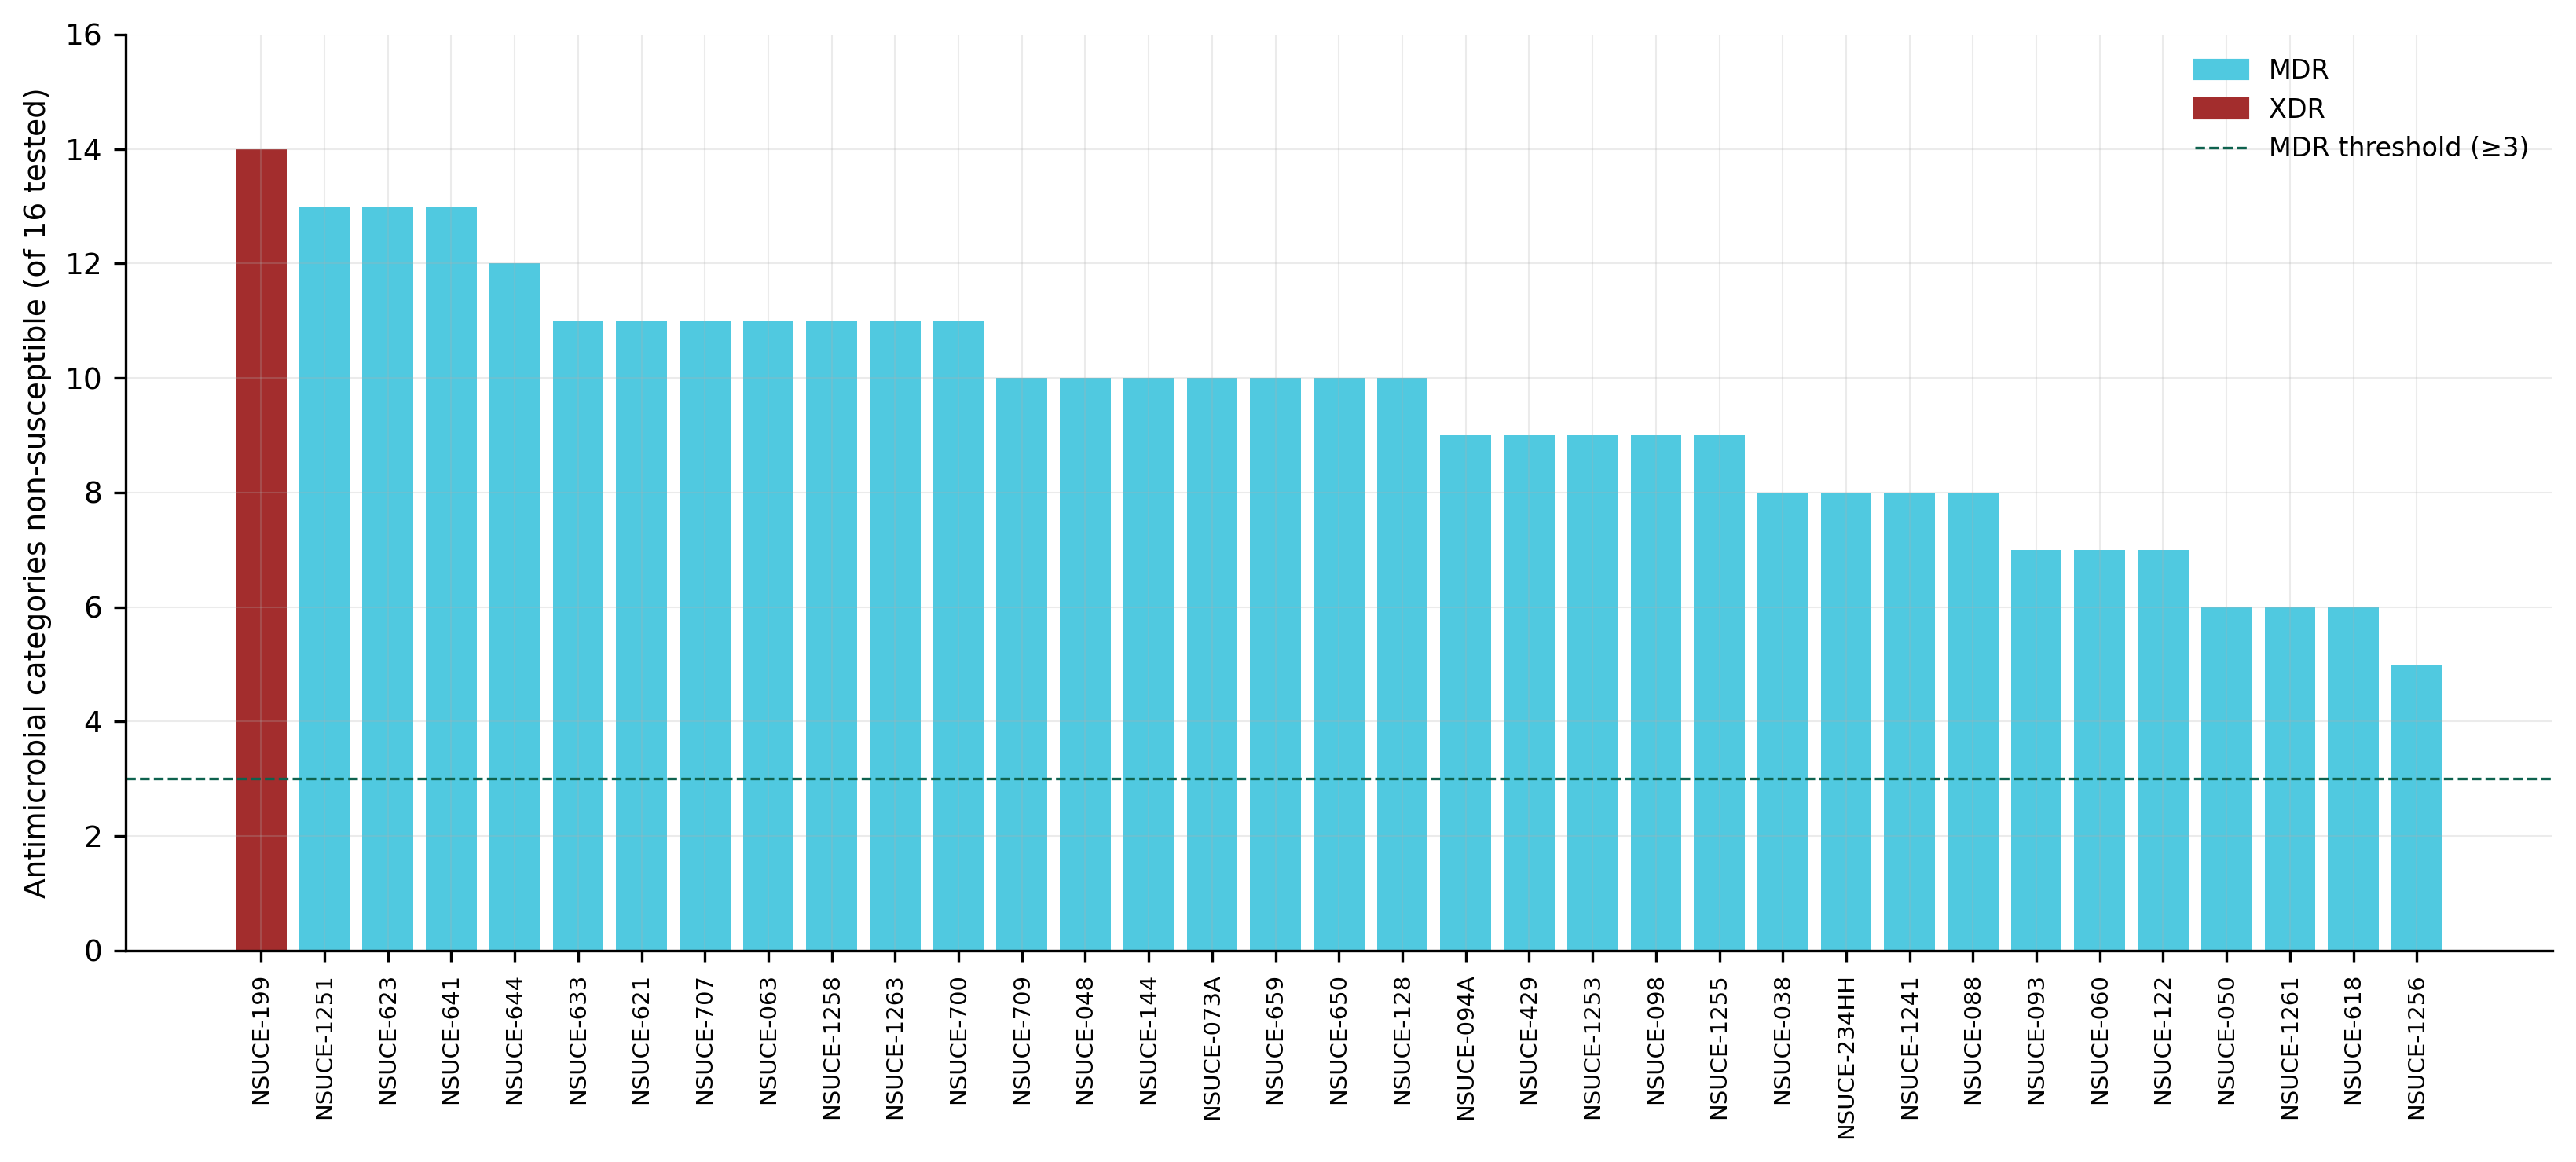

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'figure.dpi': 300,
})

# n_cat_ns already built earlier: strain, n_categories_nonsusceptible, pheno_mdr_status
plot_data = n_cat_ns.sort_values('n_categories_nonsusceptible', ascending=False)
colors = ['#a32d2d' if s == 'XDR' else '#50c9e0' for s in plot_data['pheno_mdr_status']]

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(plot_data['strain'], plot_data['n_categories_nonsusceptible'], color=colors)
ax.set_ylabel('Antimicrobial categories non-susceptible (of 16 tested)')
ax.set_ylim(0, 16)
ax.axhline(3, color='#0e624e', linestyle='--', linewidth=0.8)  # MDR threshold
ax.set_xticklabels(plot_data['strain'], rotation=90, fontsize=7)
#ax.set_title('Phenotypic resistance burden across NSUCE isolates (n=35)', loc='left', fontweight='bold', fontsize=10)

legend_handles = [
    Patch(color='#50c9e0', label='MDR'),
    Patch(color='#a32d2d', label='XDR'),
    Line2D([0], [0], color='#0e624e', linestyle='--', linewidth=0.8, label='MDR threshold (≥3)')
]
ax.legend(handles=legend_handles, loc='upper right', frameon=False, fontsize=8)

plt.tight_layout()
plt.savefig('Figure_phenotypic_resistance_burden.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
files.download('Figure_phenotypic_resistance_burden.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Per-drug phenotypic flags used for genotype-phenotype concordance

In [ ]:
# %% Cell 6 - Per-drug phenotypic flags used for genotype-phenotype concordance
pivot = ast.set_index('strain')
pheno_carb = pivot[['Meropenem(MEM)', 'Imipenem (IPM)']].apply(
    lambda r: (r == 'R').any() or (r == 'I').any(), axis=1).rename('pheno_carb')
pheno_esbl = pivot[['Ceftriaxone (CRO)', 'Cefotaxime (CTX)', 'Ceftazimide (CAZ)']].apply(
    lambda r: (r == 'R').any(), axis=1).rename('pheno_esbl_ceph')
pheno_cip = (pivot['Ciprofloxacin (CIP)'] == 'R').rename('pheno_cip_R')
pheno_col = (pivot['Colistin (CT)'] == 'R').rename('pheno_col_R')

# %% Cell 7 - Merge genotypic (Kleborate) and phenotypic (AST) data
# outer merge + indicator so any strain-name mismatches are visible, not silent
merged = nsuce.merge(n_cat_ns, on='strain', how='outer', indicator=True)
print("Merge diagnostics (should be mostly 'both'; 'right_only' = AST isolates")
print("missing from Kleborate output, e.g. NSUCE-1256 if not yet re-run):")
print(merged['_merge'].value_counts())
print(merged.loc[merged['_merge'] != 'both', ['strain', '_merge']])

merged = merged.merge(pheno_carb, on='strain', how='left') \
               .merge(pheno_esbl, on='strain', how='left') \
               .merge(pheno_cip, on='strain', how='left') \
               .merge(pheno_col, on='strain', how='left')

overlap = merged[merged['_merge'] == 'both'].copy()
print(f"\nIsolates with both genotype + phenotype data: n={len(overlap)}")


Merge diagnostics (should be mostly 'both'; 'right_only' = AST isolates
missing from Kleborate output, e.g. NSUCE-1256 if not yet re-run):
_merge
both          34
right_only     1
left_only      0
Name: count, dtype: int64
        strain      _merge
15  NSUCE-1256  right_only

Isolates with both genotype + phenotype data: n=34


In [ ]:
# %% Cell 8 - Genotype vs phenotype MDR/XDR concordance
ct_mdr = pd.crosstab(overlap['geno_mdr_status'], overlap['pheno_mdr_status'])
print("Genotypic (Kleborate resistance-class-count) vs phenotypic (AST) MDR/XDR status:")
print(ct_mdr)

overlap['geno_mdrxdr_bin'] = overlap['geno_mdr_status'].isin(['MDR', 'XDR'])
overlap['pheno_mdrxdr_bin'] = overlap['pheno_mdr_status'].isin(['MDR', 'XDR'])
agree_pct = (overlap['geno_mdrxdr_bin'] == overlap['pheno_mdrxdr_bin']).mean() * 100
kappa_mdr = cohen_kappa_score(overlap['geno_mdrxdr_bin'], overlap['pheno_mdrxdr_bin'])
print(f"\nBinary (MDR/XDR vs Non-MDR) agreement: {agree_pct:.1f}%")
print(f"Cohen's kappa = {kappa_mdr:.3f}  "
      f"({'no better than chance' if kappa_mdr < 0.2 else 'slight' if kappa_mdr < 0.4 else 'fair/moderate'})")


Genotypic (Kleborate resistance-class-count) vs phenotypic (AST) MDR/XDR status:
pheno_mdr_status  MDR  XDR
geno_mdr_status           
MDR                19    0
Non-MDR            14    1

Binary (MDR/XDR vs Non-MDR) agreement: 55.9%
Cohen's kappa = 0.000  (no better than chance)


## Mc Nemer Test

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

def run_mcnemar(geno, pheno, label):
    geno = geno.astype(bool)
    pheno = pheno.astype(bool)
    # 2x2 table of paired calls: rows = genotype (pos/neg), cols = phenotype (pos/neg)
    both_pos = (geno & pheno).sum()
    geno_only = (geno & ~pheno).sum()      # genotype positive, phenotype negative
    pheno_only = (~geno & pheno).sum()     # genotype negative, phenotype positive
    both_neg = (~geno & ~pheno).sum()

    table = [[both_pos, geno_only], [pheno_only, both_neg]]
    result = mcnemar(table, exact=True)  # exact binomial test - appropriate at this sample size

    print(f"\n{label}")
    print(f"  Genotype+/Pheno- (geno overcalls): {geno_only}  |  Genotype-/Pheno+ (geno undercalls): {pheno_only}")
    print(f"  McNemar's exact test: statistic={result.statistic:.1f}, p={result.pvalue:.4g}")
    if pheno_only > geno_only:
        print("  -> Direction: genotype UNDER-estimates phenotypic resistance")
    elif geno_only > pheno_only:
        print("  -> Direction: genotype OVER-estimates phenotypic resistance")
    else:
        print("  -> No directional imbalance")
    return result

# Apply to the overlap dataframe you already built (34 isolates with both genotype + phenotype)
run_mcnemar(overlap['geno_mdrxdr_bin'], overlap['pheno_mdrxdr_bin'], 'Overall MDR/XDR classification (geno vs pheno)')
run_mcnemar(overlap['geno_carb'], overlap['pheno_carb'], 'Carbapenemase gene vs Meropenem/Imipenem R/I')
run_mcnemar(overlap['geno_esbl'], overlap['pheno_esbl_ceph'], 'ESBL gene vs 3GC (CRO/CTX/CAZ) R')
run_mcnemar(overlap['geno_flq'], overlap['pheno_cip_R'], 'FQ acquired/mutation vs Ciprofloxacin R')
run_mcnemar(overlap['geno_col'], overlap['pheno_col_R'], 'Colistin acquired/mutation vs Colistin R')


Overall MDR/XDR classification (geno vs pheno)
  Genotype+/Pheno- (geno overcalls): 0  |  Genotype-/Pheno+ (geno undercalls): 15
  McNemar's exact test: statistic=0.0, p=6.104e-05
  -> Direction: genotype UNDER-estimates phenotypic resistance

Carbapenemase gene vs Meropenem/Imipenem R/I
  Genotype+/Pheno- (geno overcalls): 1  |  Genotype-/Pheno+ (geno undercalls): 3
  McNemar's exact test: statistic=1.0, p=0.625
  -> Direction: genotype UNDER-estimates phenotypic resistance

ESBL gene vs 3GC (CRO/CTX/CAZ) R
  Genotype+/Pheno- (geno overcalls): 0  |  Genotype-/Pheno+ (geno undercalls): 13
  McNemar's exact test: statistic=0.0, p=0.0002441
  -> Direction: genotype UNDER-estimates phenotypic resistance

FQ acquired/mutation vs Ciprofloxacin R
  Genotype+/Pheno- (geno overcalls): 11  |  Genotype-/Pheno+ (geno undercalls): 1
  McNemar's exact test: statistic=1.0, p=0.006348
  -> Direction: genotype OVER-estimates phenotypic resistance

Colistin acquired/mutation vs Colistin R
  Genotype+/

<bunch containing results, print to see contents>

## Gene-to-phenotype concordance

# New Section

In [ ]:
# %% Cell 9 - Gene-to-phenotype concordance for key drug classes
def concordance_stats(geno, pheno, label):
    geno = geno.astype(bool)
    pheno = pheno.astype(bool)
    tp = (geno & pheno).sum()
    tn = ((~geno) & (~pheno)).sum()
    fp = (geno & (~pheno)).sum()
    fn = ((~geno) & pheno).sum()
    sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan   # genotype catches phenotypic R
    spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    ppv = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    npv = tn / (tn + fn) if (tn + fn) > 0 else np.nan
    acc = (tp + tn) / (tp + tn + fp + fn)
    kappa = cohen_kappa_score(geno, pheno)
    print(f"\n{label}")
    print(f"  TP={tp}  FP={fp}  FN={fn}  TN={tn}")
    print(f"  Sensitivity={sens:.2f}  Specificity={spec:.2f}  PPV={ppv:.2f}  NPV={npv:.2f}  "
          f"Accuracy={acc:.2f}  Kappa={kappa:.3f}")
    return {'label': label, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'sensitivity': sens, 'specificity': spec, 'PPV': ppv, 'NPV': npv,
            'accuracy': acc, 'kappa': kappa}

results = []
results.append(concordance_stats(overlap['geno_carb'], overlap['pheno_carb'],
                                  'Carbapenemase gene vs Meropenem/Imipenem R or I'))
results.append(concordance_stats(overlap['geno_esbl'], overlap['pheno_esbl_ceph'],
                                  'ESBL gene vs 3rd-gen cephalosporin (CRO/CTX/CAZ) R'))
results.append(concordance_stats(overlap['geno_flq'], overlap['pheno_cip_R'],
                                  'Fluoroquinolone gene/mutation vs Ciprofloxacin R'))
results.append(concordance_stats(overlap['geno_col'], overlap['pheno_col_R'],
                                  'Colistin gene/mutation vs Colistin R'))

concordance_df = pd.DataFrame(results)
print("\nSummary table:")
print(concordance_df.round(2).to_string(index=False))



Carbapenemase gene vs Meropenem/Imipenem R or I
  TP=3  FP=1  FN=3  TN=27
  Sensitivity=0.50  Specificity=0.96  PPV=0.75  NPV=0.90  Accuracy=0.88  Kappa=0.534

ESBL gene vs 3rd-gen cephalosporin (CRO/CTX/CAZ) R
  TP=17  FP=0  FN=13  TN=4
  Sensitivity=0.57  Specificity=1.00  PPV=1.00  NPV=0.24  Accuracy=0.62  Kappa=0.235

Fluoroquinolone gene/mutation vs Ciprofloxacin R
  TP=9  FP=11  FN=1  TN=13
  Sensitivity=0.90  Specificity=0.54  PPV=0.45  NPV=0.93  Accuracy=0.65  Kappa=0.342

Colistin gene/mutation vs Colistin R
  TP=0  FP=0  FN=14  TN=20
  Sensitivity=0.00  Specificity=1.00  PPV=nan  NPV=0.59  Accuracy=0.59  Kappa=0.000

Summary table:
                                             label  TP  FP  FN  TN  sensitivity  specificity  PPV  NPV  accuracy  kappa
   Carbapenemase gene vs Meropenem/Imipenem R or I   3   1   3  27         0.50         0.96 0.75 0.90      0.88   0.53
ESBL gene vs 3rd-gen cephalosporin (CRO/CTX/CAZ) R  17   0  13   4         0.57         1.00 1.00 0.24      0

In [ ]:
# %% Cell 11 - Export
with pd.ExcelWriter('Kleborate_phenotype_concordance_summary.xlsx') as writer:
    n_cat_ns.sort_values('n_categories_nonsusceptible', ascending=False).to_excel(
        writer, sheet_name='Phenotypic_MDR_all35', index=False)
    overlap[['strain', 'geno_mdr_status', 'pheno_mdr_status', RC_COL, 'n_categories_nonsusceptible']].to_excel(
        writer, sheet_name='Genotype_vs_phenotype', index=False)
    concordance_df.to_excel(writer, sheet_name='Concordance_by_drug_class', index=False)

from google.colab import files as colab_files
colab_files.download('Kleborate_phenotype_concordance_summary.xlsx')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Kleborate Analysis**

In [ ]:
# ============================================================
# Kleborate Analysis of All Isolates – Lancet-ready figures
# ============================================================

# 1. Install & import
!pip install -q seaborn scikit-learn umap-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')

# Set Lancet-style aesthetics
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 600
plt.rcParams['font.family'] = 'DejaVu Sans'


In [ ]:
# 2. Upload / load data
# In Colab: use the file browser or run:
# from google.colab import files
 #uploaded = files.upload()

meta = pd.read_csv("klebsiella_global753.tsv", sep="\t")

# Quick clean
meta['virulence_score'] = pd.to_numeric(meta['klebsiella_pneumo_complex__virulence_score__virulence_score'], errors='coerce')
meta['resistance_score'] = pd.to_numeric(meta['klebsiella_pneumo_complex__resistance_score__resistance_score'], errors='coerce')
meta['num_res_classes'] = pd.to_numeric(meta['klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes'], errors='coerce')
meta['num_res_genes'] = pd.to_numeric(meta['klebsiella_pneumo_complex__resistance_gene_count__num_resistance_genes'], errors='coerce')

# High-risk clone flag (common for K. pneumoniae)
high_risk_sts = ['ST11', 'ST147', 'ST258', 'ST15', 'ST307', 'ST340', 'ST14']
meta['high_risk_clone'] = meta['klebsiella_pneumo_complex__mlst__ST'].isin(high_risk_sts)

print(f"Total isolates: {len(meta)}")
print(f"Unique STs: {meta['klebsiella_pneumo_complex__mlst__ST'].nunique()}")


Total isolates: 753
Unique STs: 136


In [ ]:
# ============================================================
# 3. Key Summary Tables
# ============================================================
print("\n=== Top 15 Sequence Types ===")
print(meta['klebsiella_pneumo_complex__mlst__ST'].value_counts().head(15))

print("\n=== Virulence & Resistance Score Summary ===")
print(meta[['virulence_score', 'resistance_score', 'num_res_classes']].describe())

print("\n=== Ciprofloxacin prediction ===")
print(meta['klebsiella_pneumo_complex__cipro_prediction__Ciprofloxacin_prediction'].value_counts())




=== Top 15 Sequence Types ===
klebsiella_pneumo_complex__mlst__ST
ST11     92
ST147    65
ST16     62
ST48     51
ST307    32
ST14     28
ST15     22
ST340    21
ST502    17
ST37     16
ST17     15
ST35     12
ST29     12
ST437    11
ST336    11
Name: count, dtype: int64

=== Virulence & Resistance Score Summary ===
       virulence_score  resistance_score  num_res_classes
count       753.000000        753.000000       753.000000
mean          0.524568          1.462151         7.479416
std           0.836179          0.748377         3.181130
min           0.000000          0.000000         0.000000
25%           0.000000          1.000000         7.000000
50%           0.000000          2.000000         8.000000
75%           1.000000          2.000000        10.000000
max           5.000000          3.000000        13.000000

=== Ciprofloxacin prediction ===
klebsiella_pneumo_complex__cipro_prediction__Ciprofloxacin_prediction
nonwildtype R    622
wildtype S       103
nonwildtype I

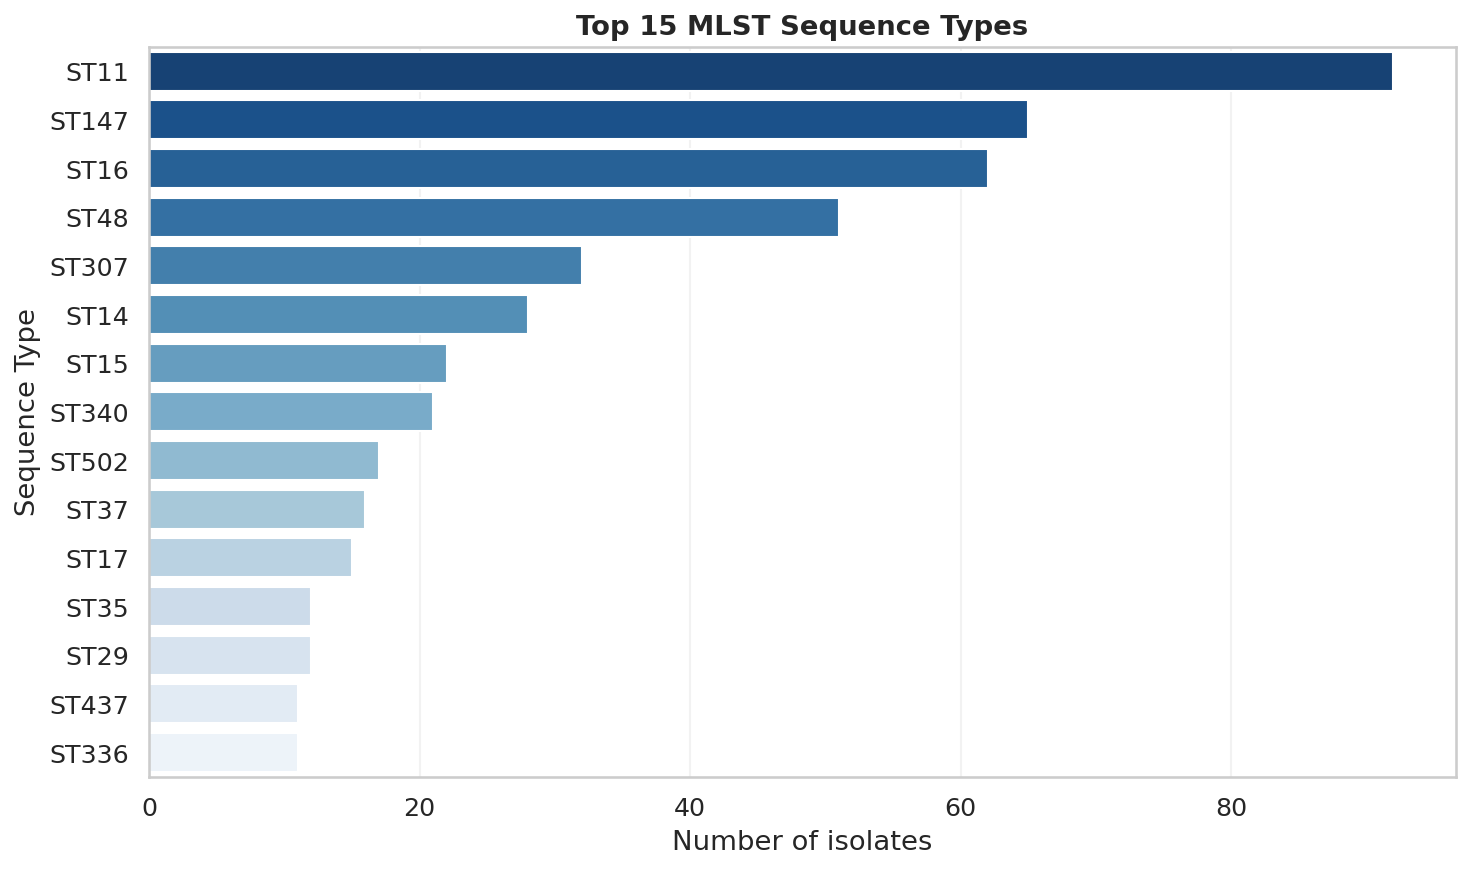

In [ ]:
# ============================================================
# 4. USEFUL GRAPHS (publication quality)
# ============================================================

# ---------- Figure 1: Top Sequence Types ----------
plt.figure(figsize=(10, 6))
top_st = meta['klebsiella_pneumo_complex__mlst__ST'].value_counts().head(15)
sns.barplot(x=top_st.values, y=top_st.index, palette="Blues_r")
plt.title("Top 15 MLST Sequence Types", fontweight='bold')
plt.xlabel("Number of isolates")
plt.ylabel("Sequence Type")
plt.tight_layout()
plt.savefig("Fig1_Top_STs.pdf", bbox_inches='tight')
plt.show()

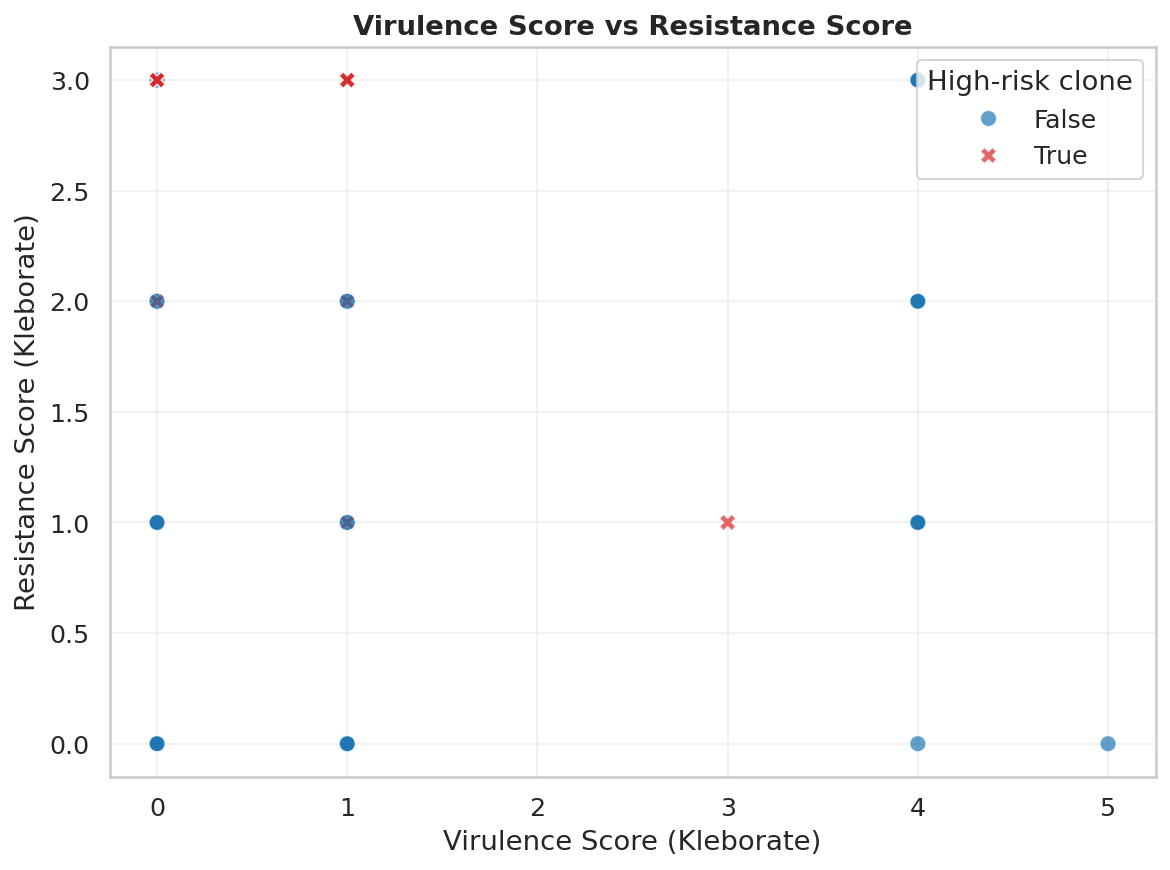

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Re-initialize meta using the correctly loaded and merged df from earlier cells
# This ensures that meta contains all the necessary Kleborate columns and derived scores.
meta = df.copy()
meta['virulence_score'] = pd.to_numeric(meta['klebsiella_pneumo_complex__virulence_score__virulence_score'], errors='coerce')
meta['resistance_score'] = pd.to_numeric(meta['klebsiella_pneumo_complex__resistance_score__resistance_score'], errors='coerce')
meta['num_res_classes'] = pd.to_numeric(meta['klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes'], errors='coerce')
meta['num_res_genes'] = pd.to_numeric(meta['klebsiella_pneumo_complex__resistance_gene_count__num_resistance_genes'], errors='coerce')

# High-risk clone flag (common for K. pneumoniae)
high_risk_sts = ['ST11', 'ST147', 'ST258', 'ST15', 'ST307', 'ST340', 'ST14']
meta['high_risk_clone'] = meta['klebsiella_pneumo_complex__mlst__ST'].isin(high_risk_sts)

# ---------- Figure 2: Virulence vs Resistance Score ----------
plt.figure(figsize=(8, 6))
sns.scatterplot(data=meta, x='virulence_score', y='resistance_score',
                hue='high_risk_clone', style='high_risk_clone',
                palette={True: '#d62728', False: '#1f77b4'}, s=60, alpha=0.7)
plt.title("Virulence Score vs Resistance Score", fontweight='bold')
plt.xlabel("Virulence Score (Kleborate)")
plt.ylabel("Resistance Score (Kleborate)")
plt.legend(title="High-risk clone", loc="upper right")
plt.tight_layout()
plt.savefig("Fig2_Vir_vs_Res.pdf", bbox_inches='tight')
plt.show()

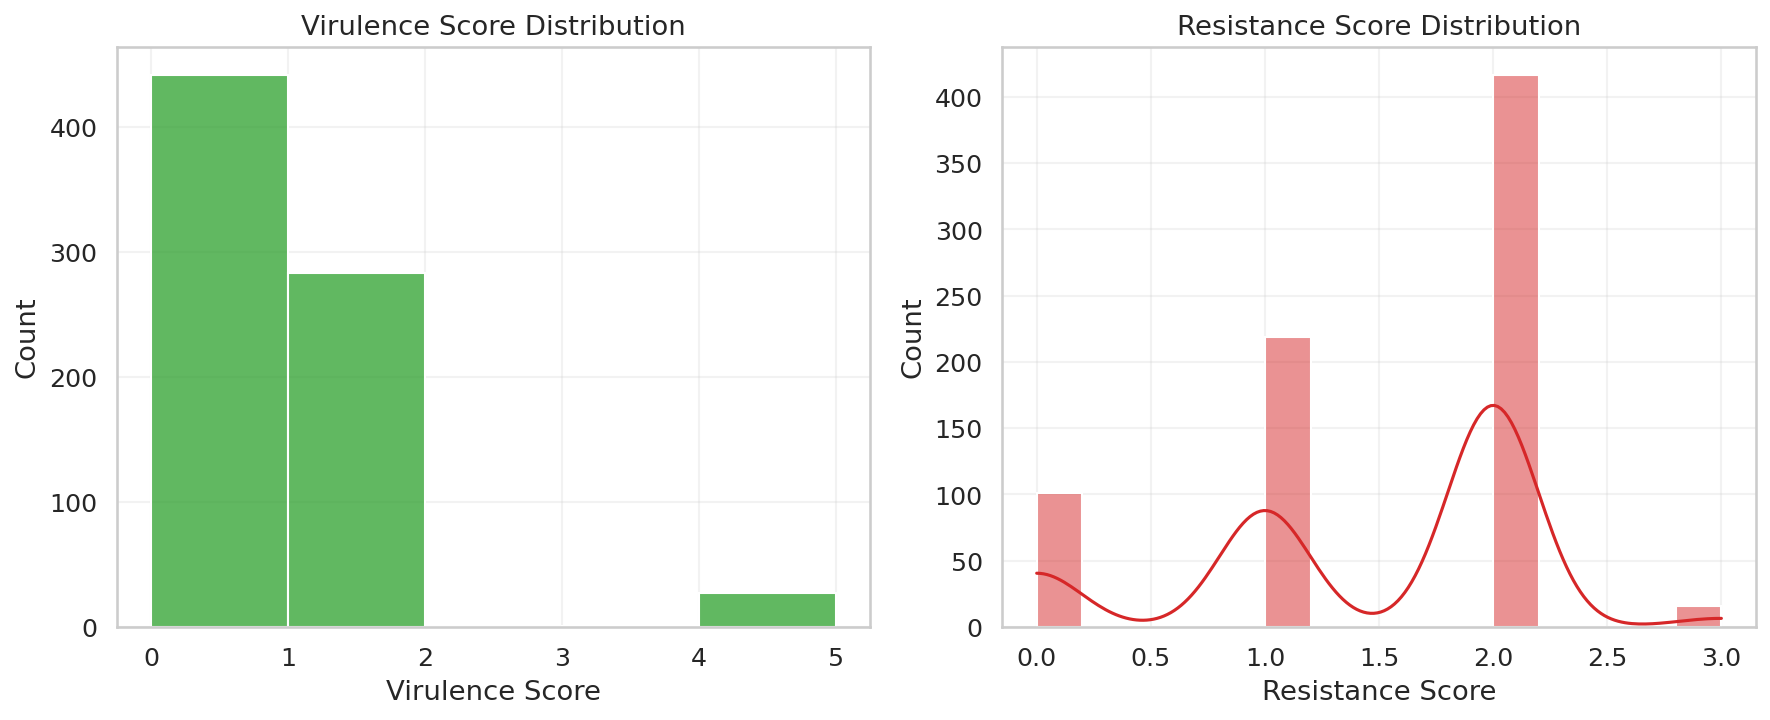

In [ ]:
# ---------- Figure 3: Distribution of scores ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(meta['virulence_score'].dropna(), bins=range(0, 6), kde=False, ax=axes[0], color='#2ca02c')
axes[0].set_title("Virulence Score Distribution")
axes[0].set_xlabel("Virulence Score")

sns.histplot(meta['resistance_score'].dropna(), bins=15, kde=True, ax=axes[1], color='#d62728')
axes[1].set_title("Resistance Score Distribution")
axes[1].set_xlabel("Resistance Score")
plt.tight_layout()
plt.savefig("Fig3_Score_Distributions.pdf", bbox_inches='tight')
plt.show()

K locus and O locus of all

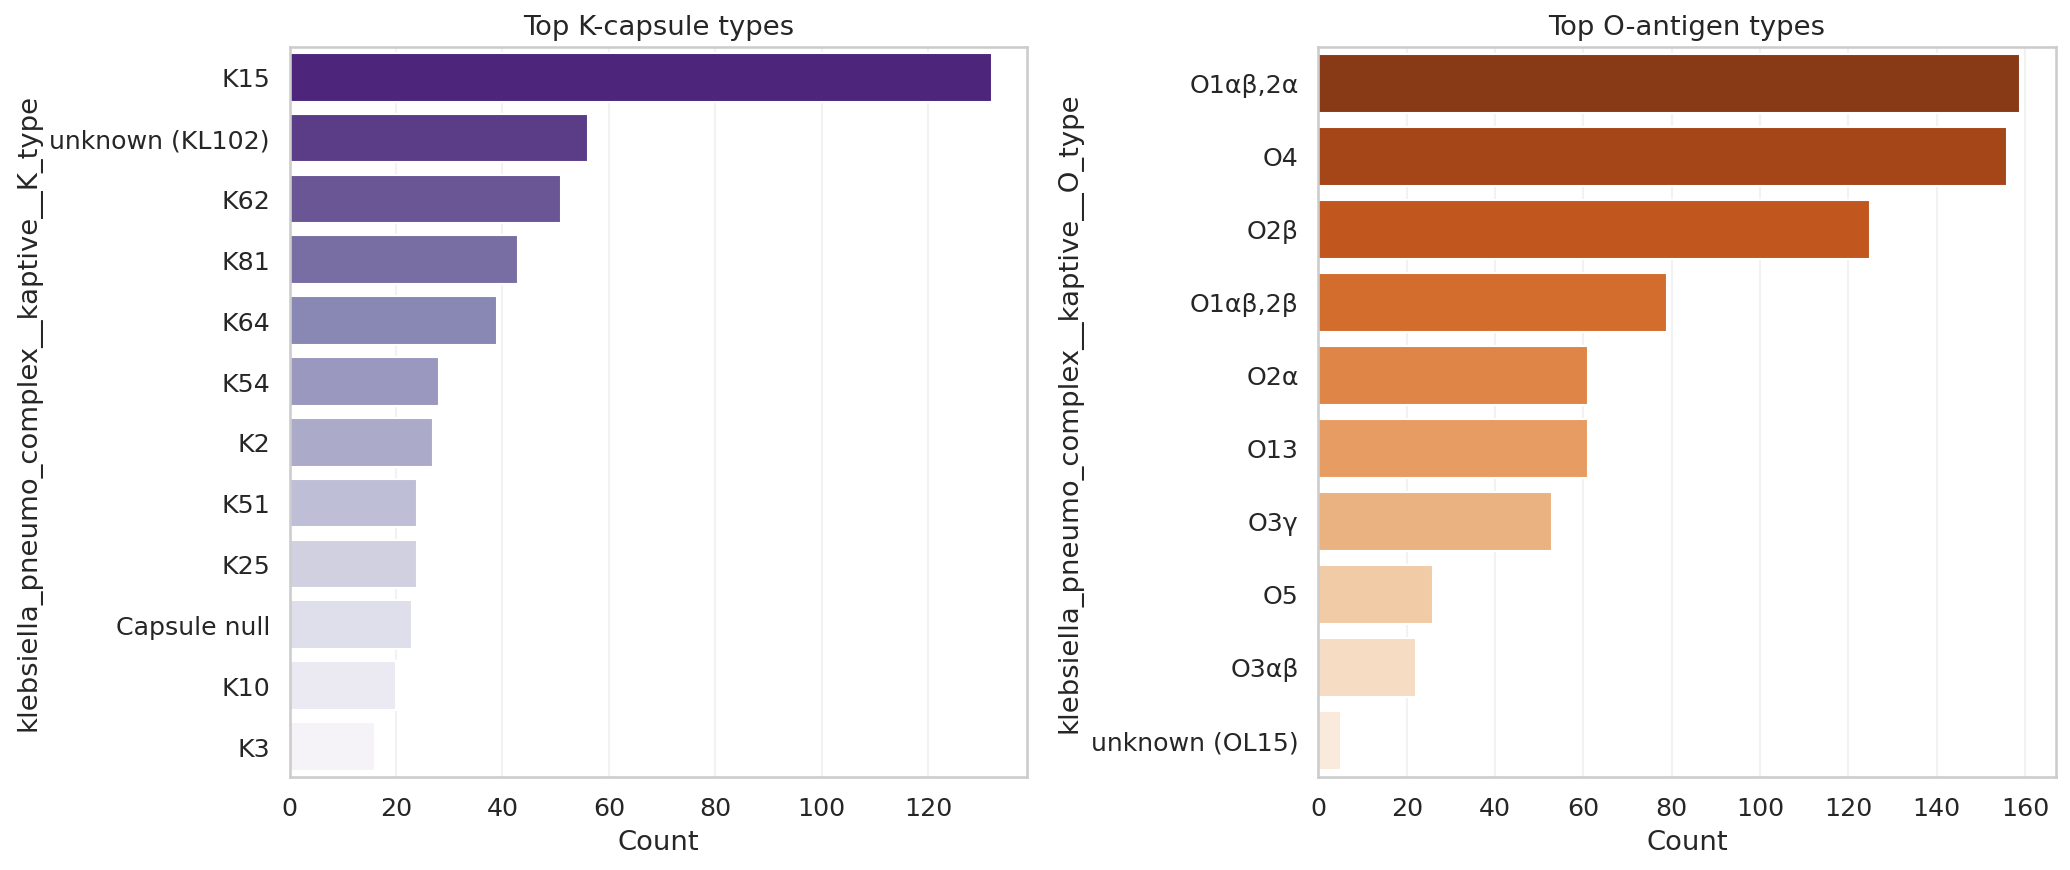

In [ ]:
# ---------- Figure 4: K-locus and O-locus ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
k_counts = meta['klebsiella_pneumo_complex__kaptive__K_type'].value_counts().head(12)
sns.barplot(x=k_counts.values, y=k_counts.index, ax=axes[0], palette="Purples_r")
axes[0].set_title("Top K-capsule types")
axes[0].set_xlabel("Count")

o_counts = meta['klebsiella_pneumo_complex__kaptive__O_type'].value_counts().head(10)
sns.barplot(x=o_counts.values, y=o_counts.index, ax=axes[1], palette="Oranges_r")
axes[1].set_title("Top O-antigen types")
axes[1].set_xlabel("Count")
plt.tight_layout()
plt.savefig("Fig4_K_O_types.pdf", bbox_inches='tight')
plt.show()


## K locus and O locus of 35


Number of your isolates: 34


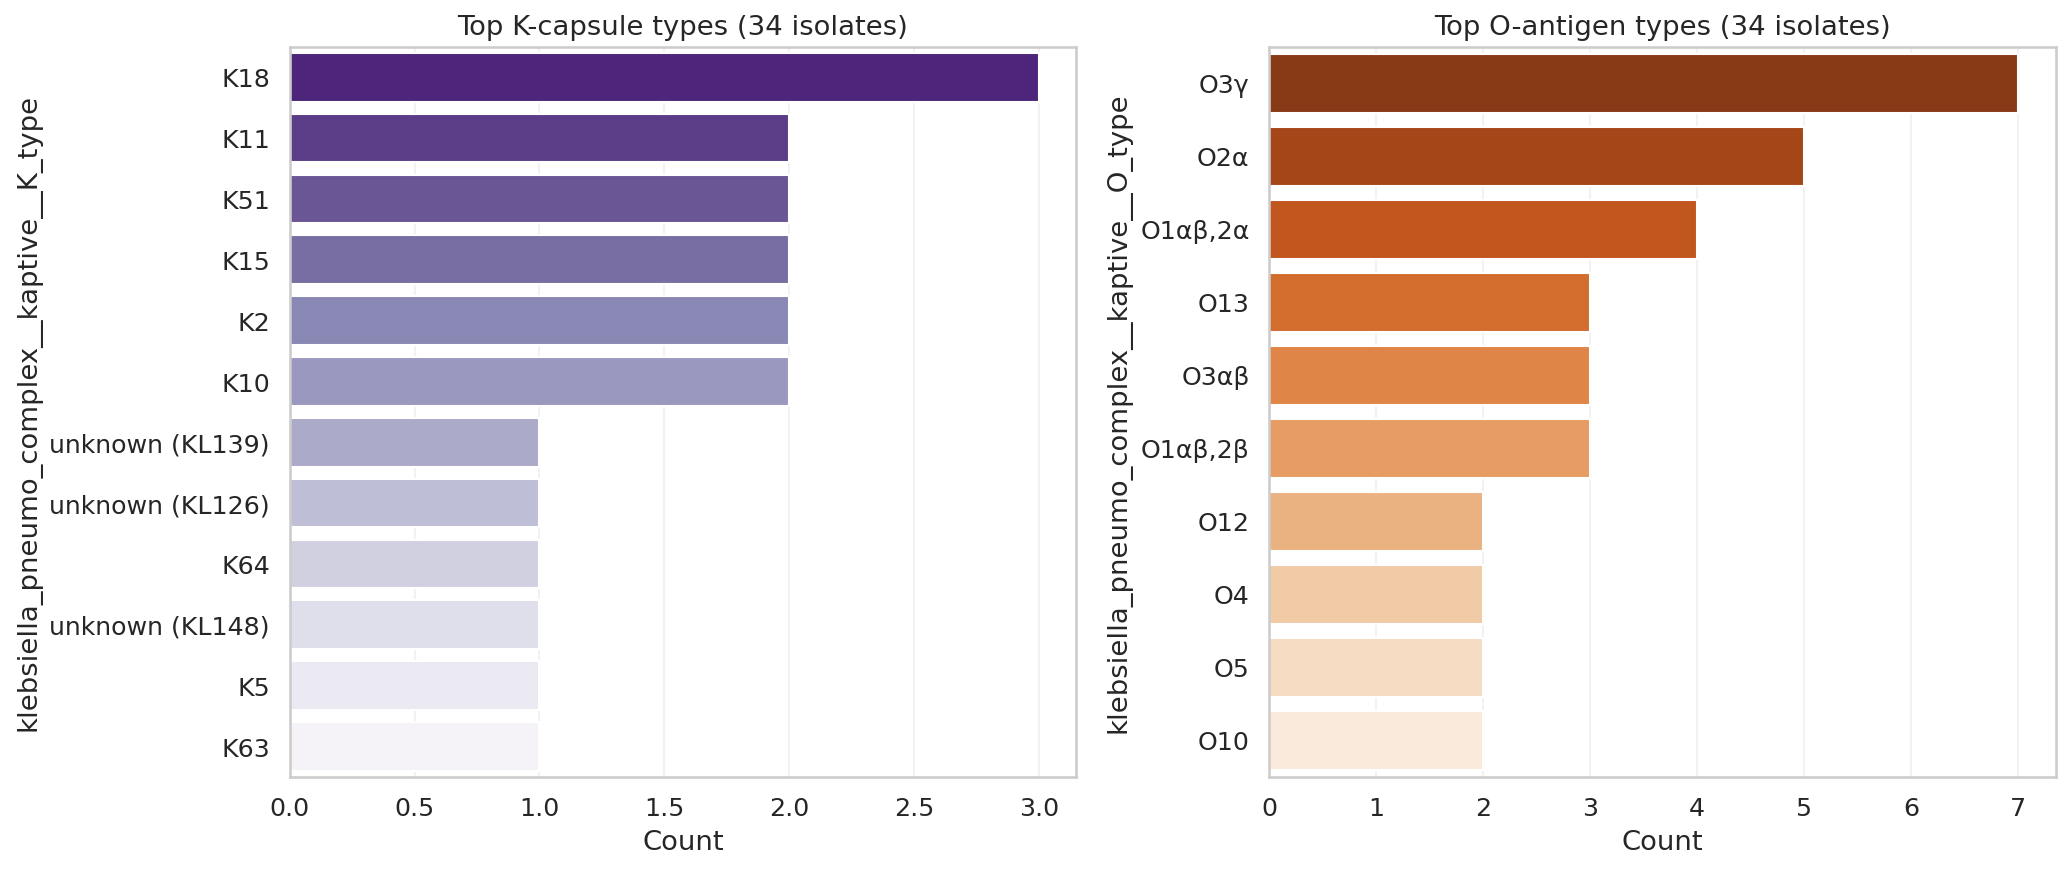

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 960x720 with 0 Axes>

In [ ]:
# Example: keep only your local isolates
# Adjust the pattern according to how your 35 isolates are named

# Option A – if they start with "NSUCE-"
local_meta = meta[meta['strain'].str.startswith('NSUCE-')].copy()

# Option B – if you have a list of your 35 sample IDs
# my_35 = ['NSUCE-038', 'NSUCE-048', ...]   # put your real list here
# local_meta = meta[meta['strain'].isin(my_35)].copy()

print(f"Number of your isolates: {len(local_meta)}")

# Then make the plot with local_meta instead of meta
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

k_counts = local_meta['klebsiella_pneumo_complex__kaptive__K_type'].value_counts().head(12)
sns.barplot(x=k_counts.values, y=k_counts.index, ax=axes[0], palette="Purples_r")
axes[0].set_title("Top K-capsule types (34 isolates)")
axes[0].set_xlabel("Count")

o_counts = local_meta['klebsiella_pneumo_complex__kaptive__O_type'].value_counts().head(10)
sns.barplot(x=o_counts.values, y=o_counts.index, ax=axes[1], palette="Oranges_r")
axes[1].set_title("Top O-antigen types (34 isolates)")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.savefig("Fig4_K_O_types_local35.pdf", bbox_inches='tight')
plt.show()
plt.savefig("Fig4_K_O_types_local35.png",dpi=300)
files.download("Fig4_K_O_types_local35.png")

In [ ]:
plt.savefig("Fig4_K_O_types_local35.png",dpi=300)
files.download("Fig4_K_O_types_local35.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 960x720 with 0 Axes>

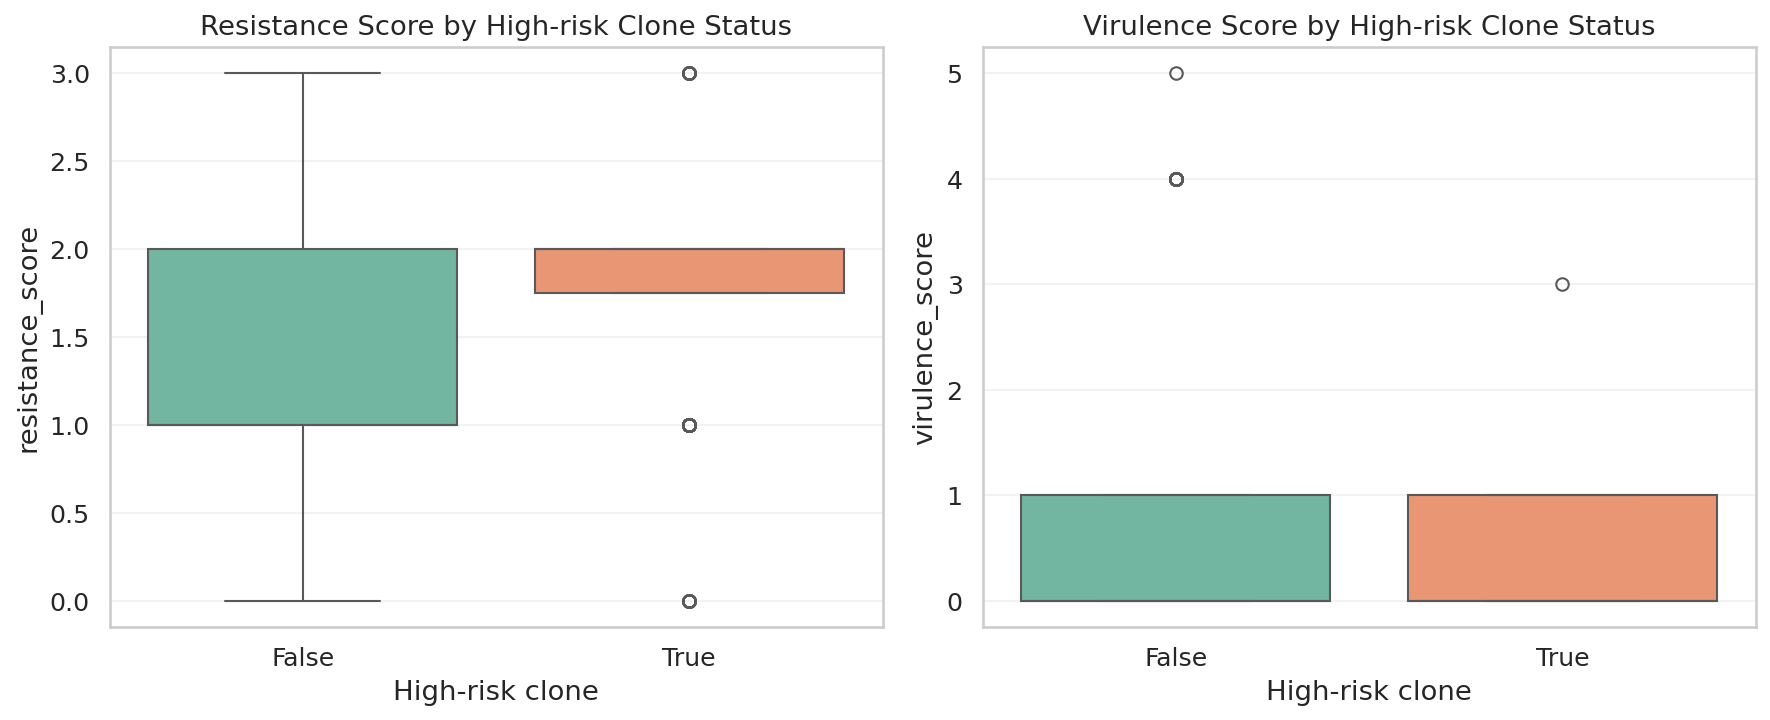

In [ ]:
# ---------- Figure 5: High-risk clones vs phenotypes ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=meta, x='high_risk_clone', y='resistance_score', ax=axes[0], palette="Set2")
axes[0].set_title("Resistance Score by High-risk Clone Status")
axes[0].set_xlabel("High-risk clone")

sns.boxplot(data=meta, x='high_risk_clone', y='virulence_score', ax=axes[1], palette="Set2")
axes[1].set_title("Virulence Score by High-risk Clone Status")
axes[1].set_xlabel("High-risk clone")
plt.tight_layout()
plt.savefig("Fig5_HighRisk_vs_Scores.pdf", bbox_inches='tight')
plt.show()


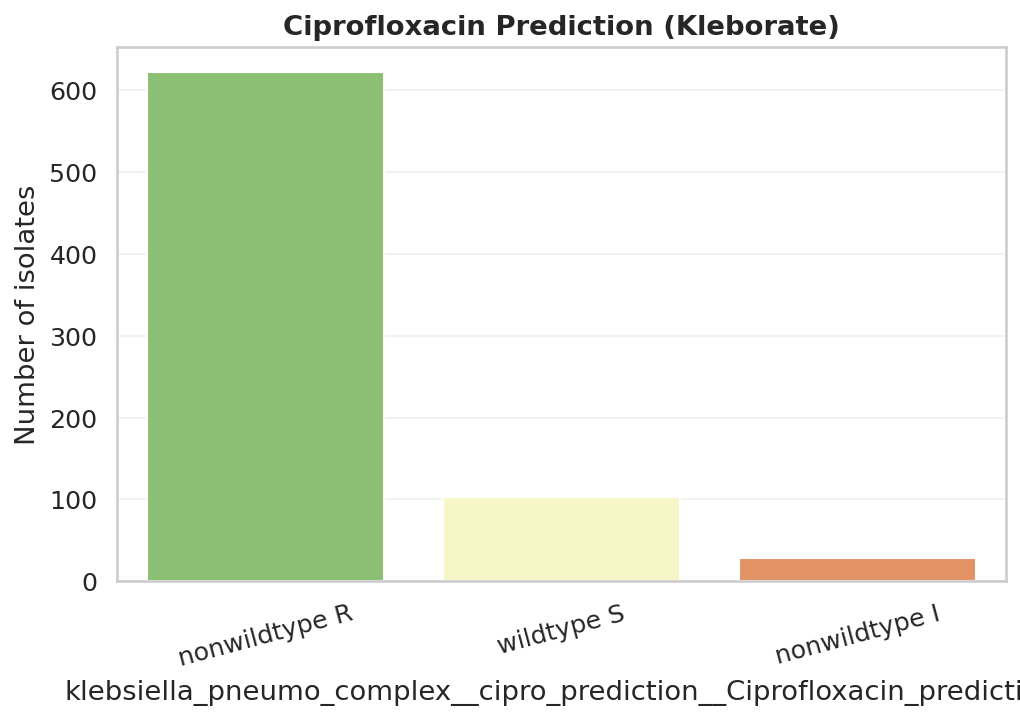

In [ ]:
# ---------- Figure 6: Ciprofloxacin prediction ----------
plt.figure(figsize=(7, 5))
cipro = meta['klebsiella_pneumo_complex__cipro_prediction__Ciprofloxacin_prediction'].value_counts()
sns.barplot(x=cipro.index, y=cipro.values, palette="RdYlGn_r")
plt.title("Ciprofloxacin Prediction (Kleborate)", fontweight='bold')
plt.ylabel("Number of isolates")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("Fig6_Cipro_Prediction.pdf", bbox_inches='tight')
plt.show()

=== Critical phenotype counts ===
Carbapenemase producers : 433
Hypervirulent (≥4)      : 27
CR-hvKp                 : 8
XDR                     : 505


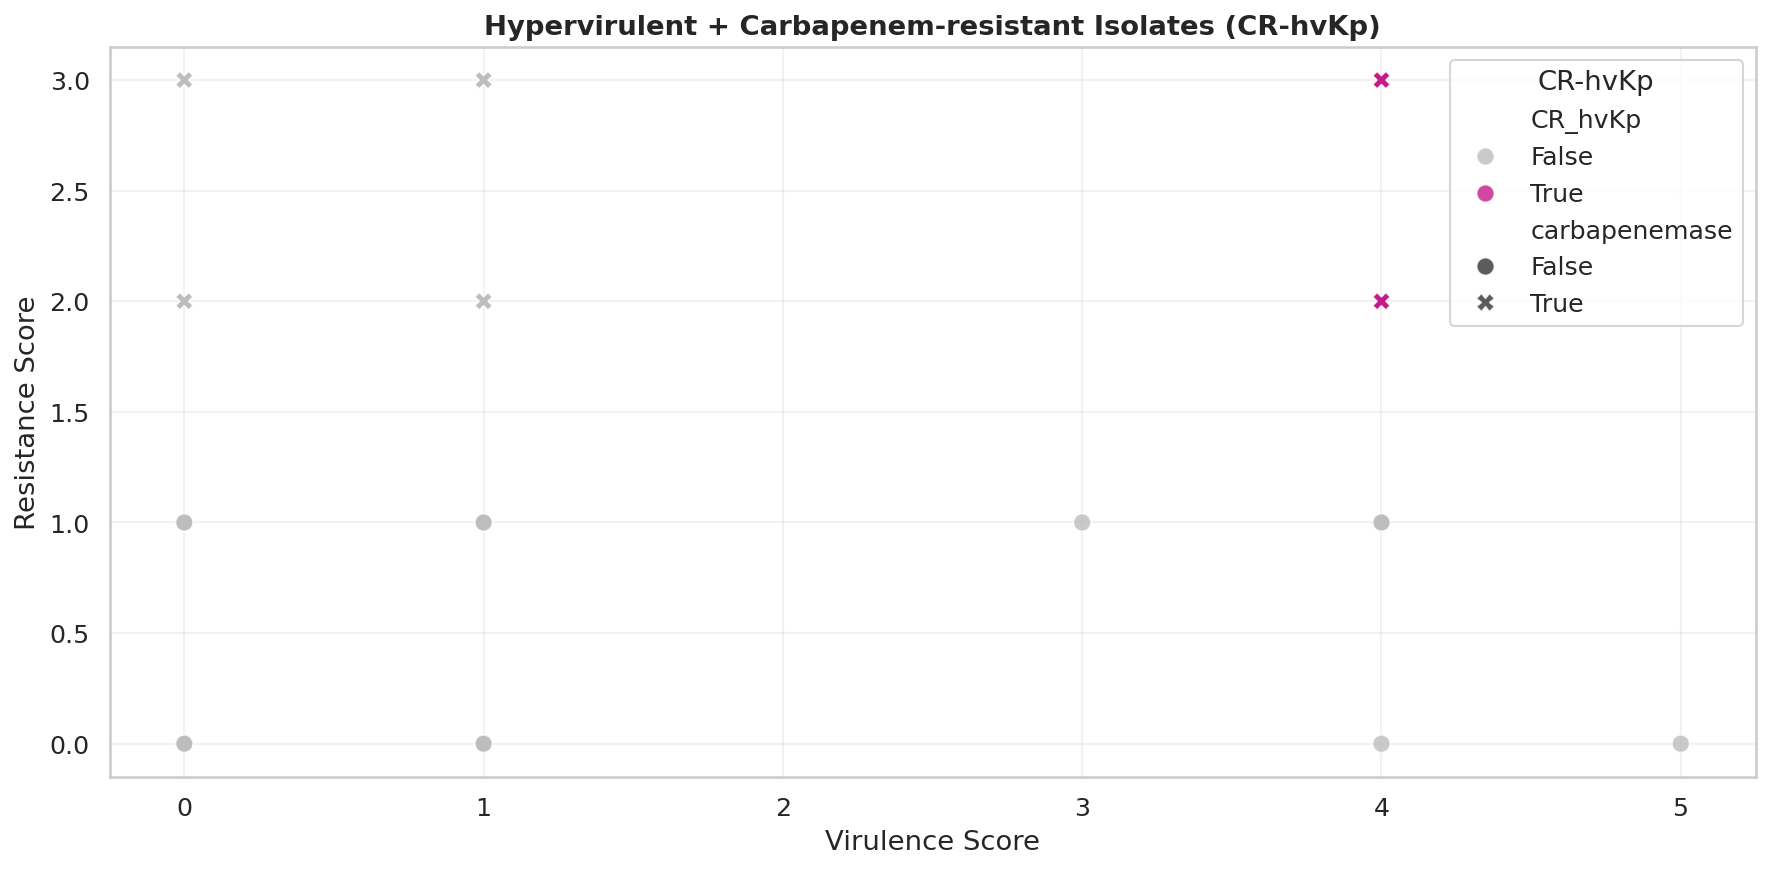

In [ ]:
# ============================================================
# HIGH-IMPACT EXTRA ANALYSES
# ============================================================

# 1. Define clinically important groups
meta['carbapenemase'] = meta['klebsiella_pneumo_complex__amr__Bla_Carb_acquired'].notna() & \
                        (meta['klebsiella_pneumo_complex__amr__Bla_Carb_acquired'] != '-')
meta['esbl'] = meta['klebsiella_pneumo_complex__amr__Bla_ESBL_acquired'].notna() & \
               (meta['klebsiella_pneumo_complex__amr__Bla_ESBL_acquired'] != '-')
meta['hypervirulent'] = meta['virulence_score'] >= 4          # conventional threshold
meta['CR_hvKp'] = meta['carbapenemase'] & meta['hypervirulent']
meta['XDR'] = meta['num_res_classes'] >= 8                   # adjust threshold if needed

print("=== Critical phenotype counts ===")
print(f"Carbapenemase producers : {meta['carbapenemase'].sum()}")
print(f"Hypervirulent (≥4)      : {meta['hypervirulent'].sum()}")
print(f"CR-hvKp                 : {meta['CR_hvKp'].sum()}")
print(f"XDR                     : {meta['XDR'].sum()}")

# ---------- Figure 8: CR-hvKp highlight (very reviewer-friendly) ----------
plt.figure(figsize=(12, 6))
sns.scatterplot(data=meta, x='virulence_score', y='resistance_score',
                hue='CR_hvKp', style='carbapenemase',
                palette={True: '#c51b8a', False: '#bdbdbd'}, s=70, alpha=0.8)
plt.title("Hypervirulent + Carbapenem-resistant Isolates (CR-hvKp)", fontweight='bold')
plt.xlabel("Virulence Score")
plt.ylabel("Resistance Score")
plt.legend(title="CR-hvKp", loc='upper right')
plt.tight_layout()
plt.savefig("Fig8_CR_hvKp.pdf", bbox_inches='tight')
plt.show()



## Upset plot

In [ ]:
# ============================================================
# UPSET PLOT – Multi-drug Resistance Combinations
# ============================================================

# Install required package
!pip install -q upsetplot

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from upsetplot import from_indicators, UpSet
import warnings
warnings.filterwarnings('ignore')

# ---------- 1. Create binary indicators for major resistance classes ----------
# Using the Kleborate columns

meta['Carbapenem'] = (meta['klebsiella_pneumo_complex__amr__Bla_Carb_acquired'].notna() &
                      (meta['klebsiella_pneumo_complex__amr__Bla_Carb_acquired'] != '-')).astype(int)

meta['ESBL'] = (meta['klebsiella_pneumo_complex__amr__Bla_ESBL_acquired'].notna() &
                (meta['klebsiella_pneumo_complex__amr__Bla_ESBL_acquired'] != '-')).astype(int)

meta['Fluoroquinolone'] = (
    (meta['klebsiella_pneumo_complex__amr__Flq_acquired'].notna() &
     (meta['klebsiella_pneumo_complex__amr__Flq_acquired'] != '-')) |
    (meta['klebsiella_pneumo_complex__amr__Flq_mutations'].notna() &
     (meta['klebsiella_pneumo_complex__amr__Flq_mutations'] != '-'))
).astype(int)

meta['Aminoglycoside'] = (meta['klebsiella_pneumo_complex__amr__AGly_acquired'].notna() &
                          (meta['klebsiella_pneumo_complex__amr__AGly_acquired'] != '-')).astype(int)

meta['Tetracycline'] = (meta['klebsiella_pneumo_complex__amr__Tet_acquired'].notna() &
                        (meta['klebsiella_pneumo_complex__amr__Tet_acquired'] != '-')).astype(int)

meta['Sulfonamide'] = (meta['klebsiella_pneumo_complex__amr__Sul_acquired'].notna() &
                       (meta['klebsiella_pneumo_complex__amr__Sul_acquired'] != '-')).astype(int)

meta['Trimethoprim'] = (meta['klebsiella_pneumo_complex__amr__Tmt_acquired'].notna() &
                        (meta['klebsiella_pneumo_complex__amr__Tmt_acquired'] != '-')).astype(int)

meta['Macrolide'] = (meta['klebsiella_pneumo_complex__amr__MLS_acquired'].notna() &
                     (meta['klebsiella_pneumo_complex__amr__MLS_acquired'] != '-')).astype(int)

# Optional: Colistin
meta['Colistin'] = (
    (meta['klebsiella_pneumo_complex__amr__Col_acquired'].notna() &
     (meta['klebsiella_pneumo_complex__amr__Col_acquired'] != '-')) |
    (meta['klebsiella_pneumo_complex__amr__Col_mutations'].notna() &
     (meta['klebsiella_pneumo_complex__amr__Col_mutations'] != '-'))
).astype(int)

# Select the columns you want to show
resistance_cols = ['Carbapenem', 'ESBL', 'Fluoroquinolone', 'Aminoglycoside',
                   'Tetracycline', 'Sulfonamide', 'Trimethoprim', 'Macrolide']

# Keep only isolates that have at least one of these resistances
upset_data = meta[resistance_cols].copy()
upset_data = upset_data[upset_data.sum(axis=1) > 0]

print(f"Isolates with ≥1 major resistance class: {len(upset_data)}")



Isolates with ≥1 major resistance class: 687


Total Bangladesh isolates in metadata: 604
Bangladesh isolates with Kleborate results: 603
Bangladesh isolates with ≥1 major resistance class: 579


<Figure size 2100x1200 with 0 Axes>

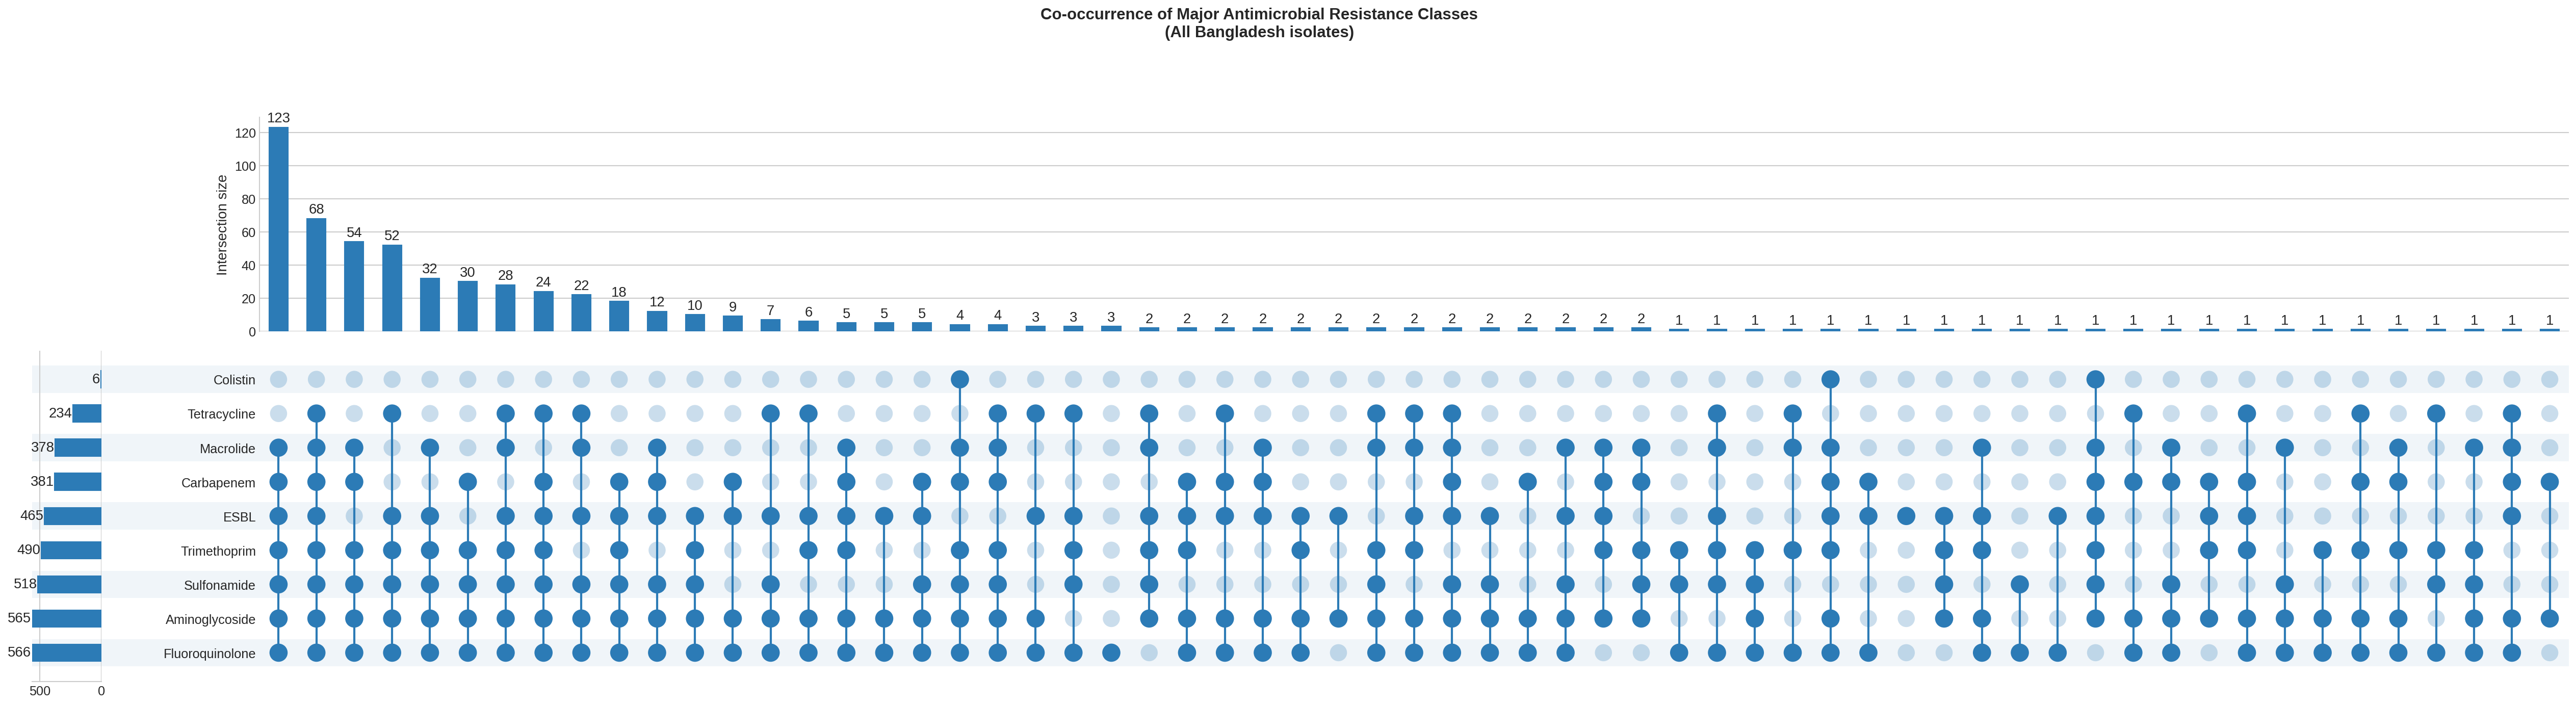

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# UPSET PLOT – All Bangladesh isolates (AMR analysis section)
# ============================================================

!pip install -q upsetplot
from upsetplot import from_indicators, UpSet
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
import numpy as np
from google.colab import files

# ---------- 1. Load metadata and identify Bangladesh isolates ----------
# Assuming you already have the main Kleborate dataframe as 'meta'
# and the source metadata as 'source_meta'

source_meta = pd.read_csv("global754_final_metadata_with_source_category.csv", sep='\t')

# Keep only Bangladesh isolates
bd_ids = source_meta.loc[source_meta['Country'] == 'Bangladesh', 'Genome_ID'].tolist()
print(f"Total Bangladesh isolates in metadata: {len(bd_ids)}")

# Filter the Kleborate results
bd_meta = df[df['strain'].isin(bd_ids)].copy()
print(f"Bangladesh isolates with Kleborate results: {len(bd_meta)}")

# ---------- 2. Create binary resistance class columns ----------
bd_meta['Carbapenem'] = (bd_meta['klebsiella_pneumo_complex__amr__Bla_Carb_acquired'].notna() &
                         (bd_meta['klebsiella_pneumo_complex__amr__Bla_Carb_acquired'] != '-')).astype(int)

bd_meta['ESBL'] = (bd_meta['klebsiella_pneumo_complex__amr__Bla_ESBL_acquired'].notna() &
                   (bd_meta['klebsiella_pneumo_complex__amr__Bla_ESBL_acquired'] != '-')).astype(int)

bd_meta['Fluoroquinolone'] = (
    (bd_meta['klebsiella_pneumo_complex__amr__Flq_acquired'].notna() &
     (bd_meta['klebsiella_pneumo_complex__amr__Flq_acquired'] != '-')) |
    (bd_meta['klebsiella_pneumo_complex__amr__Flq_mutations'].notna() &
     (bd_meta['klebsiella_pneumo_complex__amr__Flq_mutations'] != '-'))
).astype(int)

bd_meta['Aminoglycoside'] = (bd_meta['klebsiella_pneumo_complex__amr__AGly_acquired'].notna() &
                             (bd_meta['klebsiella_pneumo_complex__amr__AGly_acquired'] != '-')).astype(int)

bd_meta['Tetracycline'] = (bd_meta['klebsiella_pneumo_complex__amr__Tet_acquired'].notna() &
                           (bd_meta['klebsiella_pneumo_complex__amr__Tet_acquired'] != '-')).astype(int)

bd_meta['Sulfonamide'] = (bd_meta['klebsiella_pneumo_complex__amr__Sul_acquired'].notna() &
                          (bd_meta['klebsiella_pneumo_complex__amr__Sul_acquired'] != '-')).astype(int)

bd_meta['Trimethoprim'] = (bd_meta['klebsiella_pneumo_complex__amr__Tmt_acquired'].notna() &
                           (bd_meta['klebsiella_pneumo_complex__amr__Tmt_acquired'] != '-')).astype(int)

bd_meta['Macrolide'] = (bd_meta['klebsiella_pneumo_complex__amr__MLS_acquired'].notna() &
                        (bd_meta['klebsiella_pneumo_complex__amr__MLS_acquired'] != '-')).astype(int)

bd_meta['Colistin'] = (
    (bd_meta['klebsiella_pneumo_complex__amr__Col_acquired'].notna() &
     (bd_meta['klebsiella_pneumo_complex__amr__Col_acquired'] != '-')) |
    (bd_meta['klebsiella_pneumo_complex__amr__Col_mutations'].notna() &
     (bd_meta['klebsiella_pneumo_complex__amr__Col_mutations'] != '-'))
).astype(int)

# ---------- 3. Prepare data for Upset plot ----------
resistance_cols = ['Carbapenem', 'ESBL', 'Fluoroquinolone', 'Aminoglycoside',
                   'Tetracycline', 'Sulfonamide', 'Trimethoprim', 'Macrolide', 'Colistin']

upset_data = bd_meta[resistance_cols].copy()
upset_data = upset_data[upset_data.sum(axis=1) > 0]   # only isolates with ≥1 resistance class

print(f"Bangladesh isolates with ≥1 major resistance class: {len(upset_data)}")

upset_input = from_indicators(resistance_cols, data=upset_data.astype(bool))

# ---------- 4. Create colourful Upset plot ----------
plt.style.use('seaborn-v0_8-whitegrid')

fig = plt.figure(figsize=(14, 8))

upset = UpSet(
    upset_input,
    subset_size='count',
    show_counts=True,
    sort_by='cardinality',
    element_size=46,
    facecolor='#2c7bb6',
    other_dots_color=0.25,
    shading_color=0.07
)

upset.plot()

plt.suptitle("Co-occurrence of Major Antimicrobial Resistance Classes\n(All Bangladesh isolates)",
             fontsize=15, fontweight='bold', y=1.03)

plt.savefig("Fig_Upset_All_Bangladesh.pdf", bbox_inches='tight', dpi=600)
plt.savefig("Fig_Upset_All_Bangladesh.png", bbox_inches='tight', dpi=600)
plt.show()

# ---------- 5. Download ----------
files.download("Fig_Upset_All_Bangladesh.pdf")
files.download("Fig_Upset_All_Bangladesh.png")

In [ ]:
import pandas as pd
from upsetplot import from_indicators

# binary_df: one row per isolate, one column per resistance class,
# values True/False (or 1/0) for resistant/not - this is the matrix
# that was used to build the UpSet plot in the first place
resistance_classes = ['Colistin', 'Tetracycline', 'Macrolide', 'Carbapenem',
                       'ESBL', 'Trimethoprim', 'Sulfonamide', 'Aminoglycoside',
                       'Fluoroquinolone']

# Define binary_df from bd_meta (assuming bd_meta is available from previous cells)
binary_df = bd_meta[resistance_classes].copy()
binary_df = binary_df[binary_df.sum(axis=1) > 0] # Keep only isolates with >=1 resistance class

# Convert to boolean type as required by from_indicators
upset_data = from_indicators(resistance_classes, data=binary_df.astype(bool))

# This gives you every combination and its exact size, sorted
intersection_counts = upset_data.groupby(level=list(range(len(resistance_classes)))).size()
intersection_counts = intersection_counts.sort_values(ascending=False)

print("Top 10 intersections (combination -> count):")
print(intersection_counts.head(10))

# To specifically pull out which classes make up the largest (123) combination:
top_combo = intersection_counts.index[0]
active_classes = [cls for cls, present in zip(resistance_classes, top_combo) if present]
print(f"\nLargest combination (n={intersection_counts.iloc[0]}) consists of: {active_classes}")

Top 10 intersections (combination -> count):
Colistin  Tetracycline  Macrolide  Carbapenem  ESBL   Trimethoprim  Sulfonamide  Aminoglycoside  Fluoroquinolone
False     False         True       True        True   True          True         True            True               123
          True          True       True        True   True          True         True            True                68
          False         True       True        False  True          True         True            True                54
          True          False      False       True   True          True         True            True                52
          False         True       False       True   True          True         True            True                32
                        False      True        False  True          True         True            True                30
          True          True       False       True   True          True         True            True                28
  

<Figure size 1650x1050 with 0 Axes>

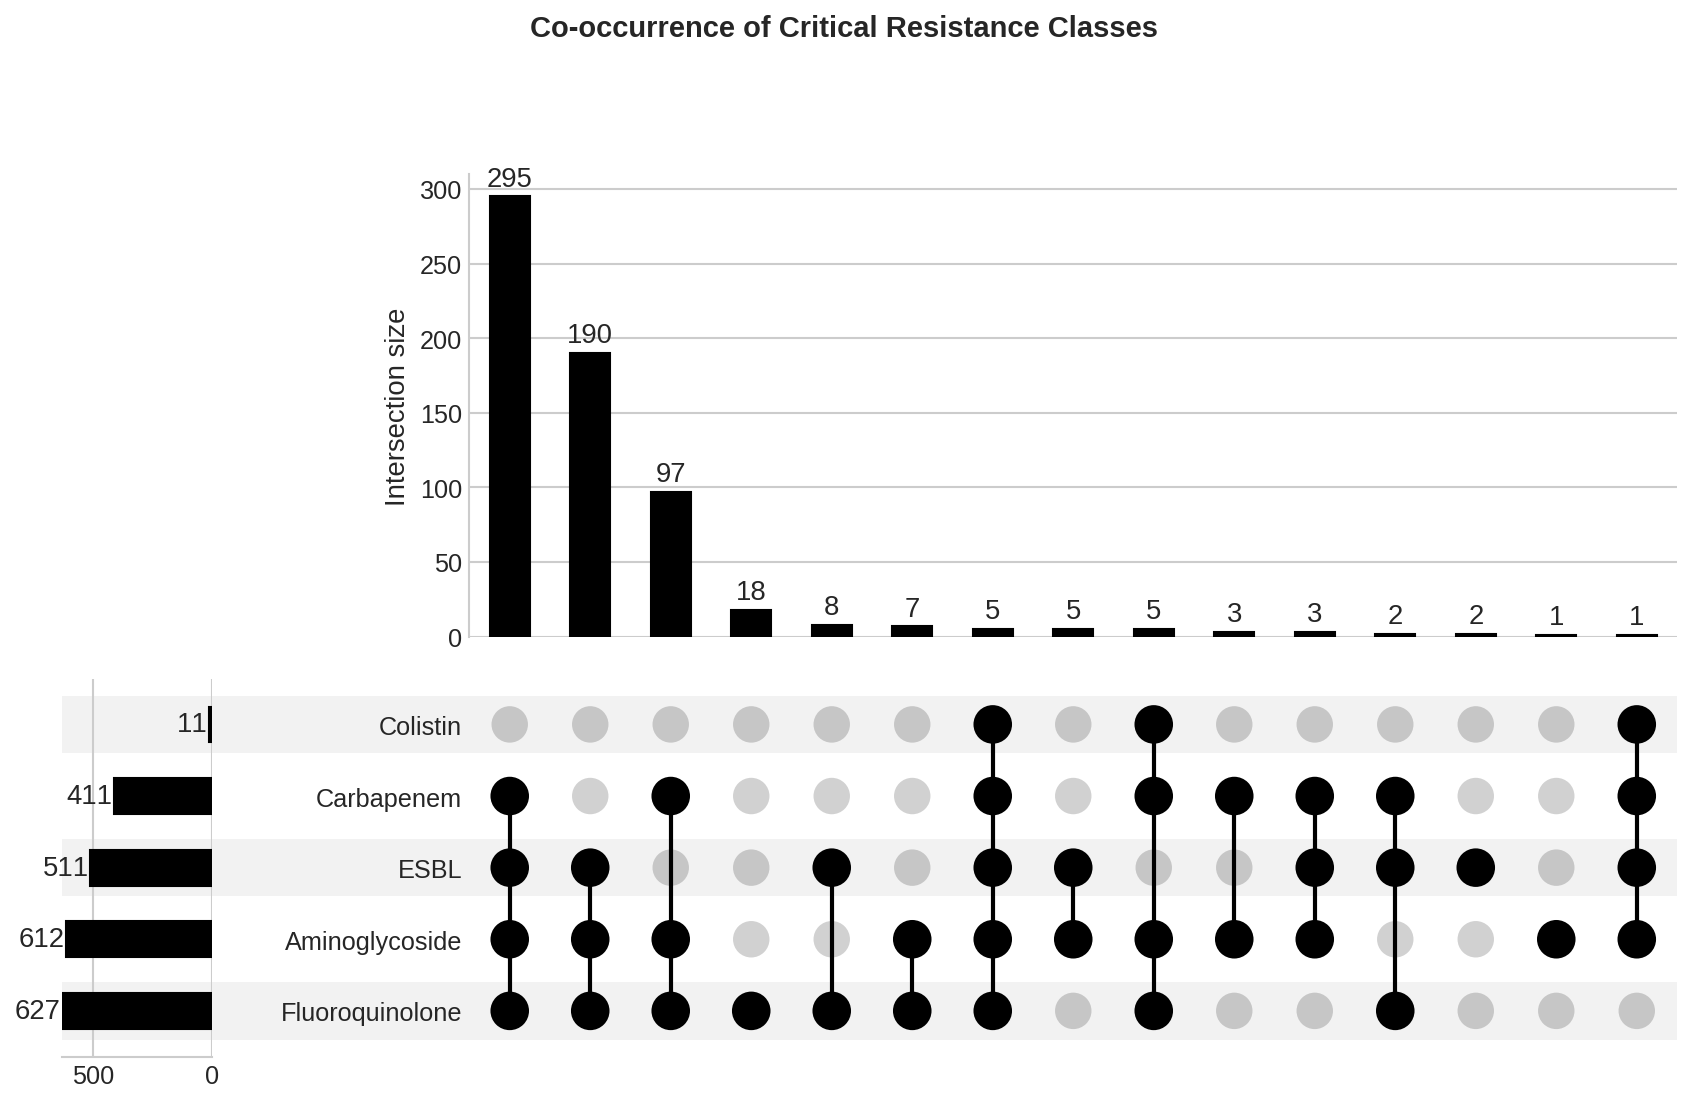

In [ ]:
critical_cols = ['Carbapenem', 'ESBL', 'Fluoroquinolone', 'Aminoglycoside', 'Colistin']

# Create binary resistance class columns in the df DataFrame
df['Carbapenem'] = (df['klebsiella_pneumo_complex__amr__Bla_Carb_acquired'].notna() &
                      (df['klebsiella_pneumo_complex__amr__Bla_Carb_acquired'] != '-')
                     ).astype(int)

df['ESBL'] = (df['klebsiella_pneumo_complex__amr__Bla_ESBL_acquired'].notna() &
                (df['klebsiella_pneumo_complex__amr__Bla_ESBL_acquired'] != '-')
               ).astype(int)

df['Fluoroquinolone'] = (
    (df['klebsiella_pneumo_complex__amr__Flq_acquired'].notna() &
     (df['klebsiella_pneumo_complex__amr__Flq_acquired'] != '-')) |
    (df['klebsiella_pneumo_complex__amr__Flq_mutations'].notna() &
     (df['klebsiella_pneumo_complex__amr__Flq_mutations'] != '-'))
).astype(int)

df['Aminoglycoside'] = (df['klebsiella_pneumo_complex__amr__AGly_acquired'].notna() &
                          (df['klebsiella_pneumo_complex__amr__AGly_acquired'] != '-')
                         ).astype(int)

df['Colistin'] = (
    (df['klebsiella_pneumo_complex__amr__Col_acquired'].notna() &
     (df['klebsiella_pneumo_complex__amr__Col_acquired'] != '-')) |
    (df['klebsiella_pneumo_complex__amr__Col_mutations'].notna() &
     (df['klebsiella_pneumo_complex__amr__Col_mutations'] != '-'))
).astype(int)

upset_data_crit = df[critical_cols].copy()
upset_data_crit = upset_data_crit[upset_data_crit.sum(axis=1) > 0]

upset_input_crit = from_indicators(critical_cols, data=upset_data_crit.astype(bool))

plt.figure(figsize=(11, 7))
UpSet(upset_input_crit, subset_size='count', show_counts=True,
      sort_by='cardinality', element_size=50).plot()
plt.suptitle("Co-occurrence of Critical Resistance Classes", fontsize=14, fontweight='bold', y=1.02)
plt.savefig("Fig_Upset_Critical_AMR.pdf", bbox_inches='tight', dpi=600)
plt.show()

## Upset plot for 35 isolates

Local isolates with ≥1 major resistance class: 22


<Figure size 1950x1050 with 0 Axes>

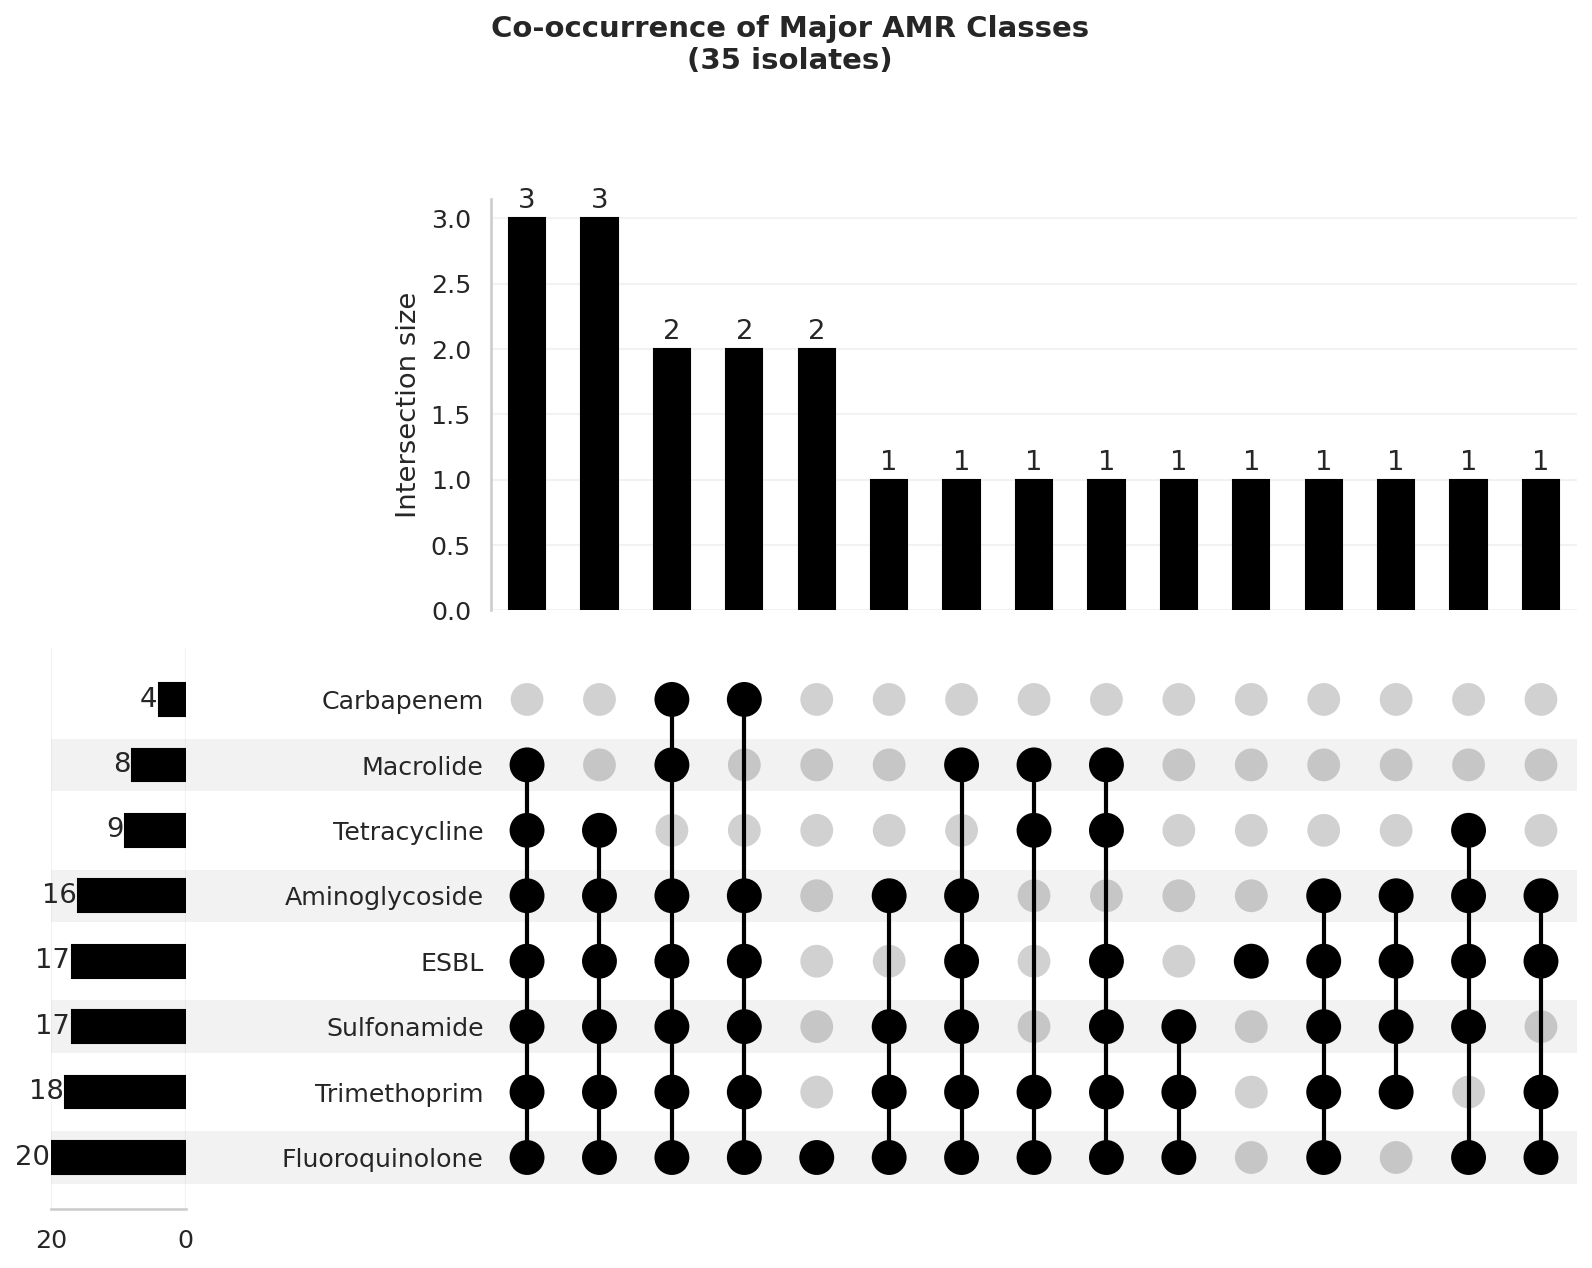

In [ ]:
# ============================================================
# UPSET PLOT – Local 35 isolates
# ============================================================

!pip install -q upsetplot
from upsetplot import from_indicators, UpSet
import matplotlib.pyplot as plt

resistance_cols = ['Carbapenem', 'ESBL', 'Fluoroquinolone', 'Aminoglycoside',
                   'Tetracycline', 'Sulfonamide', 'Trimethoprim', 'Macrolide', 'Colistin']

upset_data = local_meta[resistance_cols].copy()
upset_data = upset_data[upset_data.sum(axis=1) > 0]   # only isolates with ≥1 resistance

print(f"Local isolates with ≥1 major resistance class: {len(upset_data)}")

upset_input = from_indicators(resistance_cols, data=upset_data.astype(bool))

plt.figure(figsize=(13, 7))
UpSet(upset_input,
      subset_size='count',
      show_counts=True,
      sort_by='cardinality',
      element_size=45).plot()

plt.suptitle("Co-occurrence of Major AMR Classes\n(35 isolates)",
             fontsize=14, fontweight='bold', y=1.02)
plt.savefig("Fig_Upset_Local35.pdf", bbox_inches='tight', dpi=600)
plt.show()

Local isolates with ≥1 major resistance class: 22


<Figure size 2100x1200 with 0 Axes>

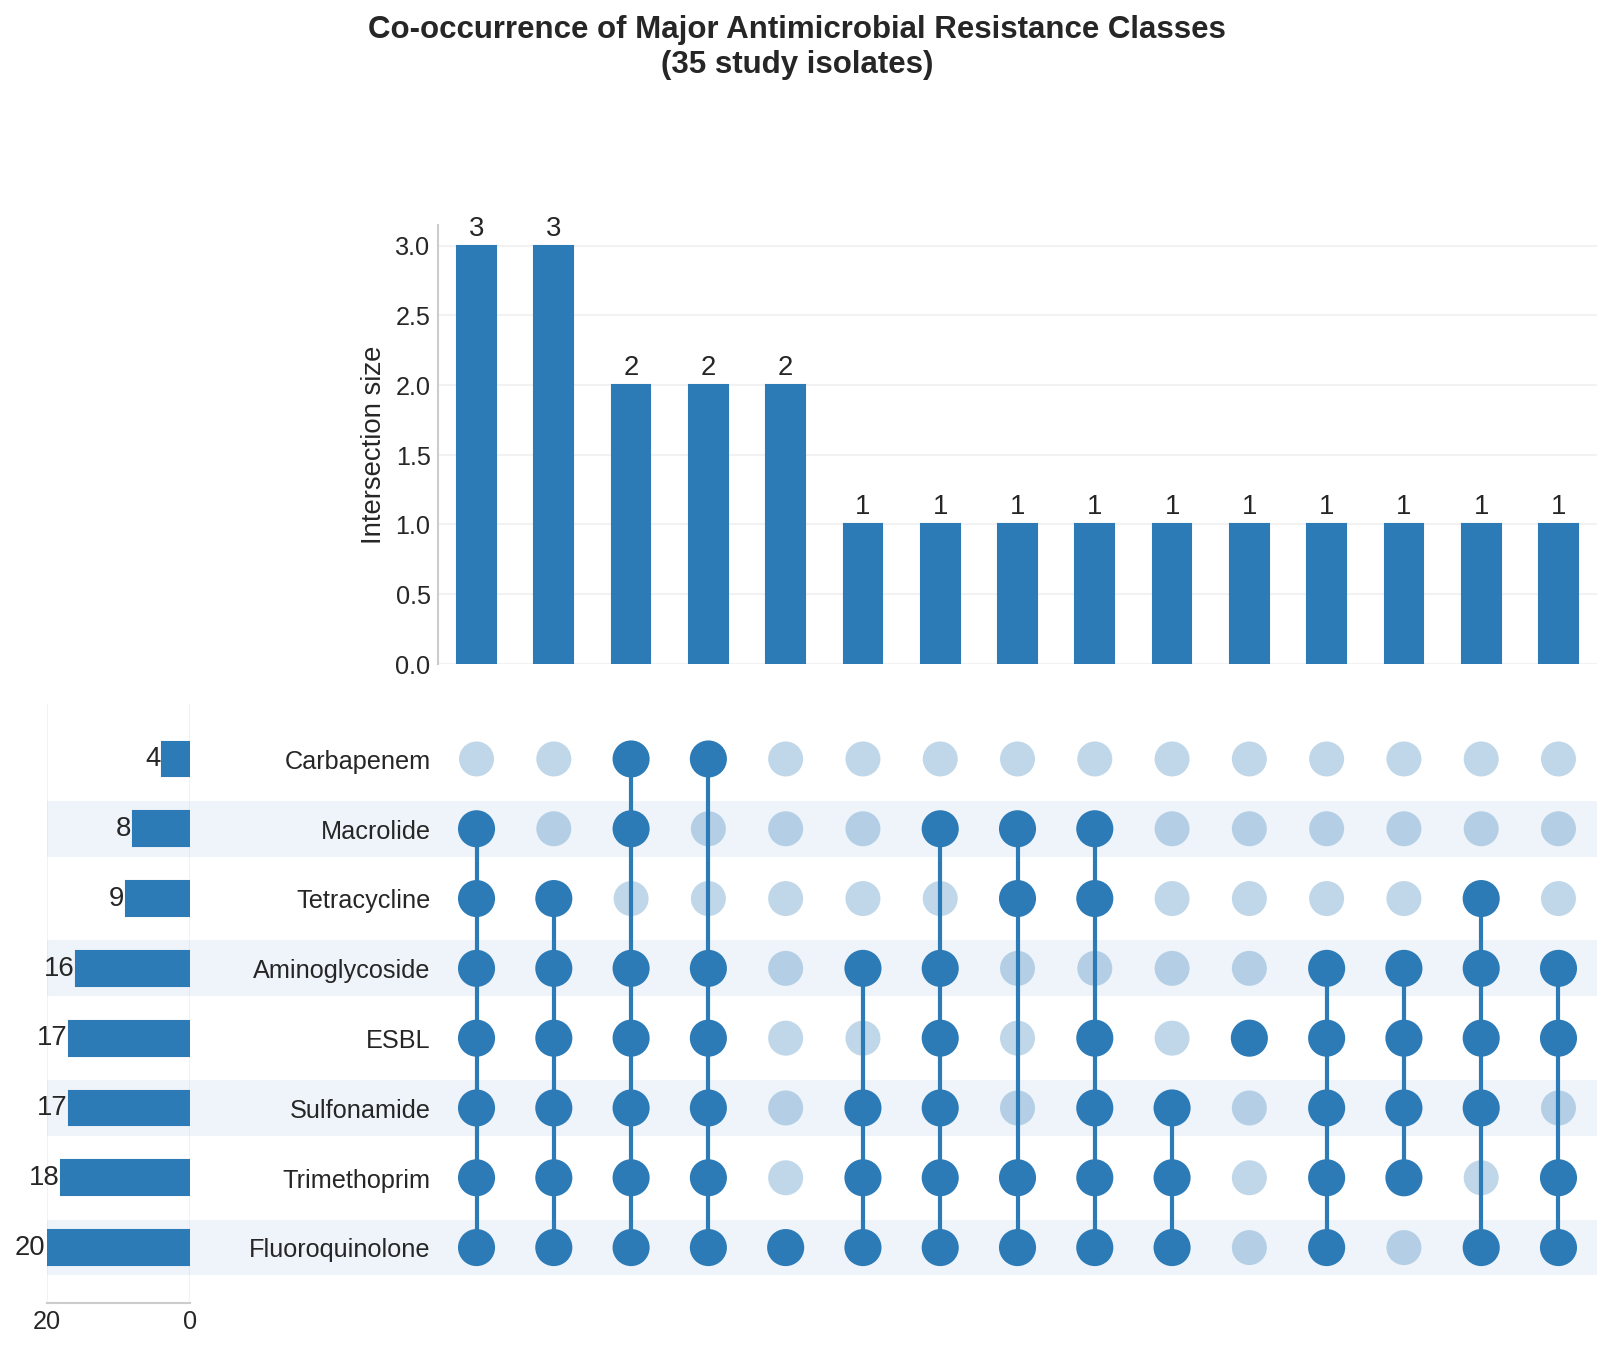

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# UPSET PLOT – Local 35 isolates (Colourful version)
# ============================================================

!pip install -q upsetplot
from upsetplot import from_indicators, UpSet
import matplotlib.pyplot as plt
import matplotlib as mpl

# Set a nice colour palette
plt.style.use('seaborn-v0_8-whitegrid')
mpl.rcParams['axes.prop_cycle'] = mpl.cycler(color=[
    '#e41a1c', '#377eb8', '#4daf4a', '#984ea3',
    '#ff7f00', '#a65628', '#f781bf', '#999999', '#66c2a5'
])

resistance_cols = ['Carbapenem', 'ESBL', 'Fluoroquinolone', 'Aminoglycoside',
                   'Tetracycline', 'Sulfonamide', 'Trimethoprim', 'Macrolide', 'Colistin']

upset_data = local_meta[resistance_cols].copy()
upset_data = upset_data[upset_data.sum(axis=1) > 0]

print(f"Local isolates with ≥1 major resistance class: {len(upset_data)}")

upset_input = from_indicators(resistance_cols, data=upset_data.astype(bool))

# Create the plot with more visual appeal
fig = plt.figure(figsize=(14, 8))

upset = UpSet(
    upset_input,
    subset_size='count',
    show_counts=True,
    sort_by='cardinality',
    element_size=48,
    facecolor='#2c7bb6',          # colour of the intersection bars
    other_dots_color=0.3,         # lighter colour for non-connected dots
    shading_color=0.08            # light background shading
)

upset.plot()

plt.suptitle("Co-occurrence of Major Antimicrobial Resistance Classes\n(35 study isolates)",
             fontsize=15, fontweight='bold', y=1.03)

# Optional: improve the look of the count numbers
for ax in fig.axes:
    for text in ax.texts:
        text.set_fontsize(10)
        text.set_fontweight('medium')

plt.savefig("Fig_Upset_Local35_colourful.pdf", bbox_inches='tight', dpi=600)
plt.savefig("Fig_Upset_Local35_colourful.png", dpi=600)
plt.show()files.download("Fig_Upset_Local35_colourful.png")

Local isolates with ≥1 major resistance class: 22


<Figure size 2100x1200 with 0 Axes>

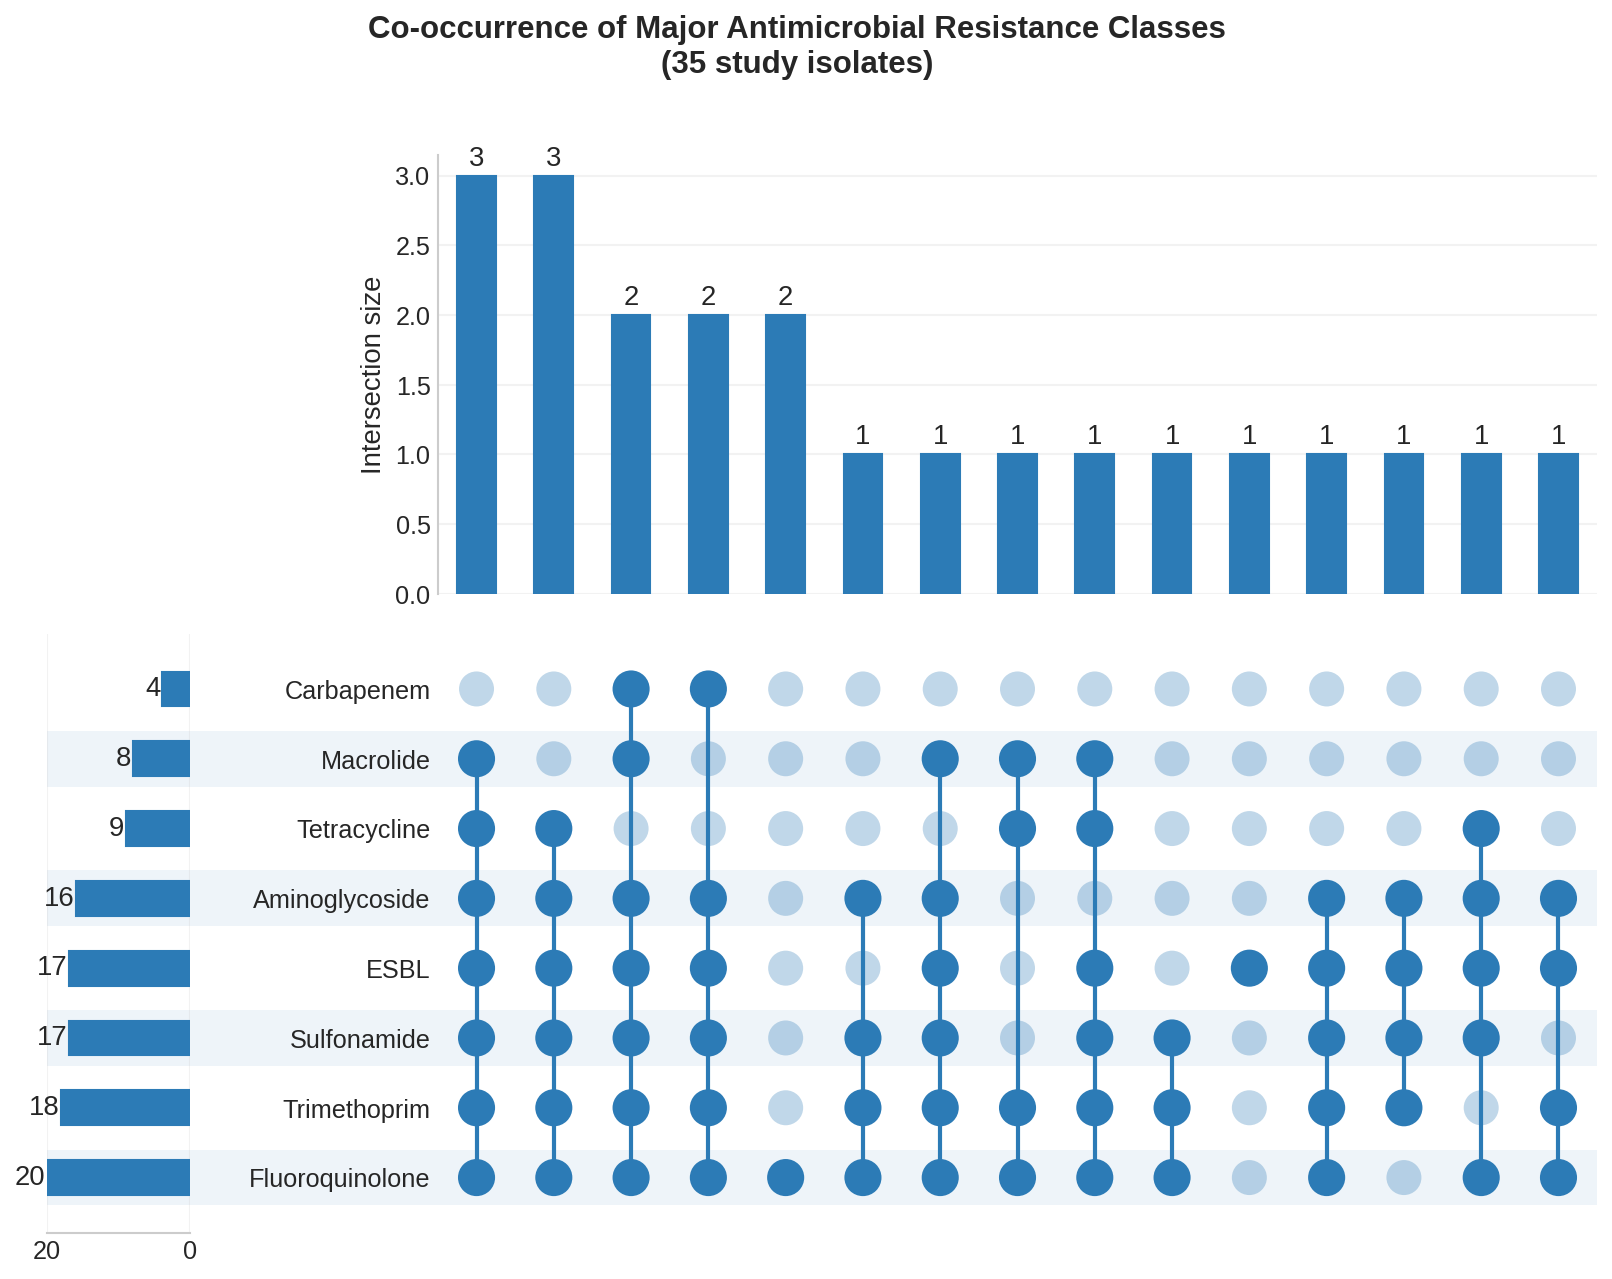

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# UPSET PLOT – Local 35 isolates (Colourful version)
# ============================================================

!pip install -q upsetplot
from upsetplot import from_indicators, UpSet
import matplotlib.pyplot as plt
import matplotlib as mpl

# Set a nice colour palette
plt.style.use('seaborn-v0_8-whitegrid')
mpl.rcParams['axes.prop_cycle'] = mpl.cycler(color=[
    '#e41a1c', '#377eb8', '#4daf4a', '#984ea3',
    '#ff7f00', '#a65628', '#f781bf', '#999999', '#66c2a5'
])

resistance_cols = ['Carbapenem', 'ESBL', 'Fluoroquinolone', 'Aminoglycoside',
                   'Tetracycline', 'Sulfonamide', 'Trimethoprim', 'Macrolide', 'Colistin']

upset_data = local_meta[resistance_cols].copy()
upset_data = upset_data[upset_data.sum(axis=1) > 0]

print(f"Local isolates with ≥1 major resistance class: {len(upset_data)}")

upset_input = from_indicators(resistance_cols, data=upset_data.astype(bool))

# Create the plot with more visual appeal
fig = plt.figure(figsize=(14, 8))

upset = UpSet(
    upset_input,
    subset_size='count',
    show_counts=True,
    sort_by='cardinality',
    element_size=48,
    facecolor='#2c7bb6',          # colour of the intersection bars
    other_dots_color=0.3,         # lighter colour for non-connected dots
    shading_color=0.08            # light background shading
)

upset.plot()

plt.suptitle("Co-occurrence of Major Antimicrobial Resistance Classes\n(35 study isolates)",
             fontsize=15, fontweight='bold')

# Optional: improve the look of the count numbers
for ax in fig.axes:
    for text in ax.texts:
        text.set_fontsize(10)
        text.set_fontweight('medium')

from google.colab import files

# Save both formats
plt.savefig("Fig_Upset_Local35_colourful.pdf", bbox_inches='tight', dpi=600)
plt.savefig("Fig_Upset_Local35_colourful.png", bbox_inches='tight', dpi=600)
plt.show()

In [ ]:
# Download both files
files.download("Fig_Upset_Local35_colourful.pdf")
files.download("Fig_Upset_Local35_colourful.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Figure X. Co-occurrence of major antimicrobial resistance classes among the 35 local Klebsiella pneumoniae isolates.**

Among the 35 local isolates, fluoroquinolone resistance was the most frequent resistance class (n = 20), followed by trimethoprim (n = 18), sulfonamide and ESBL (n = 17 each), and aminoglycoside resistance (n = 16). Macrolide (n = 8) and carbapenem (n = 4) resistance were less common.
The Upset plot revealed substantial co-occurrence of resistance determinants. The two largest intersections (each containing three isolates) represented broad multi-drug resistance profiles that included fluoroquinolone, trimethoprim, sulfonamide, ESBL and aminoglycoside resistance, with or without additional classes. Several combinations of four to six resistance classes were observed, indicating that multi-drug resistance is common in this collection. Carbapenem resistance, although infrequent (n = 4), co-occurred with multiple other resistance classes in three of the four carbapenemase-producing isolates, consistent with extensively drug-resistant phenotypes.
Overall, the plot demonstrates that resistance to the most commonly used antibiotic classes rarely occurs in isolation and frequently clusters into complex multi-resistance patterns.




## SANKEY diagram

In [ ]:
# ============================================================
# 1. ALLUVIAL / SANKEY DIAGRAM
#    ST → K-type → Carbapenemase status
# ============================================================

!pip install -q plotly

import plotly.graph_objects as go
import pandas as pd
import numpy as np

# Prepare data (use top STs and top K-types to keep the plot readable)
top_sts = meta['klebsiella_pneumo_complex__mlst__ST'].value_counts().head(8).index.tolist()
top_ks  = meta['klebsiella_pneumo_complex__kaptive__K_type'].value_counts().head(8).index.tolist()

sankey_df = meta[
    meta['klebsiella_pneumo_complex__mlst__ST'].isin(top_sts) &
    meta['klebsiella_pneumo_complex__kaptive__K_type'].isin(top_ks)
].copy()

sankey_df['Carbapenemase'] = np.where(sankey_df['carbapenemase'], 'Carbapenemase+', 'Carbapenemase-')

# Create node labels
st_labels  = sorted(sankey_df['klebsiella_pneumo_complex__mlst__ST'].unique())
k_labels   = sorted(sankey_df['klebsiella_pneumo_complex__kaptive__K_type'].unique())
carb_labels = ['Carbapenemase-', 'Carbapenemase+']

all_labels = st_labels + k_labels + carb_labels

# Mapping
label_to_idx = {lab: i for i, lab in enumerate(all_labels)}

# Build links: ST → K-type
link1 = sankey_df.groupby(
    ['klebsiella_pneumo_complex__mlst__ST', 'klebsiella_pneumo_complex__kaptive__K_type']
).size().reset_index(name='value')

# Build links: K-type → Carbapenemase
link2 = sankey_df.groupby(
    ['klebsiella_pneumo_complex__kaptive__K_type', 'Carbapenemase']
).size().reset_index(name='value')

sources, targets, values = [], [], []

for _, row in link1.iterrows():
    sources.append(label_to_idx[row['klebsiella_pneumo_complex__mlst__ST']])
    targets.append(label_to_idx[row['klebsiella_pneumo_complex__kaptive__K_type']])
    values.append(row['value'])

for _, row in link2.iterrows():
    sources.append(label_to_idx[row['klebsiella_pneumo_complex__kaptive__K_type']])
    targets.append(label_to_idx[row['Carbapenemase']])
    values.append(row['value'])

fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=18,
        thickness=22,
        line=dict(color="black", width=0.4),
        label=all_labels,
        color=["#4e79a7"]*len(st_labels) + ["#f28e2b"]*len(k_labels) + ["#59a14f", "#e15759"]
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color='rgba(150,150,150,0.35)'
    )
)])

fig.update_layout(
    title_text="Alluvial Diagram: Sequence Type → K-type → Carbapenemase Status",
    font_size=12,
    height=650,
    width=1100
)
fig.show()
fig.write_html("Sankey_ST_K_Carbapenemase.html")
print("Sankey diagram saved as Sankey_ST_K_Carbapenemase.html")

Sankey diagram saved as Sankey_ST_K_Carbapenemase.html


## SANKEY for 35 isolate

In [ ]:
# ============================================================
# SANKEY / ALLUVIAL – Local 35 isolates
# ST → K-type → Carbapenemase status
# ============================================================

!pip install -q plotly
import plotly.graph_objects as go

# Use all STs and K-types present in the 35 isolates (no need to filter further)
sankey_df = local_meta.copy()
sankey_df['Carbapenemase'] = np.where(sankey_df['carbapenemase'], 'Carbapenemase+', 'Carbapenemase-')

st_labels   = sorted(sankey_df['klebsiella_pneumo_complex__mlst__ST'].dropna().unique())
k_labels    = sorted(sankey_df['klebsiella_pneumo_complex__kaptive__K_type'].dropna().unique())
carb_labels = ['Carbapenemase-', 'Carbapenemase+']

all_labels = st_labels + k_labels + carb_labels
label_to_idx = {lab: i for i, lab in enumerate(all_labels)}

# Links: ST → K-type
link1 = sankey_df.groupby(
    ['klebsiella_pneumo_complex__mlst__ST', 'klebsiella_pneumo_complex__kaptive__K_type']
).size().reset_index(name='value')

# Links: K-type → Carbapenemase
link2 = sankey_df.groupby(
    ['klebsiella_pneumo_complex__kaptive__K_type', 'Carbapenemase']
).size().reset_index(name='value')

sources, targets, values = [], [], []

for _, row in link1.iterrows():
    sources.append(label_to_idx[row['klebsiella_pneumo_complex__mlst__ST']])
    targets.append(label_to_idx[row['klebsiella_pneumo_complex__kaptive__K_type']])
    values.append(row['value'])

for _, row in link2.iterrows():
    sources.append(label_to_idx[row['klebsiella_pneumo_complex__kaptive__K_type']])
    targets.append(label_to_idx[row['Carbapenemase']])
    values.append(row['value'])

fig = go.Figure(data=[go.Sankey(
    node = dict(
        pad = 18,
        thickness = 20,
        line = dict(color = "black", width = 0.5),
        label = all_labels,
        color = ["#4e79a7"]*len(st_labels) + ["#f28e2b"]*len(k_labels) + ["#59a14f", "#e15759"]
    ),
    link = dict(
        source = sources,
        target = targets,
        value = values,
        color = 'rgba(120,120,120,0.4)'
    )
)])

fig.update_layout(
    title_text = "Alluvial Diagram: ST → K-type → Carbapenemase Status",
    font_size = 12,
    height = 600,
    width = 1000
)

fig.show()
fig.write_html("Sankey_Local35_ST_K_Carbapenemase.html")
print("Sankey diagram saved as Sankey_Local35_ST_K_Carbapenemase.html")

NameError: name 'local_meta' is not defined

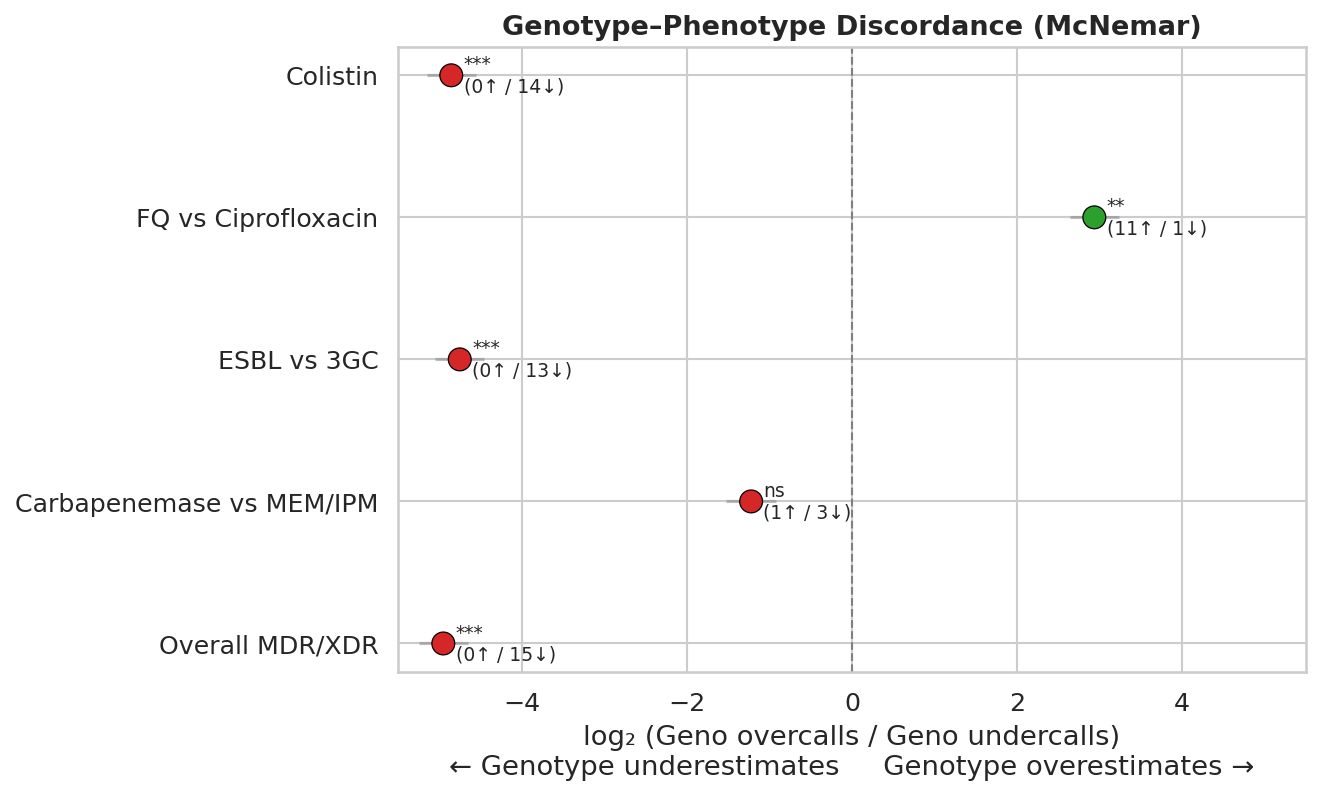

In [ ]:
# ============================================================
# 2. FOREST-STYLE PLOT of McNemar discordance
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ---- Paste your McNemar results here ----
# Format: (Category, overcalls, undercalls, p_value)
mcnemar_results = [
    ("Overall MDR/XDR",          0, 15, 6.104e-05),
    ("Carbapenemase vs MEM/IPM", 1,  3, 0.625),
    ("ESBL vs 3GC",              0, 13, 0.0002441),
    ("FQ vs Ciprofloxacin",     11,  1, 0.006348),
    ("Colistin",                 0, 14, 0.0001221),
]

categories = [r[0] for r in mcnemar_results]
overcalls  = np.array([r[1] for r in mcnemar_results])
undercalls = np.array([r[2] for r in mcnemar_results])
pvals      = [r[3] for r in mcnemar_results]

# Discordance direction: positive = overcall (geno > pheno), negative = undercall
discordance = overcalls - undercalls
total_discord = overcalls + undercalls

# Approximate log2 odds-like measure for visualisation
# (positive = geno overestimates, negative = geno underestimates)
effect = np.log2((overcalls + 0.5) / (undercalls + 0.5))

fig, ax = plt.subplots(figsize=(9, 5.5))

colors = ['#d62728' if e < 0 else '#2ca02c' for e in effect]
y_pos = np.arange(len(categories))

ax.axvline(0, color='grey', linestyle='--', lw=1)
ax.scatter(effect, y_pos, s=120, c=colors, zorder=3, edgecolor='black', linewidth=0.6)

# Add error-like bars based on total discordance (for visual weight)
ax.hlines(y_pos, effect - 0.3, effect + 0.3, color='grey', alpha=0.5, lw=1.5)

for i, (e, p, o, u) in enumerate(zip(effect, pvals, overcalls, undercalls)):
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
    ax.text(e + 0.15, i, f"{sig}\n({o}↑ / {u}↓)", va='center', fontsize=9)

ax.set_yticks(y_pos)
ax.set_yticklabels(categories)
ax.set_xlabel("log₂ (Geno overcalls / Geno undercalls)\n← Genotype underestimates     Genotype overestimates →")
ax.set_title("Genotype–Phenotype Discordance (McNemar)", fontweight='bold', fontsize=13)
ax.set_xlim(-5.5, 5.5)

plt.tight_layout()
plt.savefig("Fig_Forest_McNemar_Discordance.pdf", dpi=600, bbox_inches='tight')
plt.show()

Shannon diversity summary:
                 count   mean    std  min    25%    50%    75%   max
high_risk_clone                                                     
False            485.0  2.168  1.017  0.0  2.322  2.585  2.807  3.17
True             268.0  2.489  0.637  0.0  2.585  2.585  2.807  3.17


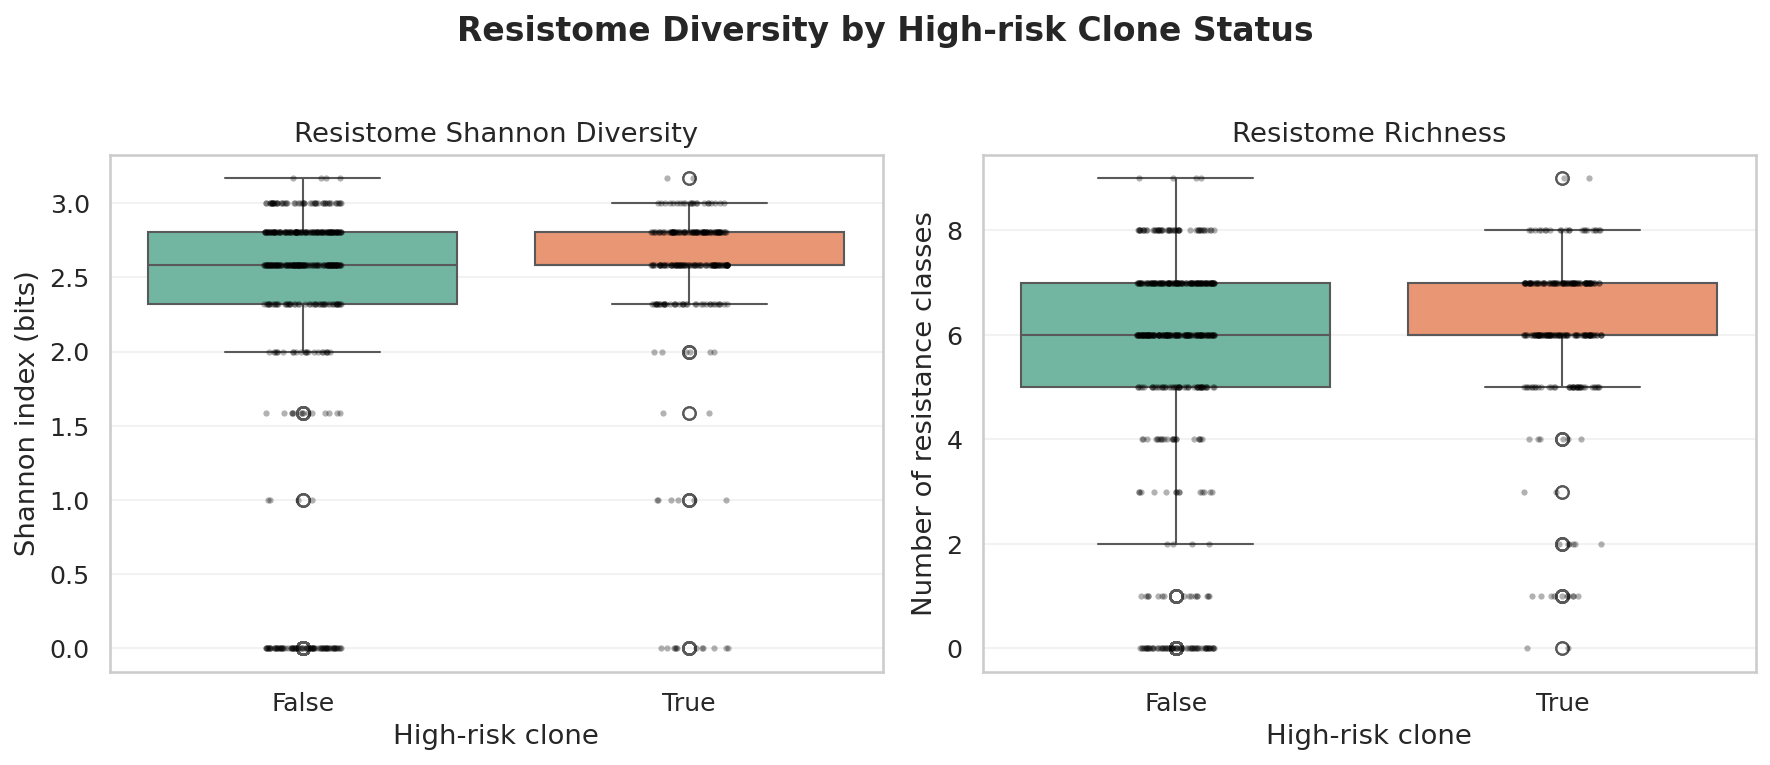


Mann-Whitney U test (Shannon diversity):
  U = 73017.0, p = 3.8611e-03


In [ ]:
# ============================================================
# 3. SHANNON DIVERSITY OF RESISTOME BY CLONE TYPE
# ============================================================

from scipy.stats import entropy
import seaborn as sns

# Create a simple resistome presence matrix from the major classes
resistome_cols = ['Carbapenem', 'ESBL', 'Fluoroquinolone', 'Aminoglycoside',
                  'Tetracycline', 'Sulfonamide', 'Trimethoprim', 'Macrolide', 'Colistin']

# Shannon diversity per isolate
def shannon_diversity(row):
    counts = row.values
    if counts.sum() == 0:
        return 0.0
    return entropy(counts, base=2)

meta['resistome_shannon'] = meta[resistome_cols].apply(shannon_diversity, axis=1)
meta['resistome_richness'] = meta[resistome_cols].sum(axis=1)

print("Shannon diversity summary:")
print(meta.groupby('high_risk_clone')['resistome_shannon'].describe().round(3))

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=meta, x='high_risk_clone', y='resistome_shannon', ax=axes[0], palette='Set2')
sns.stripplot(data=meta, x='high_risk_clone', y='resistome_shannon', ax=axes[0],
              color='black', alpha=0.3, size=3)
axes[0].set_title("Resistome Shannon Diversity")
axes[0].set_xlabel("High-risk clone")
axes[0].set_ylabel("Shannon index (bits)")

sns.boxplot(data=meta, x='high_risk_clone', y='resistome_richness', ax=axes[1], palette='Set2')
sns.stripplot(data=meta, x='high_risk_clone', y='resistome_richness', ax=axes[1],
              color='black', alpha=0.3, size=3)
axes[1].set_title("Resistome Richness")
axes[1].set_xlabel("High-risk clone")
axes[1].set_ylabel("Number of resistance classes")

plt.suptitle("Resistome Diversity by High-risk Clone Status", fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("Fig_Shannon_Resistome_Diversity.pdf", dpi=600, bbox_inches='tight')
plt.show()

# Optional statistical test
from scipy.stats import mannwhitneyu
hr = meta.loc[meta['high_risk_clone'], 'resistome_shannon'].dropna()
other = meta.loc[~meta['high_risk_clone'], 'resistome_shannon'].dropna()
stat, p = mannwhitneyu(hr, other, alternative='two-sided')
print(f"\nMann-Whitney U test (Shannon diversity):\n  U = {stat:.1f}, p = {p:.4e}")

# PROPHAGE ANALYSIS – Local 35 isolates

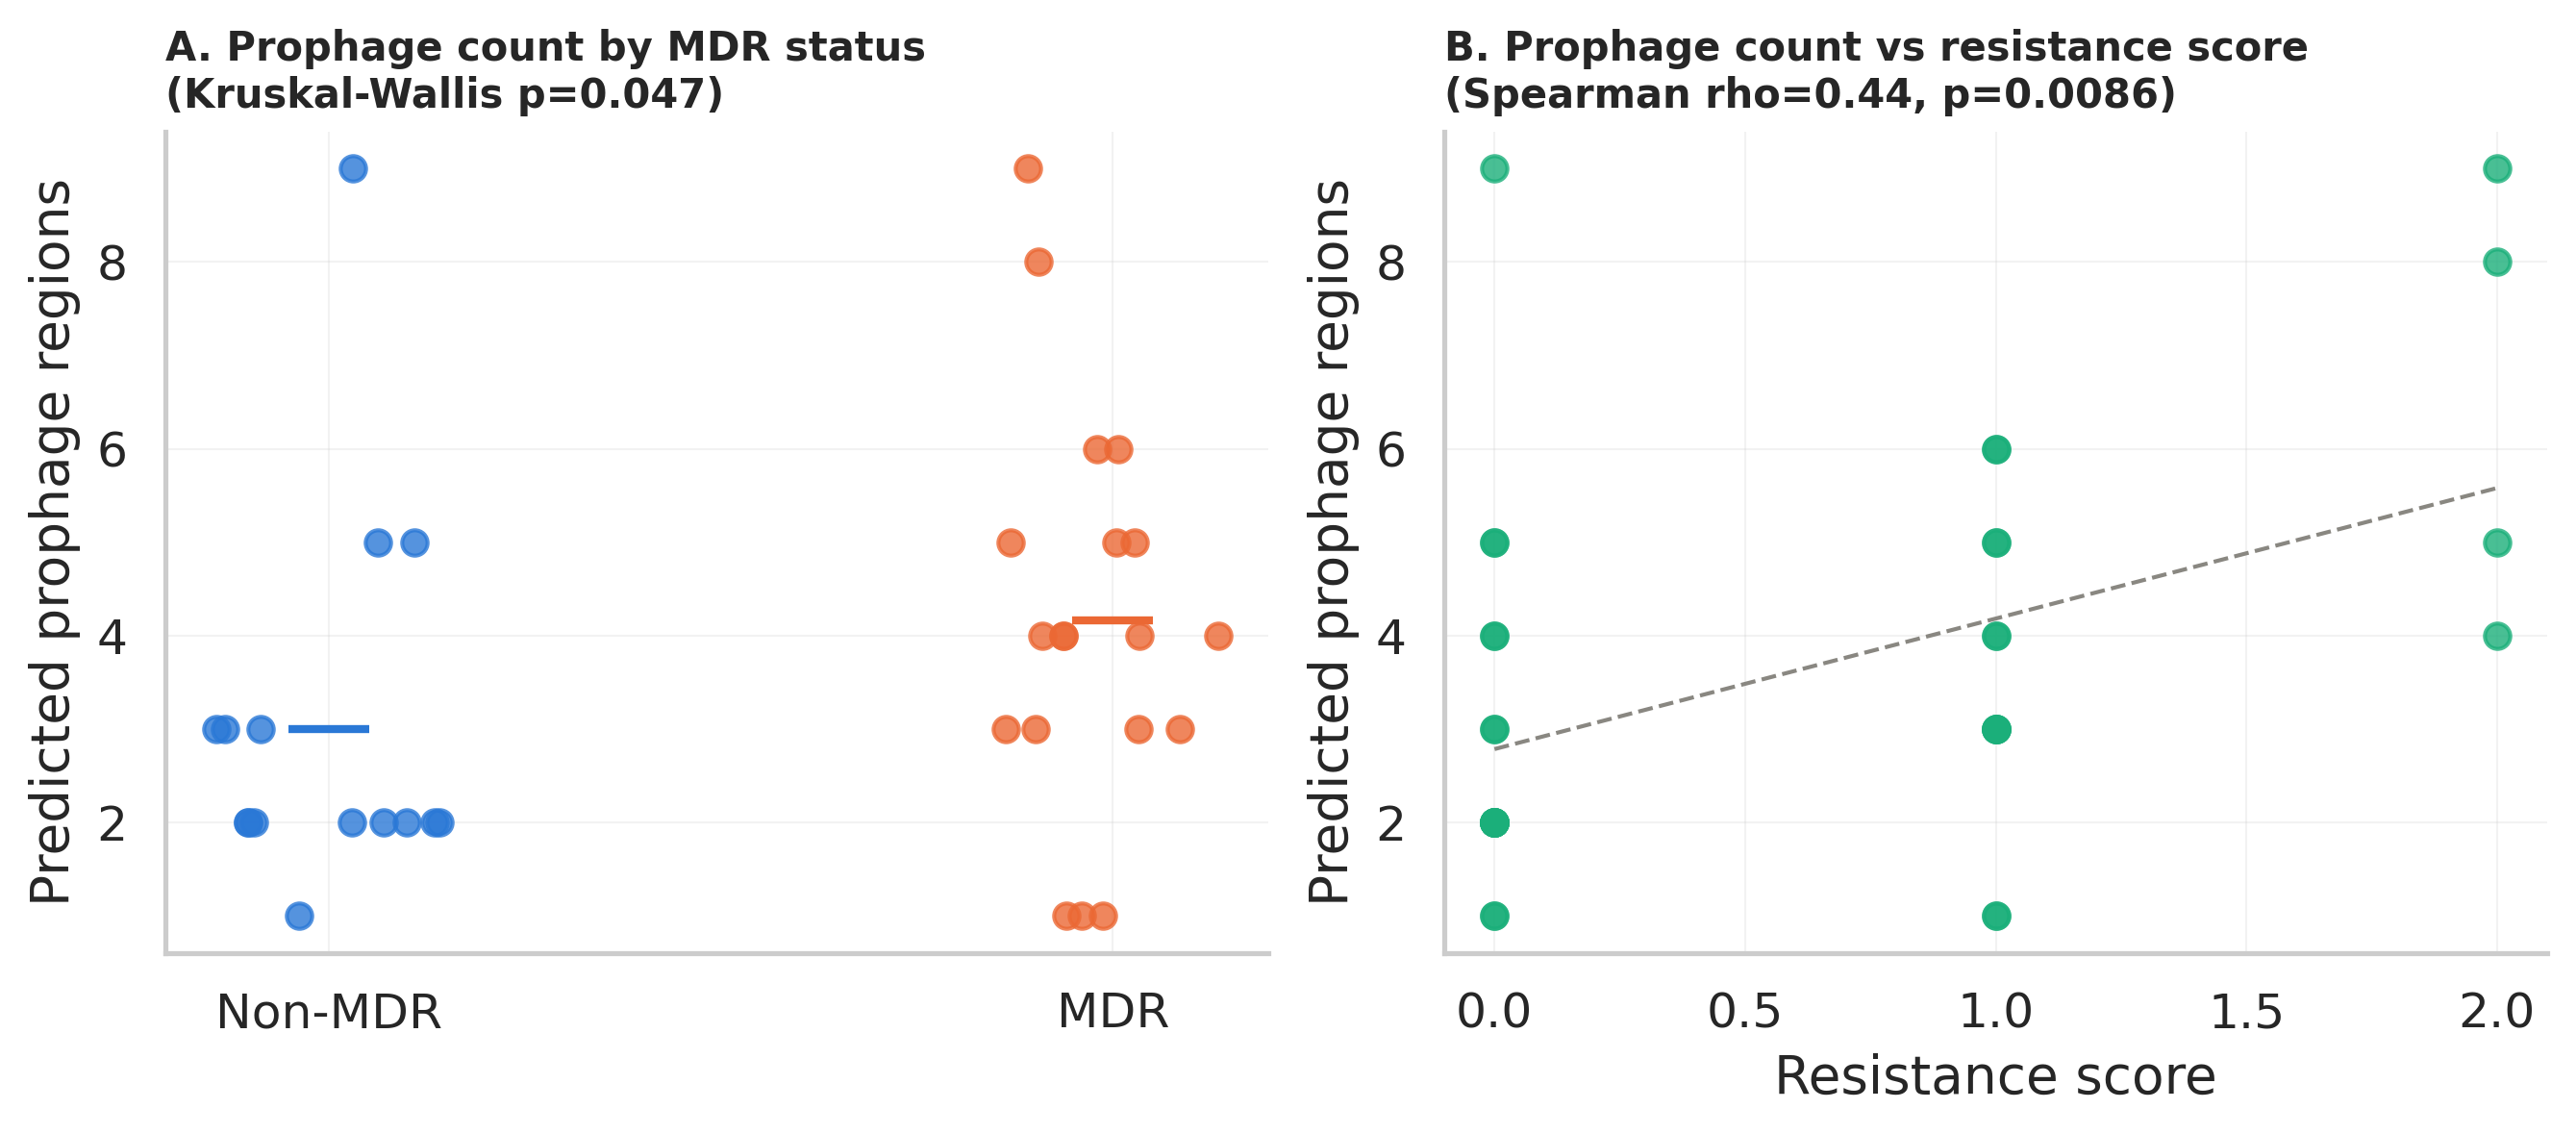

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'figure.dpi': 300,
})

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

# Panel A: jittered strip plot, prophage count by MDR status
np.random.seed(42)
groups = ['Non-MDR', 'MDR']
colors = {'Non-MDR': '#2a78d6', 'MDR': '#eb6834'}
for i, g in enumerate(groups):
    vals = overlap[overlap.mdr_status == g]['n_proviruses']
    jitter = np.random.uniform(-0.15, 0.15, len(vals))
    axes[0].scatter(np.full(len(vals), i) + jitter, vals, color=colors[g], alpha=0.8, s=40)
    axes[0].scatter(i, vals.mean(), color=colors[g], marker='_', s=400, linewidths=2)  # mean marker

axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(groups)
axes[0].set_ylabel('Predicted prophage regions')
axes[0].set_title('A. Prophage count by MDR status\n(Kruskal-Wallis p=0.047)', loc='left', fontweight='bold', fontsize=10)

# Panel B: scatter, resistance score vs prophage count
axes[1].scatter(overlap[RES_SCORE_COL], overlap['n_proviruses'], color='#1baf7a', alpha=0.8, s=40)
z = np.polyfit(overlap[RES_SCORE_COL], overlap['n_proviruses'], 1)
x_line = np.linspace(overlap[RES_SCORE_COL].min(), overlap[RES_SCORE_COL].max(), 10)
axes[1].plot(x_line, np.polyval(z, x_line), color='#898781', linestyle='--', linewidth=1)
axes[1].set_xlabel('Resistance score')
axes[1].set_ylabel('Predicted prophage regions')
axes[1].set_title('B. Prophage count vs resistance score\n(Spearman rho=0.44, p=0.0086)', loc='left', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('Figure_prophage_MDR_correlation.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ============================================================
# PROPHAGE ANALYSIS – Local 35 isolates
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 600

# ---------- 1. Load data ----------
prophage_summary = pd.read_csv("prophage_isolate_summary.tsv", sep="\t")
master_prophage = pd.read_csv("master_prophage_summary.tsv", sep="\t")
metadata = pd.read_csv("global754_final_metadata_with_source_category.csv", sep="\t")

# Keep only your local isolates
local_prophage = prophage_summary[prophage_summary['isolate'].str.startswith('NSUCE-')].copy()
print(f"Number of local isolates with prophage data: {len(local_prophage)}")

# ---------- 2. Basic summary ----------
print("\n=== Prophage burden summary ===")
print(local_prophage[['n_proviruses', 'total_provirus_bp', 'total_provirus_genes',
                      'mean_virus_score', 'total_hallmarks']].describe().round(2))

print("\nTop 5 isolates by number of prophages:")
print(local_prophage.sort_values('n_proviruses', ascending=False)[['isolate', 'n_proviruses', 'total_provirus_bp']].head())

# ---------- 3. Useful Figures ----------

Number of local isolates with prophage data: 35

=== Prophage burden summary ===
       n_proviruses  total_provirus_bp  total_provirus_genes  mean_virus_score  total_hallmarks
count         35.00              35.00                 35.00              35.0            35.00
mean           3.57          117283.03                158.49               1.0            41.29
std            2.15           58203.15                 78.32               0.0            24.28
min            1.00           47206.00                 61.00               1.0            13.00
25%            2.00           68499.50                 92.00               1.0            22.00
50%            3.00          104939.00                139.00               1.0            39.00
75%            5.00          142788.50                213.00               1.0            55.50
max            9.00          232780.00                337.00               1.0           112.00

Top 5 isolates by number of prophages:
      isolate  

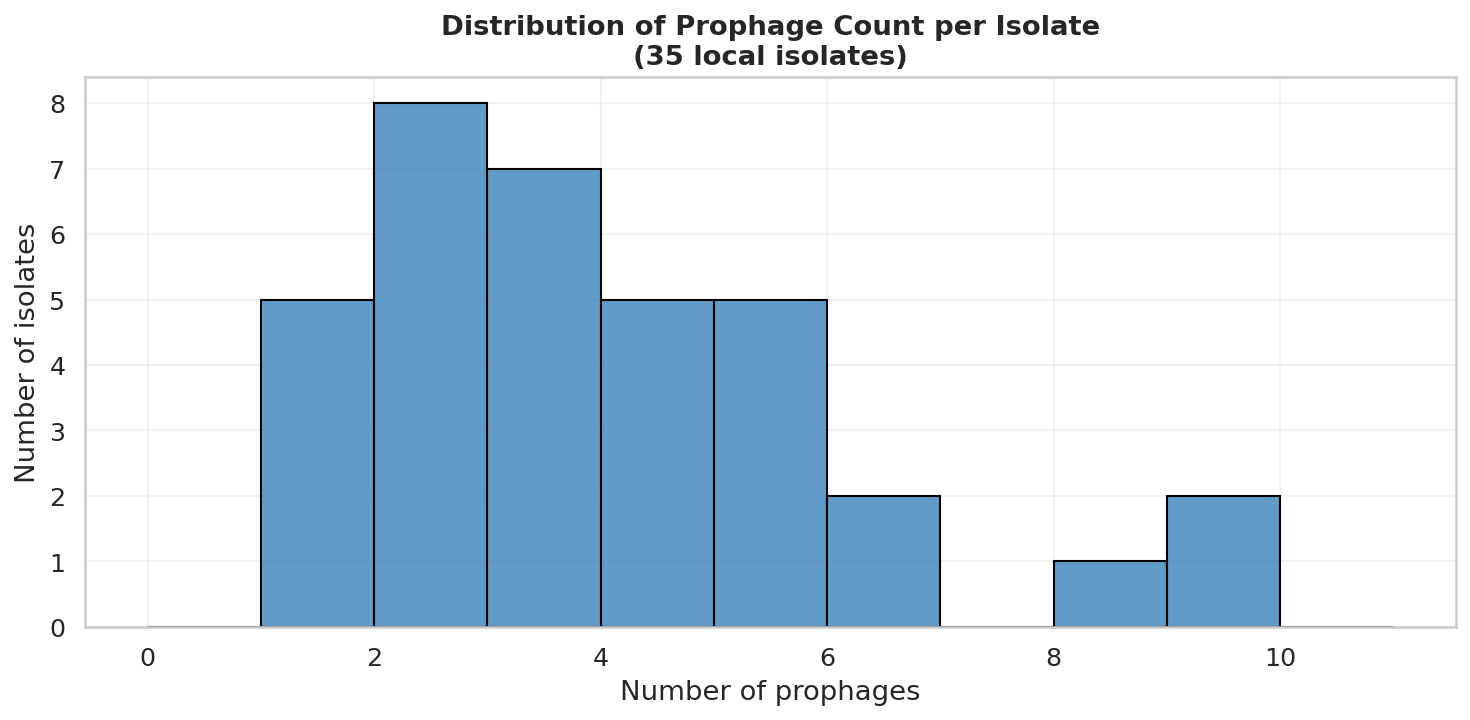

In [ ]:
# Figure 1: Number of prophages per isolate
plt.figure(figsize=(10, 5))
sns.histplot(local_prophage['n_proviruses'], bins=range(0, 12), kde=False, color='#2c7bb6', edgecolor='black')
plt.title("Distribution of Prophage Count per Isolate\n(35 local isolates)", fontweight='bold')
plt.xlabel("Number of prophages")
plt.ylabel("Number of isolates")
plt.tight_layout()
plt.savefig("Fig_Prophage_Count_Distribution.png", dpi=600, bbox_inches='tight')
plt.show()

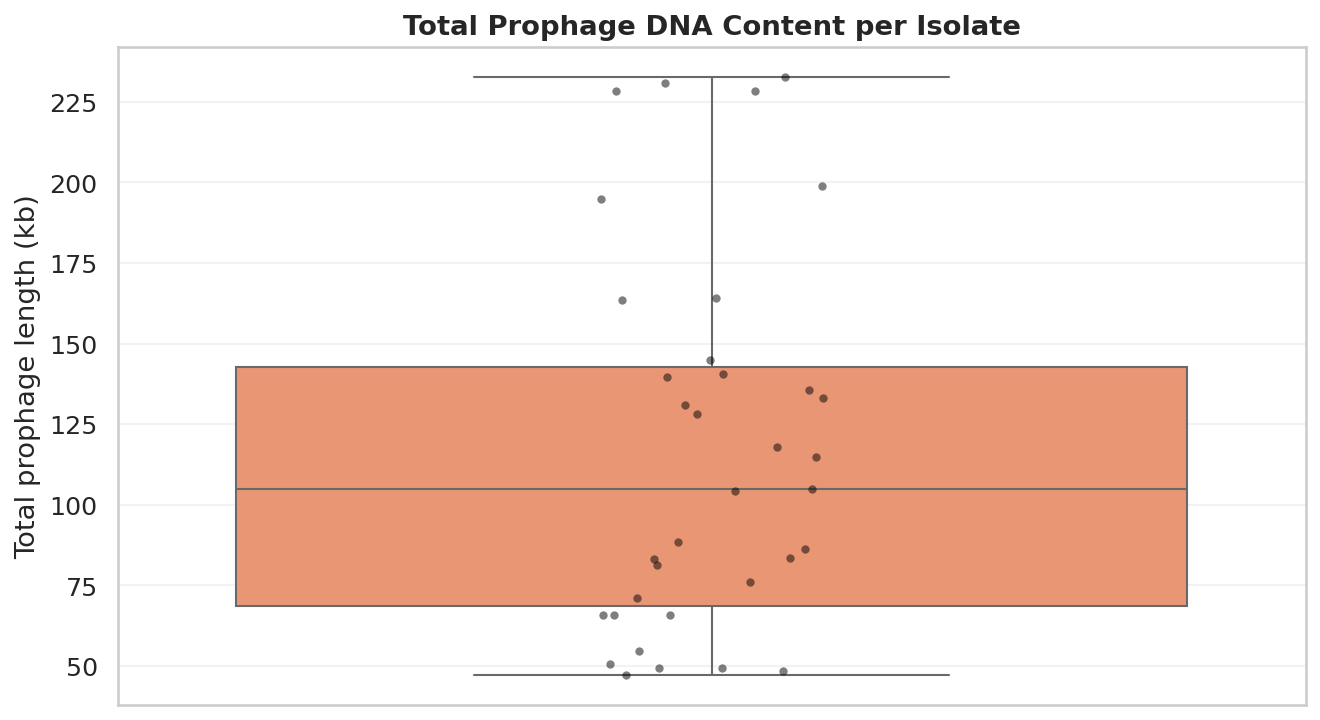

In [ ]:
# Figure 2: Total prophage genome size
plt.figure(figsize=(9, 5))
sns.boxplot(y=local_prophage['total_provirus_bp'] / 1000, color='#fc8d62')
sns.stripplot(y=local_prophage['total_provirus_bp'] / 1000, color='black', alpha=0.5, size=4)
plt.title("Total Prophage DNA Content per Isolate", fontweight='bold')
plt.ylabel("Total prophage length (kb)")
plt.tight_layout()
plt.savefig("Fig_Prophage_Total_Size.png", dpi=600, bbox_inches='tight')
plt.show()

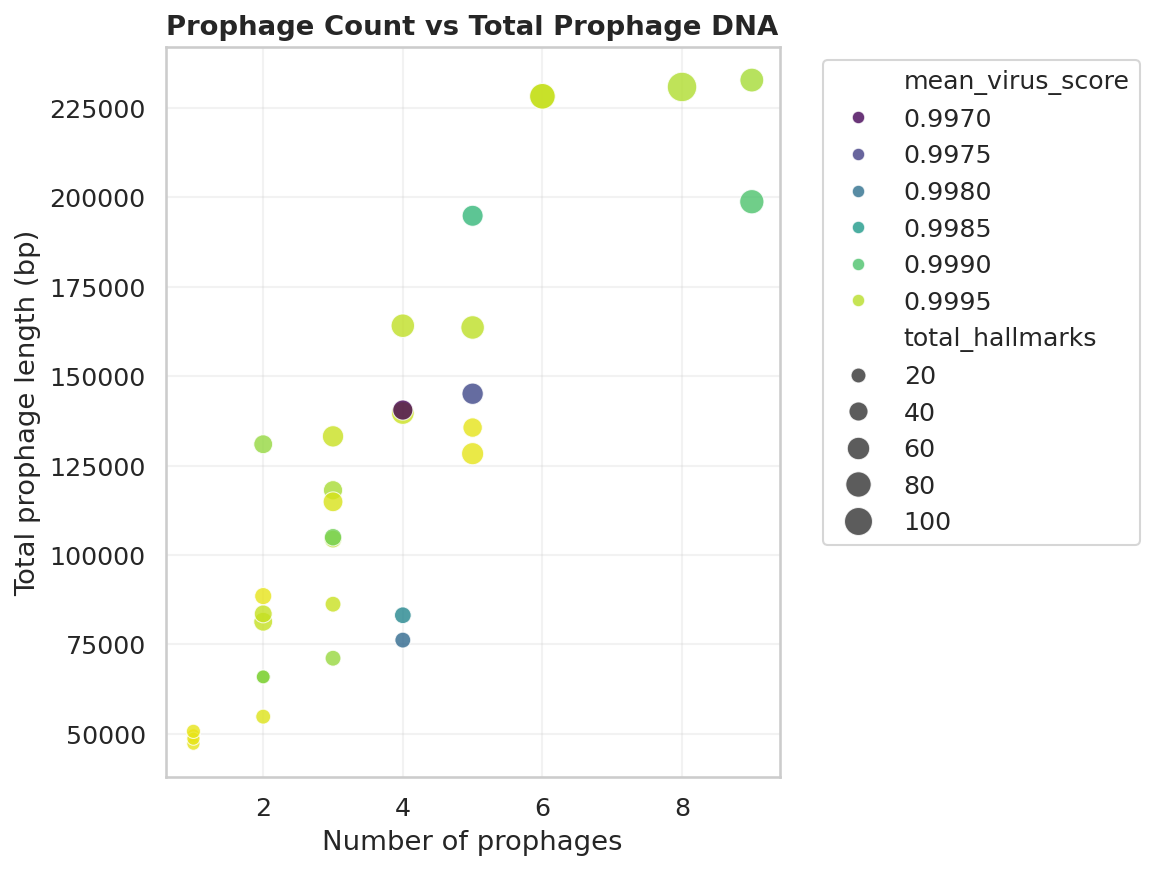

In [ ]:
# Figure 3: Relationship between number of prophages and total size
plt.figure(figsize=(8, 6))
sns.scatterplot(data=local_prophage, x='n_proviruses', y='total_provirus_bp',
                size='total_hallmarks', hue='mean_virus_score',
                palette='viridis', sizes=(40, 200), alpha=0.8)
plt.title("Prophage Count vs Total Prophage DNA", fontweight='bold')
plt.xlabel("Number of prophages")
plt.ylabel("Total prophage length (bp)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig("Fig_Prophage_Count_vs_Size.png", dpi=600, bbox_inches='tight')
plt.show()

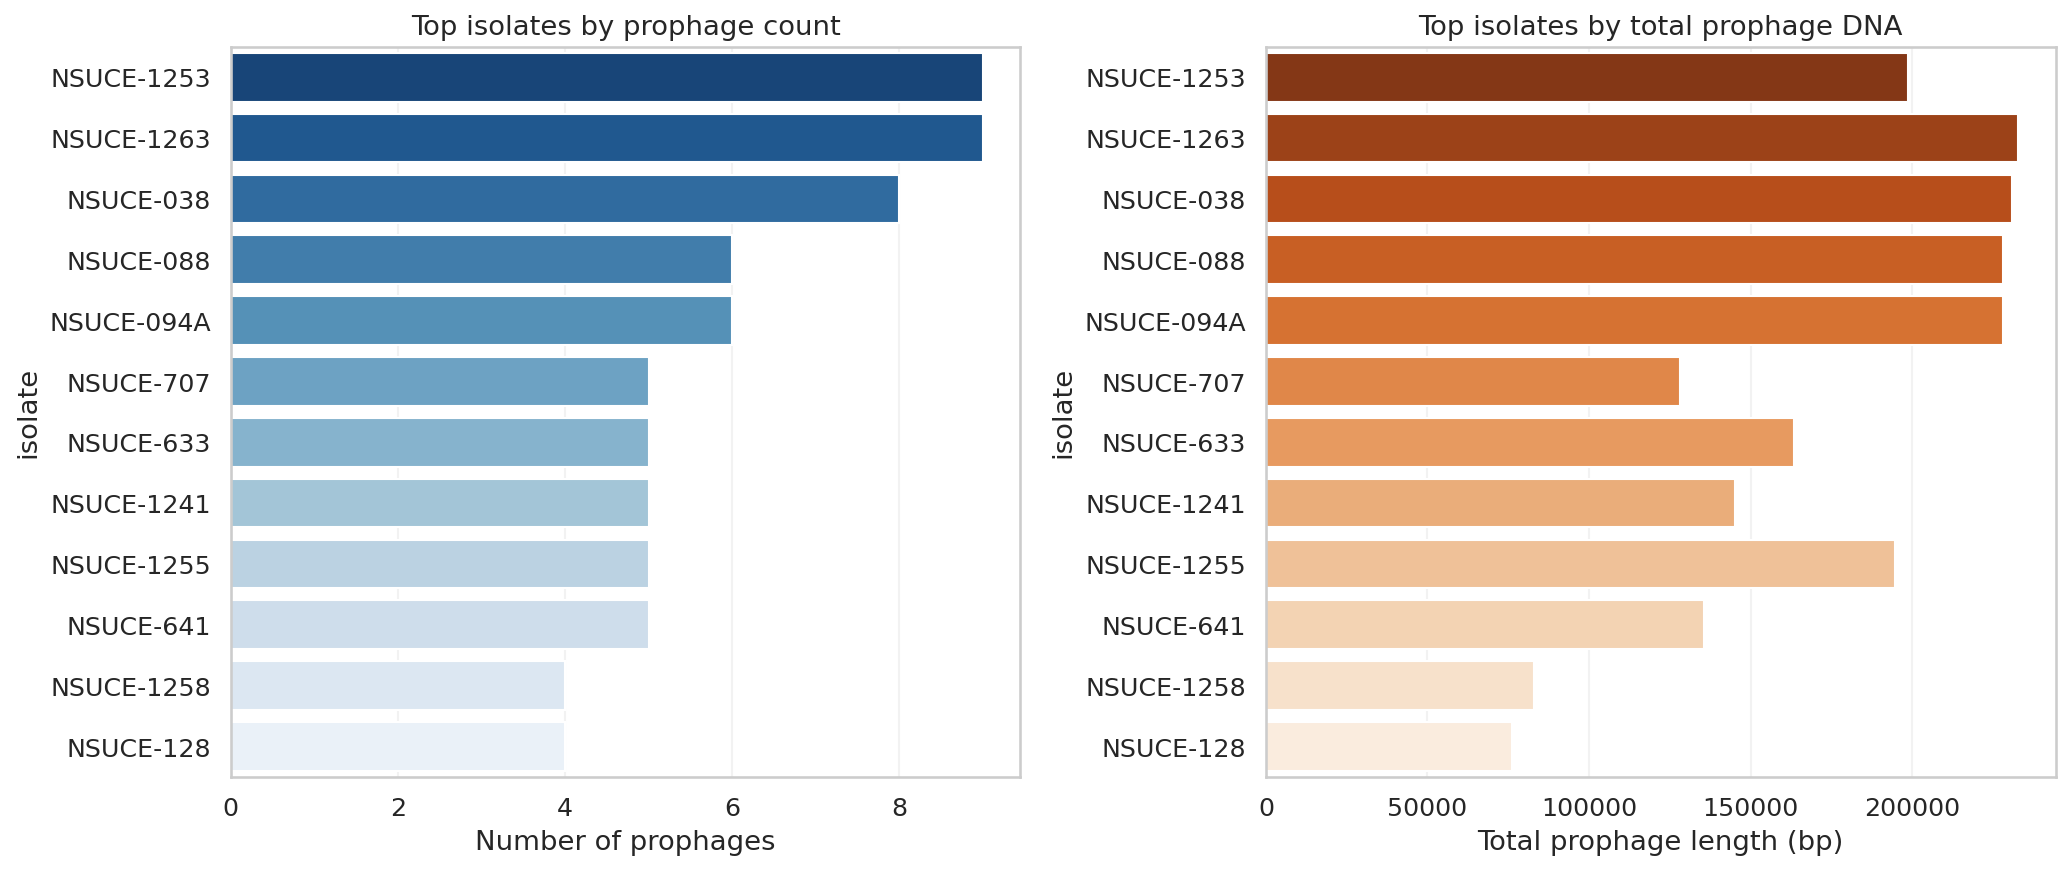

In [ ]:
# Figure 4: Top isolates by prophage burden
top_burden = local_prophage.sort_values('n_proviruses', ascending=False).head(12)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=top_burden, x='n_proviruses', y='isolate', ax=axes[0], palette='Blues_r')
axes[0].set_title("Top isolates by prophage count")
axes[0].set_xlabel("Number of prophages")

sns.barplot(data=top_burden, x='total_provirus_bp', y='isolate', ax=axes[1], palette='Oranges_r')
axes[1].set_title("Top isolates by total prophage DNA")
axes[1].set_xlabel("Total prophage length (bp)")
plt.tight_layout()
plt.savefig("Fig_Top_Prophage_Burden.png", dpi=600, bbox_inches='tight')
plt.show()

In [ ]:
# ---------- 4. Download figures ----------
from google.colab import files
files.download("Fig_Prophage_Count_Distribution.png")
files.download("Fig_Prophage_Total_Size.png")
files.download("Fig_Prophage_Count_vs_Size.png")
files.download("Fig_Top_Prophage_Burden.png")

# Claude
# Corrected 3-way comparison (Study / Bangladesh-public / Global-9-country)
# + Prophage burden vs MDR/XDR correlation

In [ ]:

# ==============================================================================
# Paste each "# %% Cell" block into its own Google Colab cell, in order.

# %% Cell 1 - Install/import
!pip install scipy --quiet

import pandas as pd
import numpy as np
from scipy.stats import fisher_exact, chi2_contingency, kruskal, spearmanr
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 50)

# %% Cell 2 - Upload files
from google.colab import files
print("Upload klebsiella_global753.tsv:")
u1 = files.upload()
KLEBORATE_FILE = list(u1.keys())[0]

print("Upload global754_final_metadata_with_source_category.csv:")
u2 = files.upload()
METADATA_FILE = list(u2.keys())[0]

print("Upload prophage_isolate_summary.tsv:")
u3 = files.upload()
PROPHAGE_FILE = list(u3.keys())[0]

# %% Cell 3 - Load and de-duplicate Kleborate data (GCA/GCF pairs -> one genome)
df = pd.read_csv(KLEBORATE_FILE, sep='\t', low_memory=False)
df['base_acc'] = df['strain'].str.replace(r'^(GCA|GCF)_', '', regex=True)
before = len(df)
df = df.drop_duplicates(subset='base_acc', keep='first').reset_index(drop=True)
print(f"Dropped {before - len(df)} duplicate GCA/GCF entries -> {len(df)} unique genomes")

meta = pd.read_csv(METADATA_FILE, sep='\t').rename(columns={'Genome_ID': 'strain'})
print(f"Metadata: {len(meta)} genomes, Database breakdown:")
print(meta['Database'].value_counts())



Upload klebsiella_global753.tsv:


Saving klebsiella_global753.tsv to klebsiella_global753.tsv
Upload global754_final_metadata_with_source_category.csv:


Saving global754_final_metadata_with_source_category.csv to global754_final_metadata_with_source_category.csv
Upload prophage_isolate_summary.tsv:


Saving prophage_isolate_summary.tsv to prophage_isolate_summary.tsv
Dropped 65 duplicate GCA/GCF entries -> 688 unique genomes
Metadata: 754 genomes, Database breakdown:
Database
Pathogenwatch    569
NCBI             150
This_study        35
Name: count, dtype: int64


In [ ]:
print(u1)

{'klebsiella_global753.tsv': b"strain\tenterobacterales__species__species\tenterobacterales__species__species_match\tgeneral__contig_stats__contig_count\tgeneral__contig_stats__N50\tgeneral__contig_stats__largest_contig\tgeneral__contig_stats__total_size\tgeneral__contig_stats__ambiguous_bases\tgeneral__contig_stats__QC_warnings\tklebsiella_pneumo_complex__mlst__ST\tklebsiella_pneumo_complex__mlst__gapA\tklebsiella_pneumo_complex__mlst__infB\tklebsiella_pneumo_complex__mlst__mdh\tklebsiella_pneumo_complex__mlst__pgi\tklebsiella_pneumo_complex__mlst__phoE\tklebsiella_pneumo_complex__mlst__rpoB\tklebsiella_pneumo_complex__mlst__tonB\tklebsiella__ybst__YbST\tklebsiella__ybst__Yersiniabactin\tklebsiella__ybst__ybtS\tklebsiella__ybst__ybtX\tklebsiella__ybst__ybtQ\tklebsiella__ybst__ybtP\tklebsiella__ybst__ybtA\tklebsiella__ybst__irp2\tklebsiella__ybst__irp1\tklebsiella__ybst__ybtU\tklebsiella__ybst__ybtT\tklebsiella__ybst__ybtE\tklebsiella__ybst__fyuA\tklebsiella__ybst__spurious_ybt_hits\tk

In [ ]:
# %% Cell 4 - Merge Kleborate output with the correct 3-group metadata
merged = df.merge(meta[['strain', 'Database', 'Country', 'Source_category']],
                   on='strain', how='left', indicator=True)
print("Merge diagnostics (should be all 'both'):")
print(merged['_merge'].value_counts())
if (merged['_merge'] != 'both').any():
    print("Unmatched strains - check naming convention:")
    print(merged.loc[merged['_merge'] != 'both', 'strain'].tolist())

merged['group'] = merged['Database'].map({
    'This_study': 'Study (NSUCE)',
    'Pathogenwatch': 'Bangladesh-public',
    'NCBI': 'Global (9-country)'
})
print("\nGroup counts after de-duplication:")
print(merged['group'].value_counts())

Merge diagnostics (should be all 'both'):
_merge
both          688
left_only       0
right_only      0
Name: count, dtype: int64

Group counts after de-duplication:
group
Bangladesh-public     569
Global (9-country)     85
Study (NSUCE)          34
Name: count, dtype: int64


In [ ]:
# %% Cell 5 - MDR/XDR classification (Magiorakos convention)
RC_COL = 'klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes'
CARB_COL = 'klebsiella_pneumo_complex__amr__Bla_Carb_acquired'
ESBL_COL = 'klebsiella_pneumo_complex__amr__Bla_ESBL_acquired'
RES_SCORE_COL = 'klebsiella_pneumo_complex__resistance_score__resistance_score'
VIR_COL = 'klebsiella_pneumo_complex__virulence_score__virulence_score'
ST_COL = 'klebsiella_pneumo_complex__mlst__ST'
GENE_COUNT_COL = 'klebsiella_pneumo_complex__resistance_gene_count__num_resistance_genes'

all_classes = set()
for v in df['AMR_drug_classes'].dropna():
    if v == '-':
        continue
    for c in v.split(';'):
        all_classes.add(c.strip().lower())
TOTAL_CLASSES = len(all_classes)

def classify_mdr(n, total=TOTAL_CLASSES):
    if pd.isna(n) or n <= 2:
        return 'Non-MDR'
    if n >= total - 2:
        return 'XDR'
    return 'MDR'

merged['mdr_status'] = merged[RC_COL].apply(classify_mdr)
merged['is_mdr_or_xdr'] = merged['mdr_status'].isin(['MDR', 'XDR'])
merged['has_carb'] = merged[CARB_COL].apply(lambda x: x != '-' if pd.notna(x) else False)
merged['has_esbl'] = merged[ESBL_COL].apply(lambda x: x != '-' if pd.notna(x) else False)



In [ ]:
# %% Cell 5 - MDR/XDR classification (Magiorakos convention)
RC_COL = 'klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes'
CARB_COL = 'klebsiella_pneumo_complex__amr__Bla_Carb_acquired'
ESBL_COL = 'klebsiella_pneumo_complex__amr__Bla_ESBL_acquired'
RES_SCORE_COL = 'klebsiella_pneumo_complex__resistance_score__resistance_score'
VIR_COL = 'klebsiella_pneumo_complex__virulence_score__virulence_score'
ST_COL = 'klebsiella_pneumo_complex__mlst__ST'
GENE_COUNT_COL = 'klebsiella_pneumo_complex__resistance_gene_count__num_resistance_genes'

all_classes = set()
for v in df['AMR_drug_classes'].dropna():
    if v == '-':
        continue
    for c in v.split(';'):
        all_classes.add(c.strip().lower())
TOTAL_CLASSES = len(all_classes)
def classify_mdr(n, total=TOTAL_CLASSES):
    if pd.isna(n) or n > 3:
        return 'MDR'
    if n >= total - 2:
        return 'XDR'
    return  'Non-MDR'

    merged['mdr_status'] = merged[RC_COL].apply(classify_mdr)
merged['is_mdr_or_xdr'] = merged['mdr_status'].isin(['MDR', 'XDR'])
merged['has_carb'] = merged[CARB_COL].apply(lambda x: x != '-' if pd.notna(x) else False)
merged['has_esbl'] = merged[ESBL_COL].apply(lambda x: x != '-' if pd.notna(x) else False)



In [ ]:
# %% Cell 6 - Three-way descriptive comparison
print("MDR/XDR status by group:")
ct = pd.crosstab(merged['group'], merged['mdr_status'])
print(ct)
chi2, p, dof, exp = chi2_contingency(ct)
print(f"Chi-square = {chi2:.2f}, p = {p:.4g}\n")

print("% MDR/XDR by group:")
print((merged.groupby('group')['is_mdr_or_xdr'].mean() * 100).round(1))
print("\n% carbapenemase by group:")
print((merged.groupby('group')['has_carb'].mean() * 100).round(1))
print("\n% ESBL by group:")
print((merged.groupby('group')['has_esbl'].mean() * 100).round(1))
print("\nMean resistance score by group:")
print(merged.groupby('group')[RES_SCORE_COL].mean().round(2))
print("\nMean virulence score by group:")
print(merged.groupby('group')[VIR_COL].mean().round(2))

print("\nTop 5 STs by group:")
for g in merged['group'].dropna().unique():
    print(f"\n{g}:")
    print(merged[merged['group'] == g][ST_COL].value_counts().head(5))


MDR/XDR status by group:
mdr_status          MDR  Non-MDR  XDR
group                                
Bangladesh-public   552       14    3
Global (9-country)   47       36    2
Study (NSUCE)        19       15    0
Chi-square = 192.64, p = 1.433e-40

% MDR/XDR by group:
group
Bangladesh-public     97.5
Global (9-country)    57.6
Study (NSUCE)         55.9
Name: is_mdr_or_xdr, dtype: float64

% carbapenemase by group:
group
Bangladesh-public     66.3
Global (9-country)    35.3
Study (NSUCE)         11.8
Name: has_carb, dtype: float64

% ESBL by group:
group
Bangladesh-public     78.7
Global (9-country)    54.1
Study (NSUCE)         50.0
Name: has_esbl, dtype: float64

Mean resistance score by group:
group
Bangladesh-public     1.64
Global (9-country)    1.00
Study (NSUCE)         0.62
Name: klebsiella_pneumo_complex__resistance_score__resistance_score, dtype: float64

Mean virulence score by group:
group
Bangladesh-public     0.50
Global (9-country)    0.69
Study (NSUCE)         0.26
Na

In [ ]:
# %% Cell 7 - THE CORRECTED comparison: Study vs TRUE global only
# (Bangladesh-public genomes excluded entirely - this is the comparison that
# actually answers "how does our collection compare to the rest of the world")
true_comparison = merged[merged['group'].isin(['Study (NSUCE)', 'Global (9-country)'])]

ct2 = pd.crosstab(true_comparison['group'], true_comparison['is_mdr_or_xdr'])
print("Study vs true global (9-country) - MDR/XDR vs Non-MDR:")
print(ct2)
odds, p2 = fisher_exact(ct2)
print(f"Odds ratio = {odds:.2f}, Fisher's exact p = {p2:.4g}\n")

ct3 = pd.crosstab(true_comparison['group'], true_comparison['has_carb'])
print("Study vs true global - carbapenemase carriage:")
print(ct3)
odds3, p3 = fisher_exact(ct3)
print(f"Odds ratio = {odds3:.2f}, Fisher's exact p = {p3:.4g}")

ct4 = pd.crosstab(true_comparison['group'], true_comparison['has_esbl'])
print("\nStudy vs true global - ESBL carriage:")
print(ct4)
odds4, p4 = fisher_exact(ct4)
print(f"Odds ratio = {odds4:.2f}, Fisher's exact p = {p4:.4g}")

Study vs true global (9-country) - MDR/XDR vs Non-MDR:
is_mdr_or_xdr       False  True 
group                           
Global (9-country)     36     49
Study (NSUCE)          15     19
Odds ratio = 0.93, Fisher's exact p = 1

Study vs true global - carbapenemase carriage:
has_carb            False  True 
group                           
Global (9-country)     55     30
Study (NSUCE)          30      4
Odds ratio = 0.24, Fisher's exact p = 0.01274

Study vs true global - ESBL carriage:
has_esbl            False  True 
group                           
Global (9-country)     39     46
Study (NSUCE)          17     17
Odds ratio = 0.85, Fisher's exact p = 0.6905


In [ ]:
# %% Cell 8 - Prophage data: load and merge with study isolates
proph = pd.read_csv(PROPHAGE_FILE, sep='\t').rename(columns={'isolate': 'strain'})
nsuce = df[df['strain'].astype(str).str.startswith('NSUCE')].copy()
nsuce['mdr_status'] = nsuce[RC_COL].apply(classify_mdr)
nsuce['is_mdr_or_xdr'] = nsuce['mdr_status'].isin(['MDR', 'XDR'])

proph_merged = nsuce.merge(proph, on='strain', how='outer', indicator=True)
print("Prophage merge diagnostics:")
print(proph_merged['_merge'].value_counts())
print("\nNote: NSUCE-1256 will show 'right_only' - it has prophage data but no")
print("Kleborate KpSC output (confirmed non-KpSC species), so it's excluded")
print("from the genotype-based MDR/XDR correlation below.")

overlap = proph_merged[proph_merged['_merge'] == 'both'].copy()
print(f"\nIsolates with both genotype + prophage data: n={len(overlap)}")


Prophage merge diagnostics:
_merge
both          34
right_only     1
left_only      0
Name: count, dtype: int64

Note: NSUCE-1256 will show 'right_only' - it has prophage data but no
Kleborate KpSC output (confirmed non-KpSC species), so it's excluded
from the genotype-based MDR/XDR correlation below.

Isolates with both genotype + prophage data: n=34


In [ ]:
# %% Cell 9 - Prophage burden vs MDR/XDR (categorical) and resistance measures (continuous)
print("Prophage count (n_proviruses) by MDR/XDR status:")
print(overlap.groupby('mdr_status')['n_proviruses'].describe()[['count', 'mean', '50%', 'std', 'min', 'max']])

groups = [overlap[overlap.mdr_status == g]['n_proviruses'] for g in ['Non-MDR', 'MDR', 'XDR']]
groups = [g for g in groups if len(g) > 0]
h_stat, p_kw = kruskal(*groups)
print(f"\nKruskal-Wallis (prophage count across MDR/XDR groups): H = {h_stat:.3f}, p = {p_kw:.4g}")

# Continuous correlations
rho1, p_r1 = spearmanr(overlap['n_proviruses'], overlap[RC_COL])
print(f"\nProphage count vs resistance class count: rho = {rho1:.3f}, p = {p_r1:.4g}")
rho2, p_r2 = spearmanr(overlap['n_proviruses'], overlap[GENE_COUNT_COL])
print(f"Prophage count vs resistance gene count: rho = {rho2:.3f}, p = {p_r2:.4g}")
rho3, p_r3 = spearmanr(overlap['n_proviruses'], overlap[RES_SCORE_COL])
print(f"Prophage count vs resistance score: rho = {rho3:.3f}, p = {p_r3:.4g}")

# Binary high-prophage-burden (>=5, matching your manuscript's existing Table 7 threshold)
overlap['high_prophage'] = overlap['n_proviruses'] >= 5
ct_prophage = pd.crosstab(overlap['is_mdr_or_xdr'], overlap['high_prophage'])
print("\nHigh prophage burden (>=5) vs MDR/XDR:")
print(ct_prophage)
try:
    odds_p, p_fisher = fisher_exact(ct_prophage)
    print(f"Odds ratio = {odds_p:.2f}, Fisher's exact p = {p_fisher:.4g}")
except Exception as e:
    print(f"Could not compute: {e}")



Prophage count (n_proviruses) by MDR/XDR status:


NameError: name 'overlap' is not defined

## Prophage Burden Overview

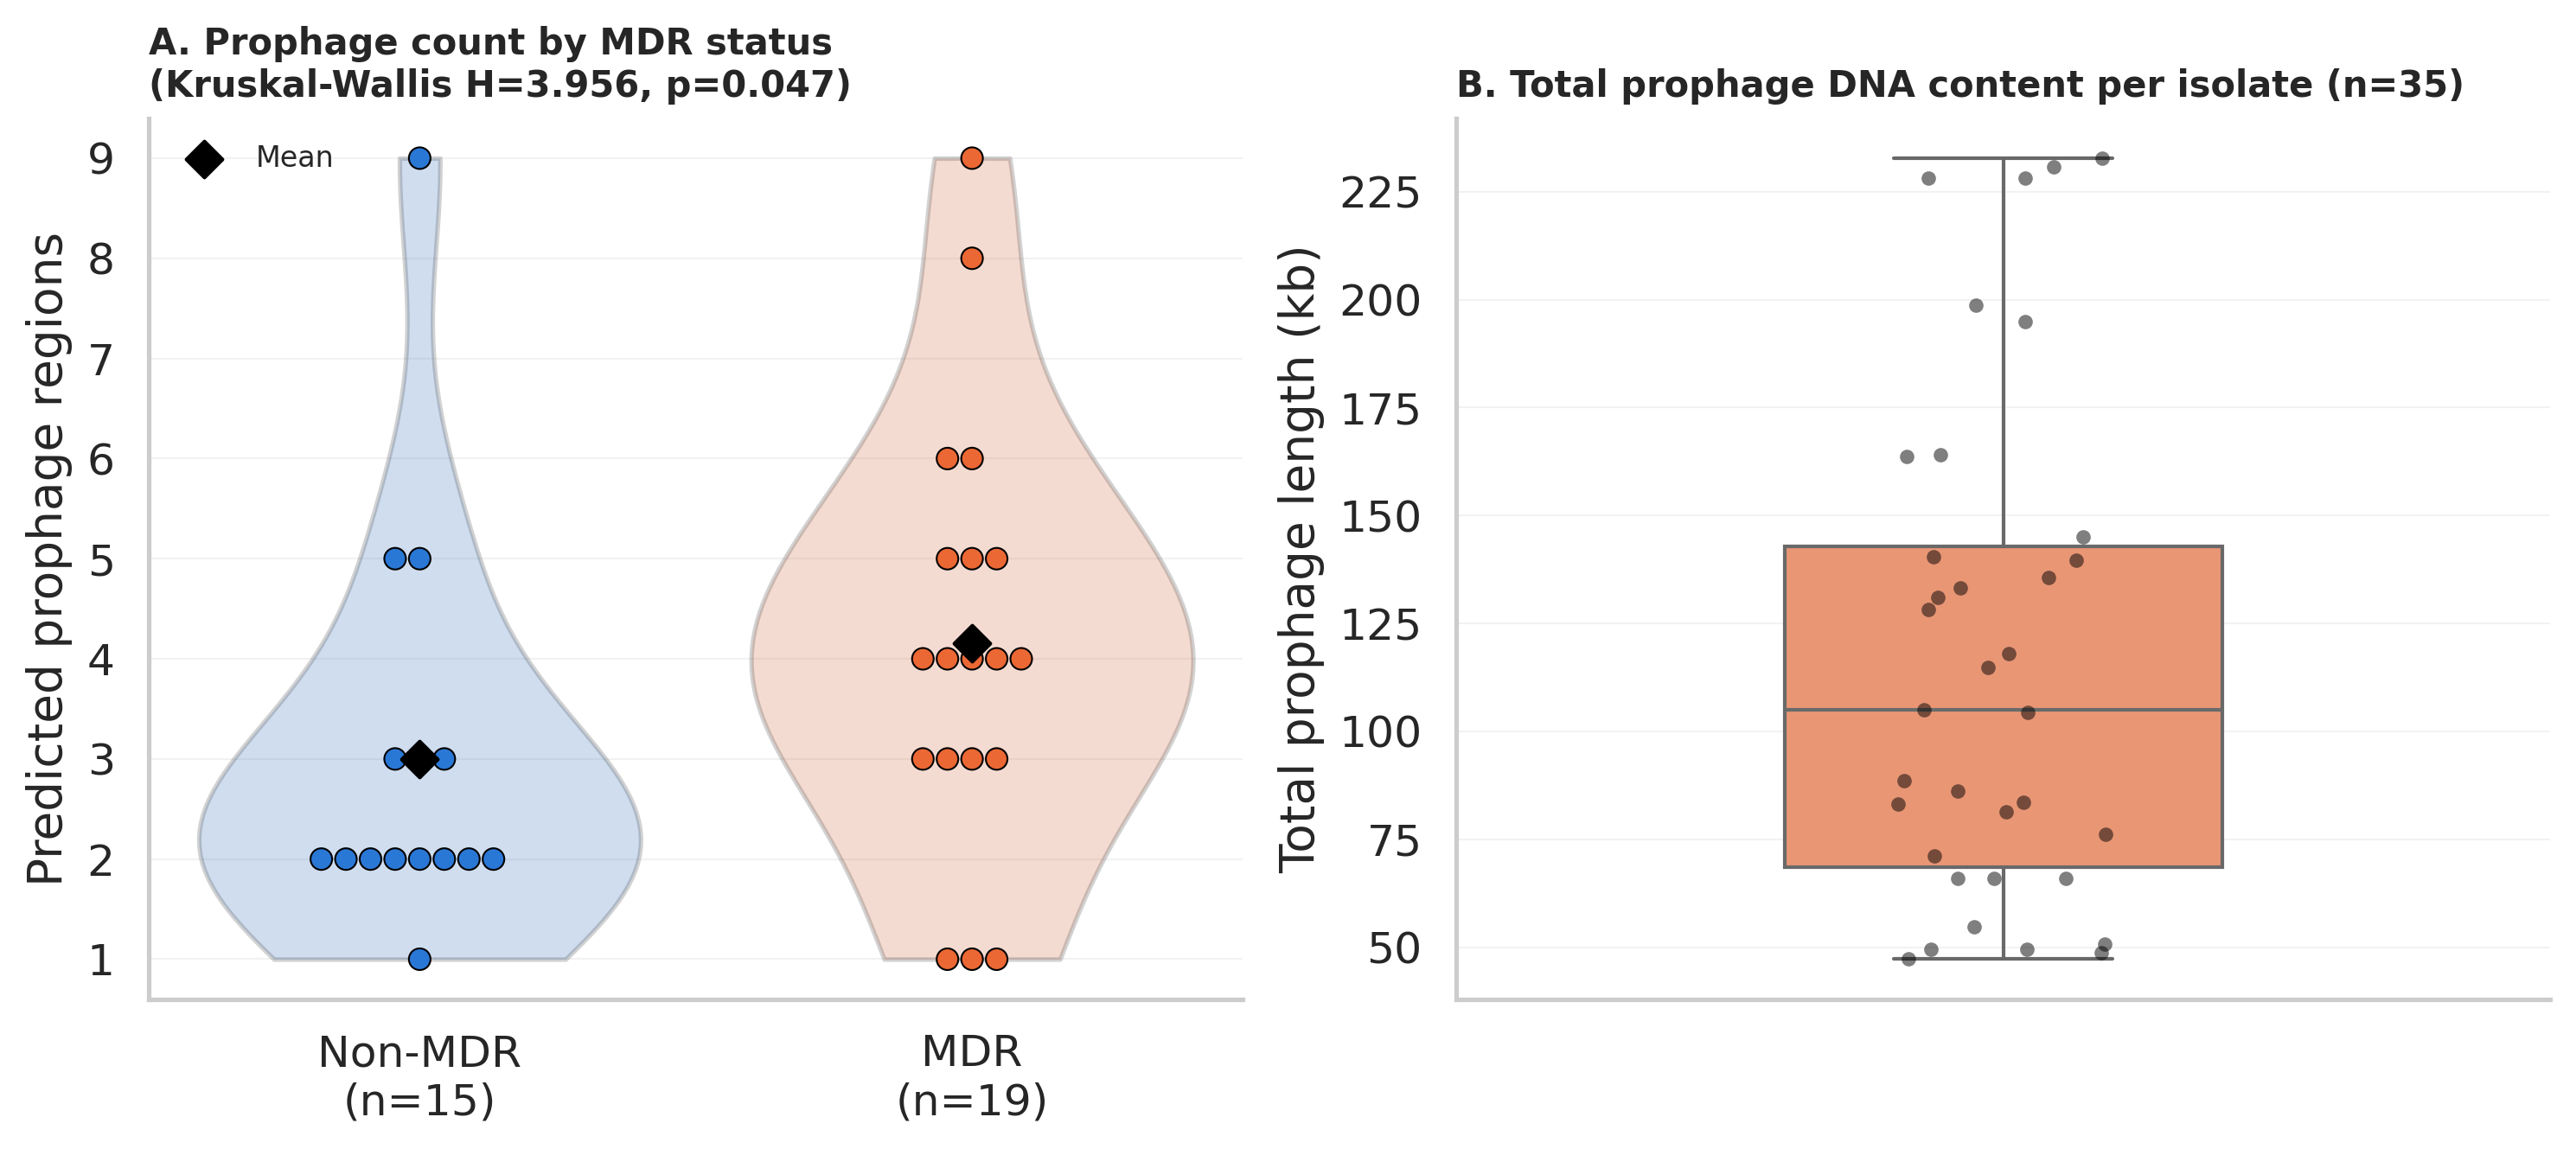

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'figure.dpi': 300,
})

np.random.seed(42)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

order = ['Non-MDR', 'MDR']
palette = {'Non-MDR': '#2a78d6', 'MDR': '#eb6834'}

# Violin shows distribution shape; swarm shows every individual isolate
# with zero overlap (deterministic placement, unlike jittered scatter)
sns.violinplot(data=overlap, x='mdr_status', y='n_proviruses', order=order, hue='mdr_status',
               palette=palette, inner=None, alpha=0.25, cut=0, legend=False, ax=axes[0])
sns.swarmplot(data=overlap, x='mdr_status', y='n_proviruses', order=order, hue='mdr_status',
              palette=palette, size=6, edgecolor='black', linewidth=0.5, legend=False, ax=axes[0])

means = overlap.groupby('mdr_status')['n_proviruses'].mean()
for i, g in enumerate(order):
    axes[0].scatter(i, means[g], marker='D', color='black', s=50, zorder=5, label='Mean' if i == 0 else None)

axes[0].set_xlabel('')
axes[0].set_ylabel('Predicted prophage regions')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels([f'Non-MDR\n(n={sum(overlap.mdr_status=="Non-MDR")})',
                     f'MDR\n(n={sum(overlap.mdr_status=="MDR")})'])
axes[0].set_title('A. Prophage count by MDR status\n(Kruskal-Wallis H=3.956, p=0.047)',
              loc='left', fontweight='bold', fontsize=10)
axes[0].legend(frameon=False, loc='upper left', fontsize=8)

# Panel B: total prophage DNA size distribution (all isolates with prophage data)
sns.boxplot(y=local_prophage['total_provirus_bp'] / 1000, color='#fc8d62', ax=axes[1], width=0.4)
sns.stripplot(y=local_prophage['total_provirus_bp'] / 1000, color='black', alpha=0.5, size=4, ax=axes[1])
axes[1].set_ylabel('Total prophage length (kb)')
axes[1].set_xticks([])
axes[1].set_title(f'B. Total prophage DNA content per isolate (n={len(local_prophage)})',
                   loc='left', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('Figure_prophage_burden_overview.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
files.download("Figure_prophage_burden_overview.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency

df = pd.read_csv('klebsiella_global753.tsv', sep='\t', low_memory=False)
df['base_acc'] = df['strain'].str.replace(r'^(GCA|GCF)_', '', regex=True)
df = df.drop_duplicates(subset='base_acc', keep='first').reset_index(drop=True)

meta = pd.read_csv('global754_final_metadata_with_source_category.csv', sep='\t').rename(columns={'Genome_ID': 'strain'})
merged = df.merge(meta[['strain', 'Database']], on='strain', how='inner')
merged['group'] = merged['Database'].map({
    'This_study': 'Study (NSUCE)',
    'Pathogenwatch': 'Bangladesh-public',
    'NCBI': 'Global (9-country)'
})

RC_COL = 'klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes'

# Total antimicrobial categories tracked - recomputed from this dataset
all_classes = set()
for v in df['AMR_drug_classes'].dropna():
    if v == '-':
        continue
    for c in v.split(';'):
        all_classes.add(c.strip().lower())
TOTAL_CLASSES = len(all_classes)

def classify_mdr(n, total=TOTAL_CLASSES):
    if pd.isna(n) or n <= 2:
        return 'Non-MDR'
    if n >= total - 2:
        return 'XDR'
    return 'MDR'

merged['mdr_status'] = merged[RC_COL].apply(classify_mdr)

# This is the exact crosstab you pasted earlier
ct = pd.crosstab(merged['group'], merged['mdr_status'])
print("Genotypic MDR/XDR status by group:")
print(ct)

chi2, p, dof, exp = chi2_contingency(ct)
print(f"\nChi-square = {chi2:.2f}, p = {p:.4g}")

Genotypic MDR/XDR status by group:
mdr_status          MDR  Non-MDR  XDR
group                                
Bangladesh-public   552       14    3
Global (9-country)   47       36    2
Study (NSUCE)        19       15    0

Chi-square = 192.64, p = 1.433e-40


# MDR XDR

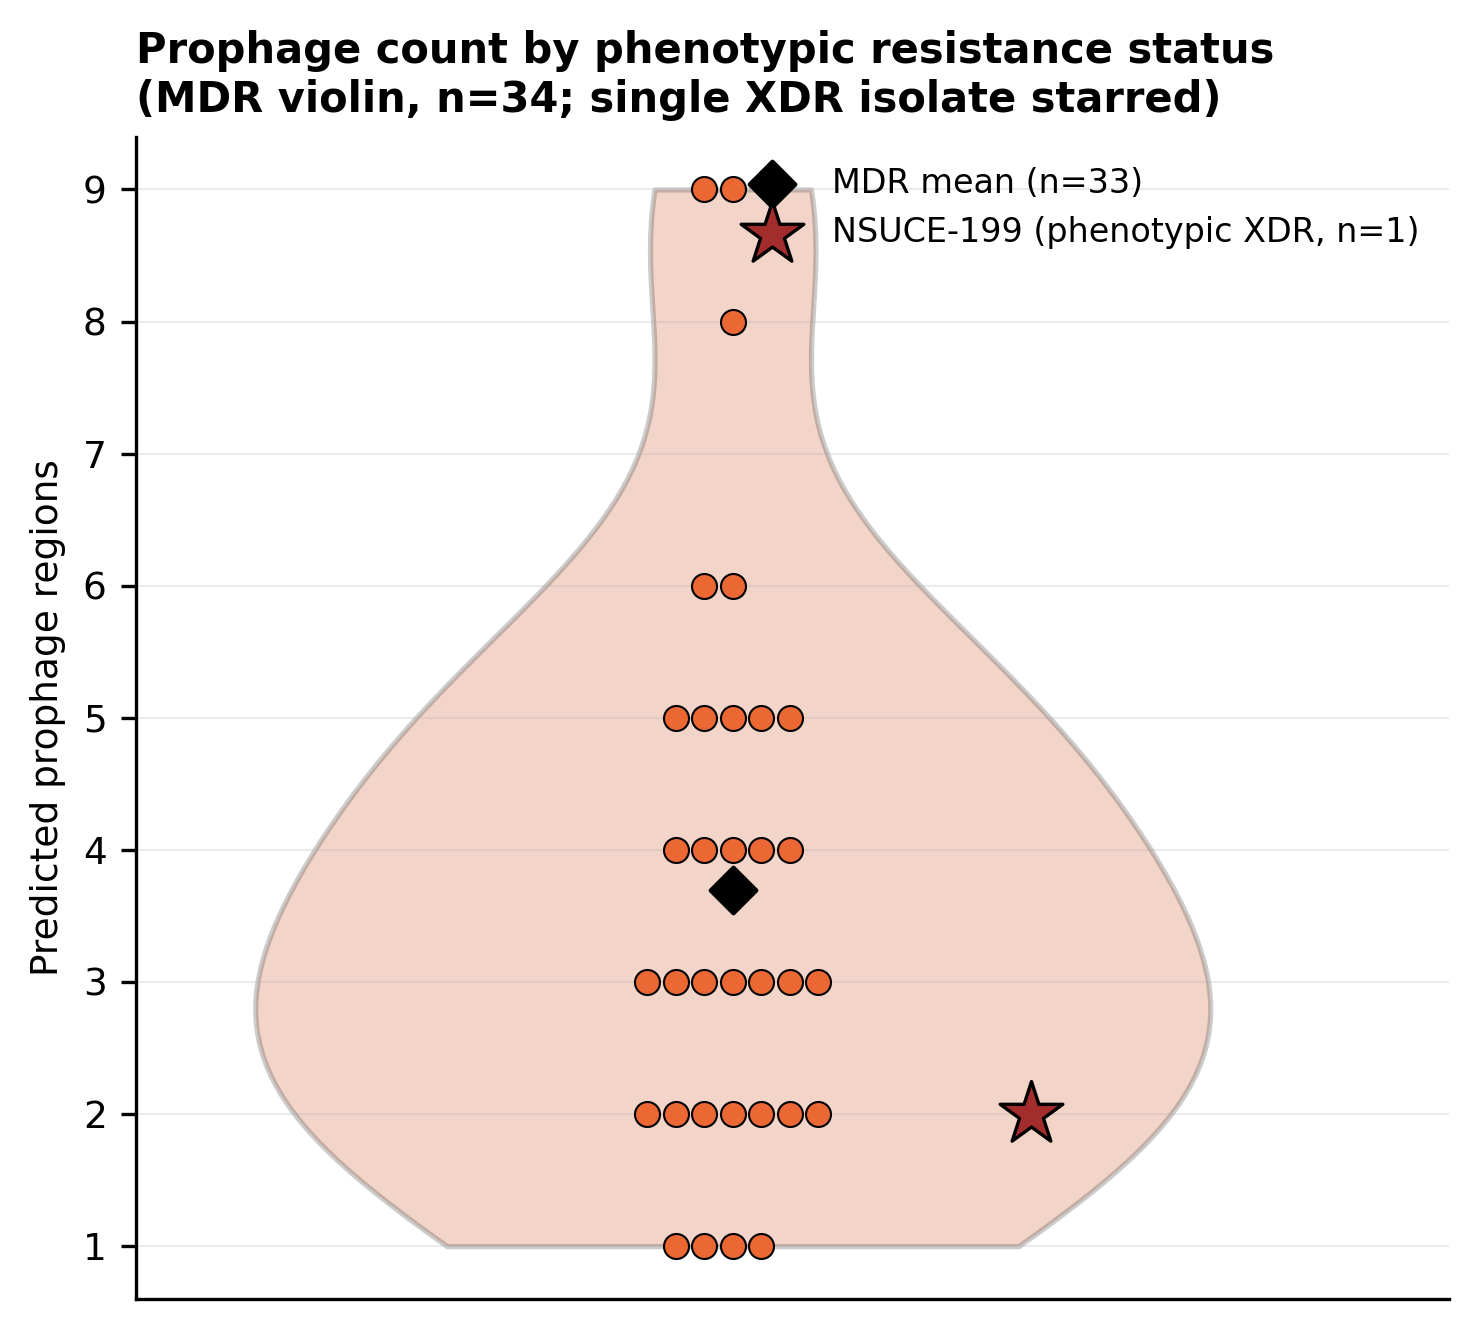

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Re-construct 'overlap' securely within the cell
# 1. Load Kleborate and filter for NSUCE
df_kleb = pd.read_csv('klebsiella_global753.tsv', sep='\t', low_memory=False)
df_kleb['is_NSUCE'] = df_kleb['strain'].astype(str).str.startswith('NSUCE')
nsuce = df_kleb[df_kleb.is_NSUCE].copy()

# 2. Load phenotypic AST data - Fix filename space mismatch
ast = pd.read_excel('Kleb AMR.xlsx').rename(columns={'Strain ID': 'strain'})

# Map antibiotics to categories and classify phenotypic MDR/XDR status
ANTIBIOTIC_CATEGORY = {
    'Amikacin (AK)': 'Aminoglycosides', 'Gentamicin (CN)': 'Aminoglycosides',
    'Meropenem(MEM)': 'Carbapenems', 'Imipenem (IPM)': 'Carbapenems',
    'Cefepime (FEP)': 'Extended-spectrum cephalosporins',
    'Cefixime (CFM)': 'Extended-spectrum cephalosporins',
    'Ceftriaxone (CRO)': 'Extended-spectrum cephalosporins',
    'Cefuroxime': 'Extended-spectrum cephalosporins',
    'Cefotaxime (CTX)': 'Extended-spectrum cephalosporins',
    'Ceftazimide (CAZ)': 'Extended-spectrum cephalosporins',
    'Cefoxitin (FOX)': 'Cephamycins',
    'Ciprofloxacin (CIP)': 'Fluoroquinolones', 'Levofloxacin': 'Fluoroquinolones',
    'Nalidixic Acid (NA)': 'Fluoroquinolones',
    'Trimethoprim (W)': 'Folate pathway inhibitors', 'Co-trimoxazole': 'Folate pathway inhibitors',
    'Tigecycline (TGC)': 'Glycylcyclines',
    'Aztreonam (ATM)': 'Monobactams',
    'Ampicilin': 'Penicillins', 'Amoxycillin': 'Penicillins',
    'Amoxyclave': 'Penicillins + BLI combinations',
    'Piperacillin/Tazobactum (TZP)': 'Antipseudomonal penicillins + BLI',
    'Tetracyclin (TE)': 'Tetracyclines', 'Doxycycline (DO)': 'Tetracyclines',
    'Colistin (CT)': 'Polymyxins', 'Polymixin B (PB)': 'Polymyxins',
    'Fosfomycin (FOS)': 'Fosfomycin',
    'Nitrofurantoin F': 'Nitrofurans',
    'Azithromycin (AZM)': 'Macrolides',
}
abx_cols = [c for c in ANTIBIOTIC_CATEGORY.keys() if c in ast.columns]
long = ast.melt(id_vars='strain', value_vars=abx_cols, var_name='antibiotic', value_name='result')
long['category'] = long['antibiotic'].map(ANTIBIOTIC_CATEGORY)
long['non_susceptible'] = long['result'].isin(['R', 'I'])
cat_ns = long.groupby(['strain', 'category'])['non_susceptible'].any().reset_index()
n_cat_ns = cat_ns.groupby('strain')['non_susceptible'].sum().rename('n_categories_nonsusceptible').reset_index()

def classify_pheno_mdr(n):
    return 'XDR' if n >= 14 else 'MDR' # 16 categories total tested

n_cat_ns['pheno_mdr_status'] = n_cat_ns['n_categories_nonsusceptible'].apply(classify_pheno_mdr)

# 3. Load prophage data
proph = pd.read_csv('prophage_isolate_summary.tsv', sep='\t').rename(columns={'isolate': 'strain'})

# 4. Merge all together to recreate 'overlap'
overlap = nsuce.merge(n_cat_ns, on='strain', how='inner')
overlap = overlap.merge(proph, on='strain', how='inner')

# Configure Plot settings
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'figure.dpi': 300,
})

fig, ax = plt.subplots(figsize=(5, 4.5))

mdr_only = overlap[overlap.pheno_mdr_status == 'MDR']
xdr_only = overlap[overlap.pheno_mdr_status == 'XDR']

# Violin + swarm for the MDR group
sns.violinplot(data=mdr_only, y='n_proviruses', color='#eb6834', inner=None, alpha=0.3, cut=0, ax=ax)
sns.swarmplot(data=mdr_only, y='n_proviruses', color='#eb6834', size=6, edgecolor='black', linewidth=0.5, ax=ax)

mean_mdr = mdr_only['n_proviruses'].mean()
ax.scatter(0, mean_mdr, marker='D', color='black', s=60, zorder=5, label=f'MDR mean (n={len(mdr_only)})')

# Highlight phenotypic XDR isolate
for _, row in xdr_only.iterrows():
    ax.scatter(0.25, row['n_proviruses'], marker='*', color='#a32d2d', s=250,
               edgecolor='black', linewidth=0.8, zorder=6,
               label=f"{row['strain']} (phenotypic XDR, n=1)")

ax.set_xlim(-0.5, 0.6)
ax.set_xticks([])
ax.set_ylabel('Predicted prophage regions')
ax.set_title('Prophage count by phenotypic resistance status\n(MDR violin, n=34; single XDR isolate starred)',
              loc='left', fontweight='bold', fontsize=10)
ax.legend(frameon=False, loc='upper right', fontsize=8)

plt.tight_layout()
plt.savefig('Figure_prophage_phenotypic_MDR_XDR.png', dpi=300, bbox_inches='tight')
plt.show()

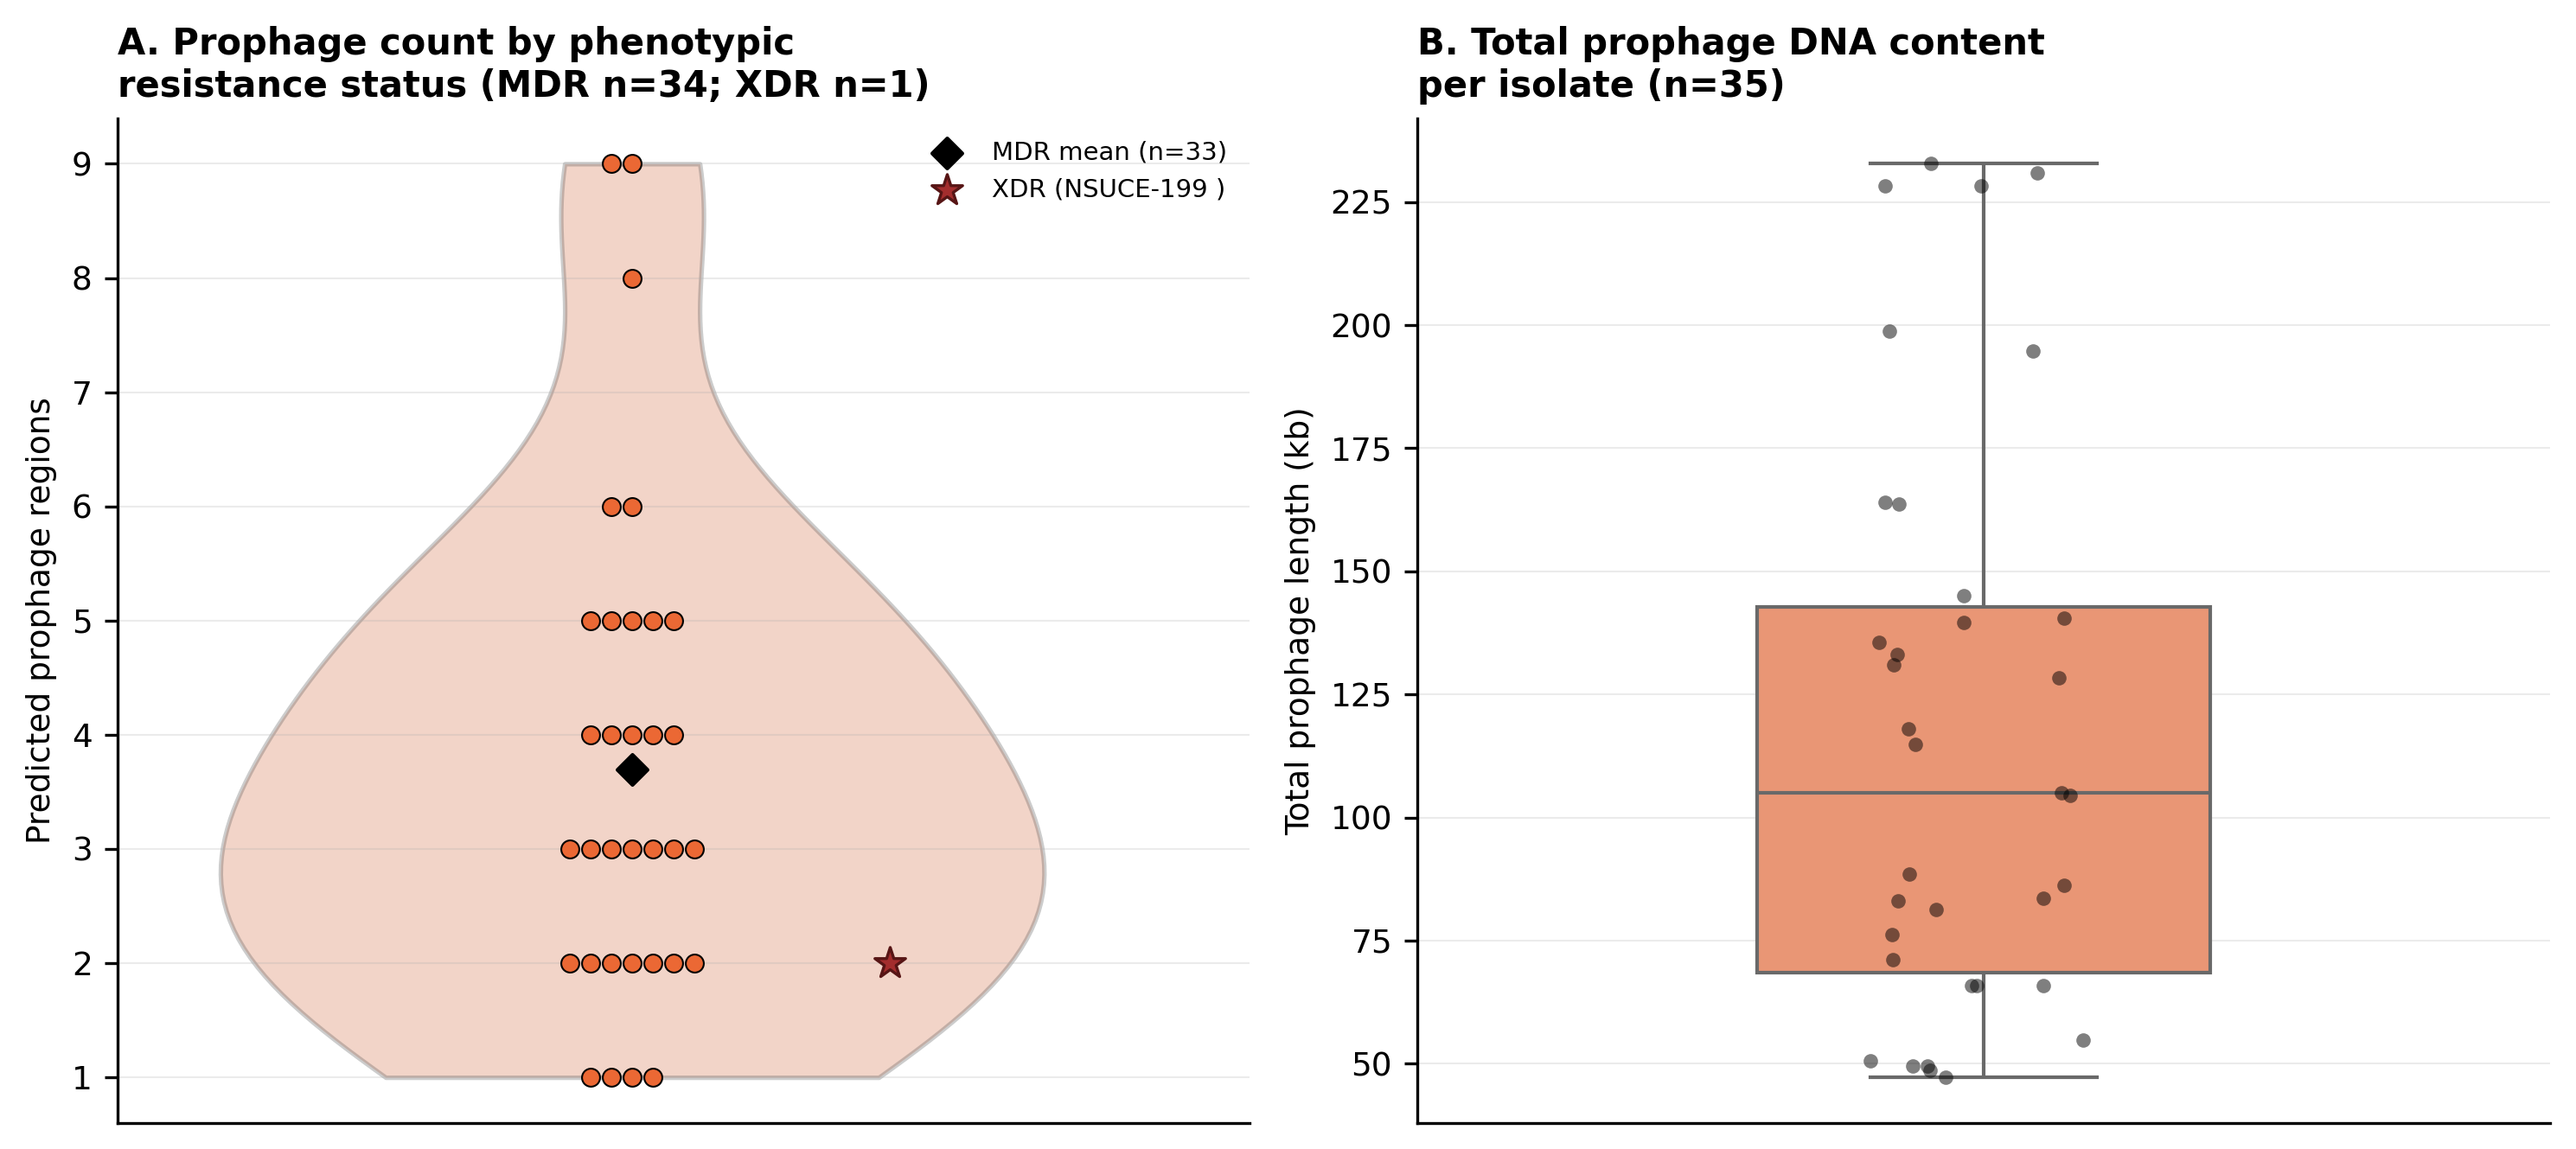

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fix: Load the prophage summary data and define local_prophage securely within this cell
prophage_summary = pd.read_csv('prophage_isolate_summary.tsv', sep='\t')
local_prophage = prophage_summary[prophage_summary['isolate'].str.startswith('NSUCE-')].copy()

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'figure.dpi': 300,
})

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Panel A: prophage count by phenotypic resistance status (MDR violin + starred XDR)
mdr_only = overlap[overlap.pheno_mdr_status == 'MDR']
xdr_only = overlap[overlap.pheno_mdr_status == 'XDR']

sns.violinplot(data=mdr_only, y='n_proviruses', color='#eb6834', inner=None, alpha=0.3, cut=0, ax=axes[0])
sns.swarmplot(data=mdr_only, y='n_proviruses', color='#eb6834', size=5, edgecolor='black',
              linewidth=0.5, ax=axes[0])

mean_mdr = mdr_only['n_proviruses'].mean()
axes[0].scatter(0, mean_mdr, marker='D', color='black', s=35, zorder=5, label=f'MDR mean (n={len(mdr_only)})')

# Single phenotypic XDR isolate marked distinctly
for _, row in xdr_only.iterrows():
    axes[0].scatter(0.25, row['n_proviruses'], marker='*', color='#a32d2d', s=80,
                     edgecolor='#571515', linewidth=0.8, zorder=6,
                     label=f"XDR ({row['strain']} )")

axes[0].set_xlim(-0.5, 0.6)
axes[0].set_xticks([])
axes[0].set_ylabel('Predicted prophage regions')
axes[0].set_title('A. Prophage count by phenotypic\nresistance status (MDR n=34; XDR n=1)',
                   loc='left', fontweight='bold', fontsize=10)
axes[0].legend(frameon=False, loc='upper right', fontsize=7)

# Panel B: total prophage DNA size distribution
sns.boxplot(y=local_prophage['total_provirus_bp'] / 1000, color='#fc8d62', ax=axes[1], width=0.4)
sns.stripplot(y=local_prophage['total_provirus_bp'] / 1000, color='black', alpha=0.5, size=4, ax=axes[1])
axes[1].set_ylabel('Total prophage length (kb)')
axes[1].set_xticks([])
axes[1].set_title(f'B. Total prophage DNA content\nper isolate (n={len(local_prophage)})',
                   loc='left', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('Figure_prophage_burden_overview_phenotypic.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
print(mean_mdr)

3.696969696969697


In [ ]:
files.download("Figure_prophage_burden_overview_phenotypic.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Prophage burden- MDR vs XDR

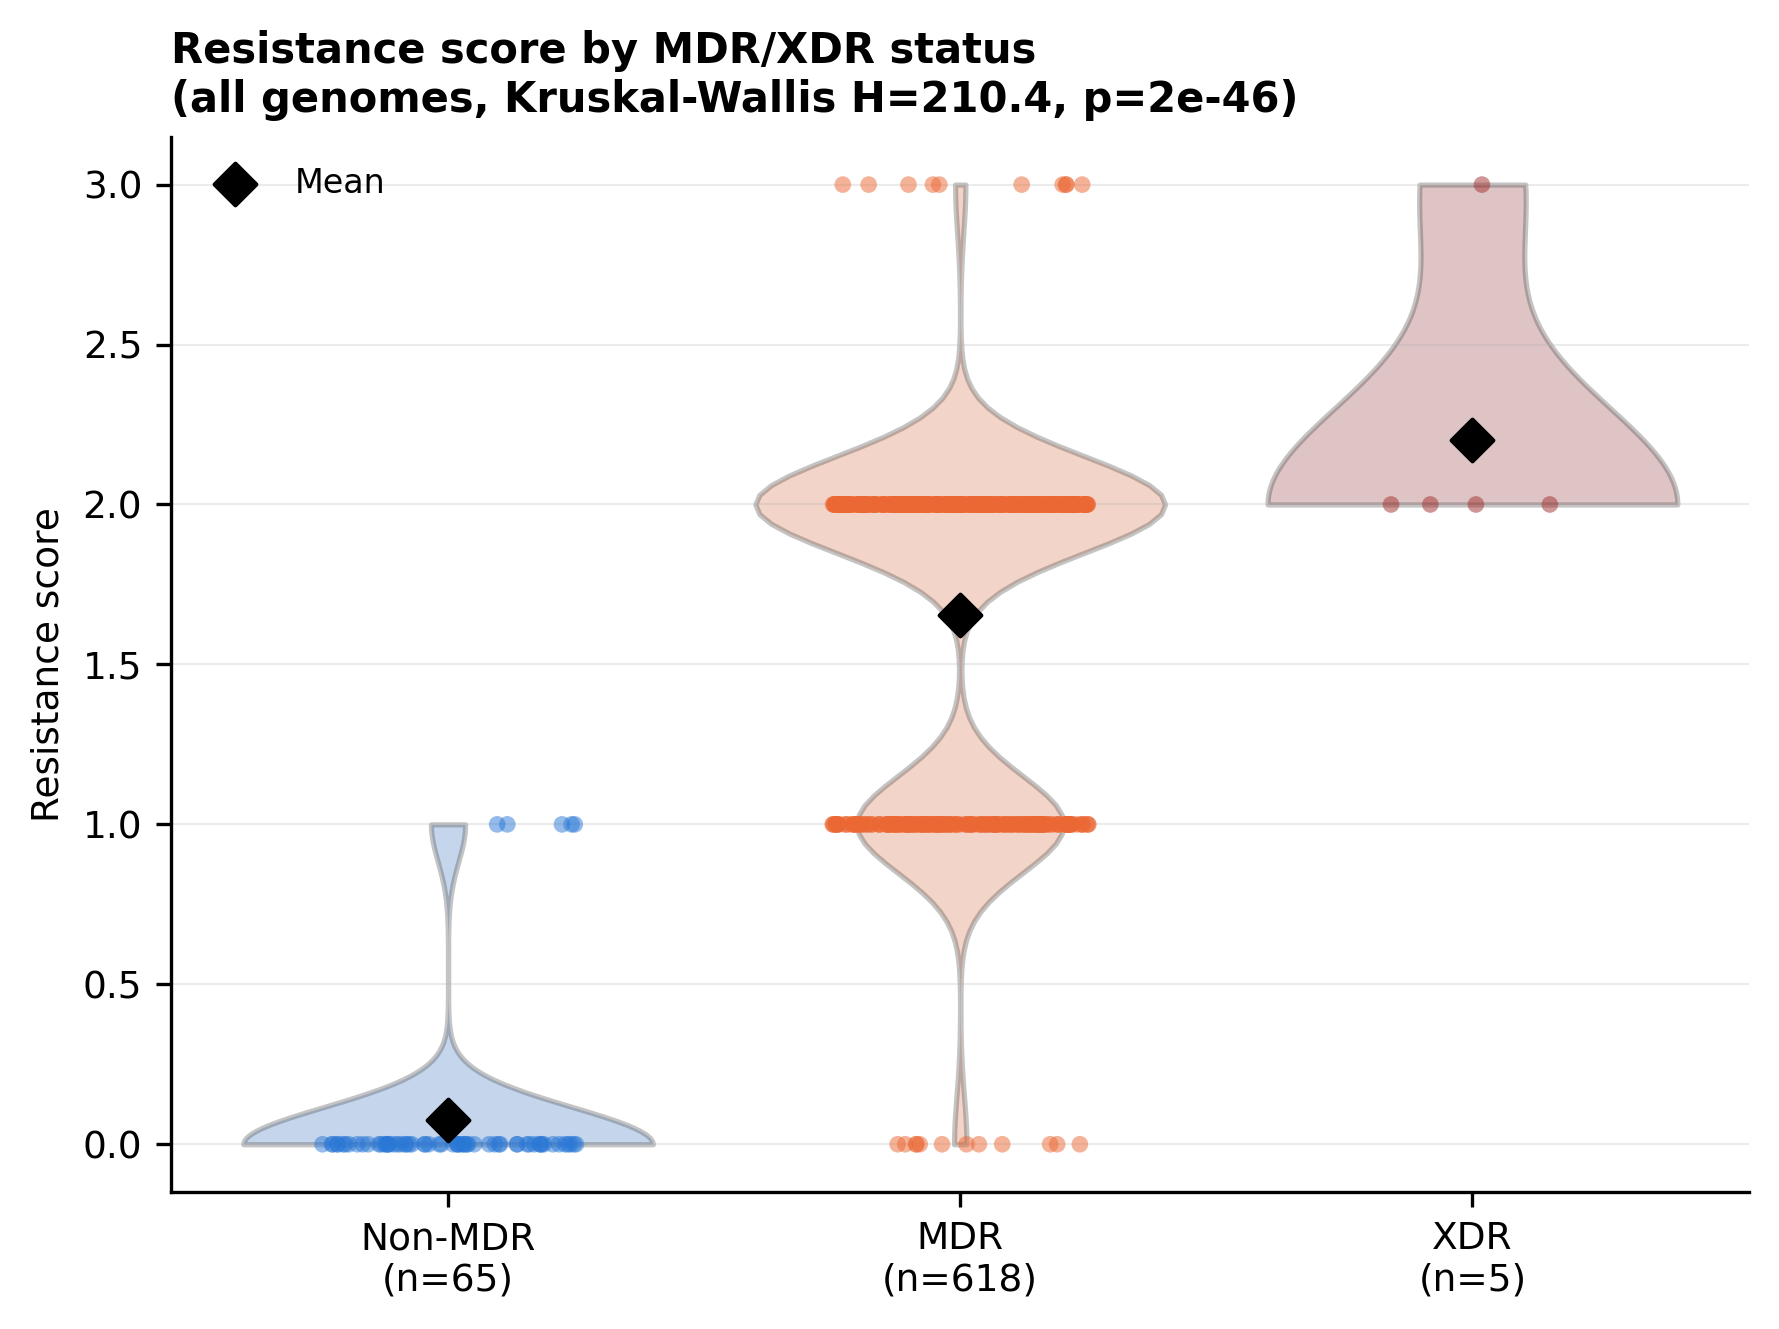

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'figure.dpi': 300,
})

# Uses `merged` (the full 688-genome, 3-way-grouped dataframe from Cells 3-7),
# NOT `overlap` (the 34-isolate prophage dataframe) - this plot has no
# prophage data at all, it uses resistance score as the continuous measure
order = ['Non-MDR', 'MDR', 'XDR']
palette = {'Non-MDR': '#2a78d6', 'MDR': '#eb6834', 'XDR': '#a32d2d'}

groups = [merged[merged.mdr_status == g][RES_SCORE_COL] for g in order]
h_stat, p_kw = kruskal(*groups)

fig, ax = plt.subplots(figsize=(6, 4.5))

sns.violinplot(data=merged, x='mdr_status', y=RES_SCORE_COL, order=order, hue='mdr_status',
               palette=palette, inner=None, alpha=0.3, cut=0, legend=False, ax=ax)
sns.stripplot(data=merged, x='mdr_status', y=RES_SCORE_COL, order=order, hue='mdr_status',
              palette=palette, size=4, alpha=0.5, jitter=0.25, legend=False, ax=ax)

means = merged.groupby('mdr_status')[RES_SCORE_COL].mean()
for i, g in enumerate(order):
    ax.scatter(i, means[g], marker='D', color='black', s=50, zorder=5, label='Mean' if i == 0 else None)

ax.set_xlabel('')
ax.set_ylabel('Resistance score')
ax.set_xticks([0, 1, 2])
ax.set_xticklabels([f'{g}\n(n={sum(merged.mdr_status==g)})' for g in order])
ax.set_title(f'Resistance score by MDR/XDR status\n(all genomes, Kruskal-Wallis H={h_stat:.1f}, p={p_kw:.2g})',
             loc='left', fontweight='bold', fontsize=10)
ax.legend(frameon=False, loc='upper left', fontsize=8)

plt.tight_layout()
plt.savefig('Figure_resistance_score_by_MDRXDR_allgroups.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# %% Cell 10 - Full isolate-level table (useful for supplementary materials)
print("\nFull isolate-level table, sorted by prophage burden:")
print(overlap[['strain', 'n_proviruses', 'mdr_status', RC_COL]]
      .sort_values('n_proviruses', ascending=False).to_string(index=False))

# %% Cell 11 - Export everything
with pd.ExcelWriter('Corrected_3way_and_prophage_analysis.xlsx') as writer:
    merged[['strain', 'group', 'mdr_status', RC_COL, RES_SCORE_COL, VIR_COL,
            'has_carb', 'has_esbl']].to_excel(writer, sheet_name='3way_isolate_level', index=False)
    overlap[['strain', 'n_proviruses', 'mdr_status', RC_COL, GENE_COUNT_COL, RES_SCORE_COL]].to_excel(
        writer, sheet_name='Prophage_vs_MDR', index=False)

from google.colab import files as colab_files
colab_files.download('Corrected_3way_and_prophage_analysis.xlsx')


Full isolate-level table, sorted by prophage burden:


NameError: name 'overlap' is not defined

In [ ]:
 # %% Cell 13 - (Optional, pending your prophage data) Prophage burden vs MDR/XDR
# Requires a per-isolate prophage count file (from geNomad), e.g.
# prophage_df with columns: strain, prophage_count
#
prophage_df = pd.read_csv(/content/master_prophage_summary.tsv')
prophage_df = prophage_df.rename(columns={'n_proviruses': 'prophage_count', 'isolate': 'strain'})
merged = df.merge(prophage_df, on='strain', how='inner')
groups = [merged[merged.mdr_status == g]['prophage_count'] for g in ['Non-MDR', 'MDR', 'XDR']]
groups = [g for g in groups if len(g) > 0]
h_stat, p_kw = kruskal(*groups)
print(f"Kruskal-Wallis: H = {h_stat:.2f}, p = {p_kw:.4g}")
print(merged.groupby('mdr_status')['prophage_count'].describe()[['count', 'mean', '50%', 'std']])

merged['high_prophage'] = merged['prophage_count'] >= 5
ct_prophage = pd.crosstab(merged['is_mdr_or_xdr'], merged['high_prophage'])
odds_p, p_fisher = fisher_exact(ct_prophage)
print(f"High prophage burden (>=5) vs MDR/XDR: OR = {odds_p:.2f}, p = {p_fisher:.4g}")

SyntaxError: unterminated string literal (detected at line 5) (1675611772.py, line 5)

## 1. Burden by isolation source

Isolation sources present:
Isolation_source
Stool                15
Blood                11
Urine                 5
Tracheal Aspirate     4
Name: count, dtype: int64


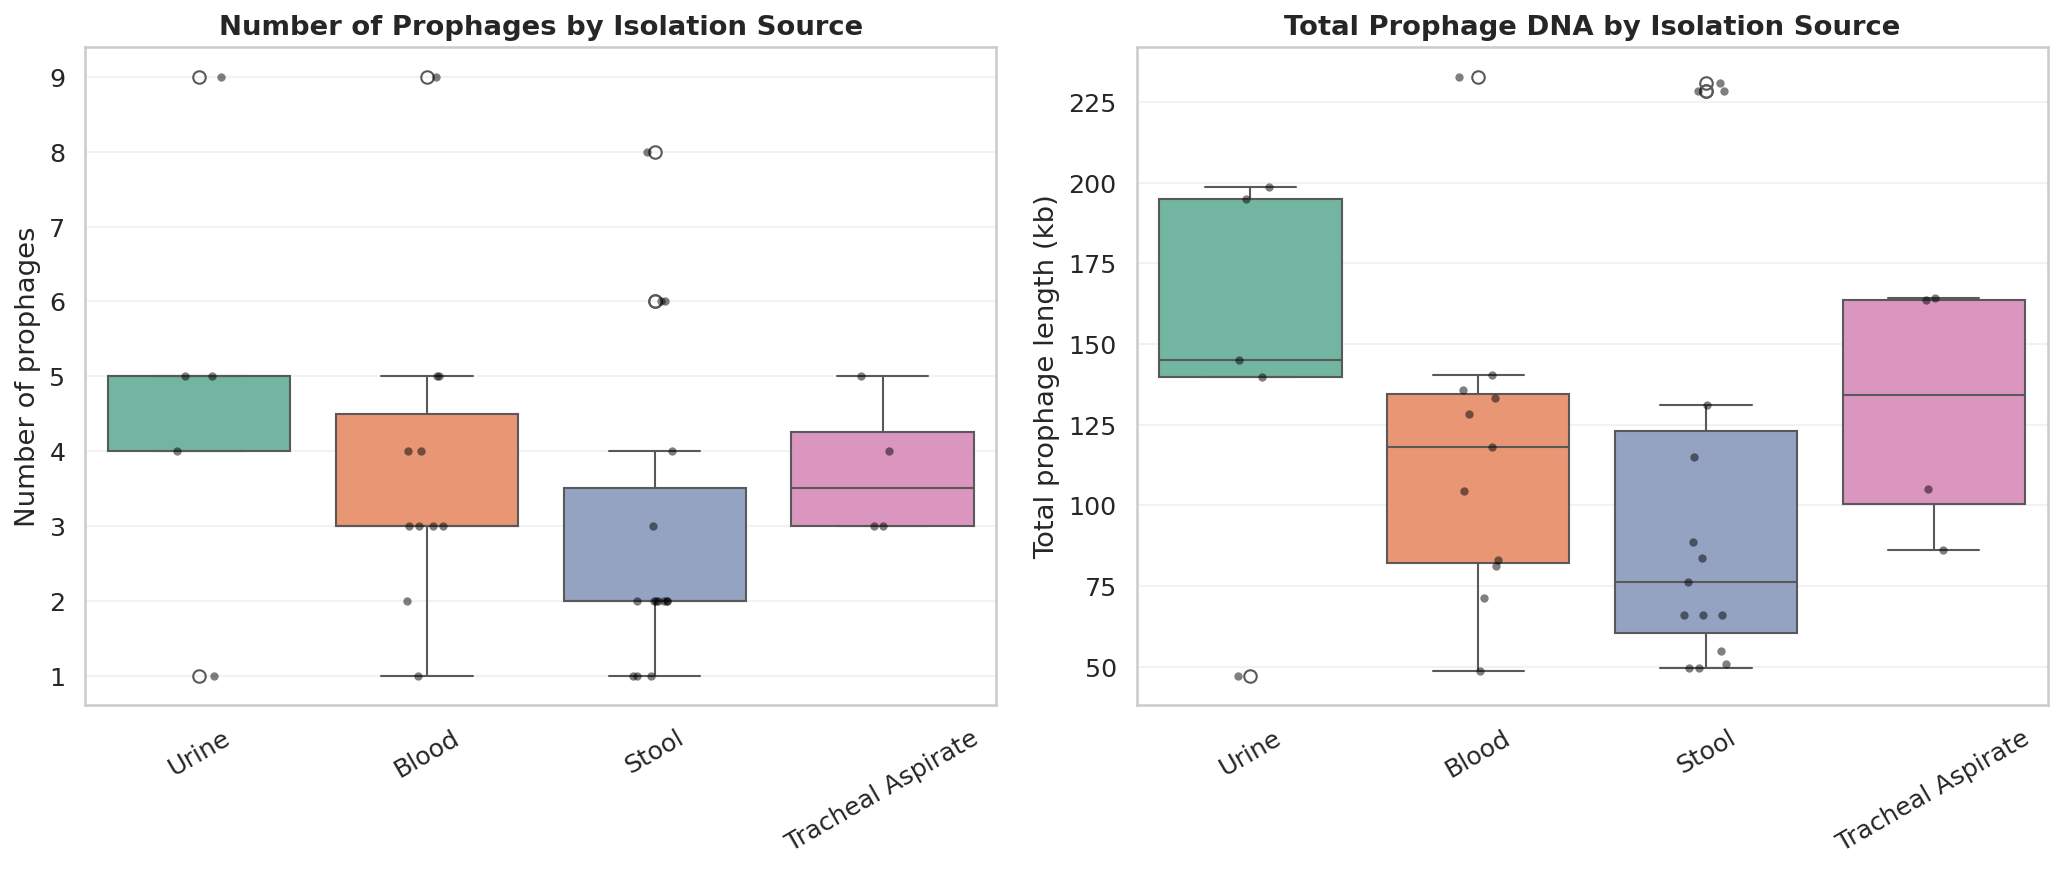


Kruskal-Wallis test (prophage count by source): H = 4.348, p = 0.2262


In [ ]:
# ============================================================
# PROPHAGE ANALYSES
# 3. Taxonomy summary
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, kruskal
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 600

# ---------- Load data ----------
prophage_summary = pd.read_csv("prophage_isolate_summary.tsv", sep="\t")
master_prophage  = pd.read_csv("master_prophage_summary.tsv", sep="\t")
source_meta      = pd.read_csv("global754_final_metadata_with_source_category.csv", sep="\t")

# Keep only local isolates
local_prophage = prophage_summary[prophage_summary['isolate'].str.startswith('NSUCE-')].copy()

# Merge isolation source
source_local = source_meta[source_meta['Genome_ID'].str.startswith('NSUCE-')][
    ['Genome_ID', 'Isolation_source', 'Source_category']
].rename(columns={'Genome_ID': 'isolate'})

local_prophage = local_prophage.merge(source_local, on='isolate', how='left')

# Clean isolation source names
local_prophage['Isolation_source'] = local_prophage['Isolation_source'].fillna('Unknown')
local_prophage['Isolation_source'] = local_prophage['Isolation_source'].str.title()

print("Isolation sources present:")
print(local_prophage['Isolation_source'].value_counts())

# ============================================================
# 1. PROPHAGE BURDEN BY ISOLATION SOURCE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Number of prophages
sns.boxplot(data=local_prophage, x='Isolation_source', y='n_proviruses',
            ax=axes[0], palette='Set2')
sns.stripplot(data=local_prophage, x='Isolation_source', y='n_proviruses',
              ax=axes[0], color='black', alpha=0.5, size=4)
axes[0].set_title("Number of Prophages by Isolation Source", fontweight='bold')
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of prophages")
axes[0].tick_params(axis='x', rotation=30)

# Total prophage DNA
sns.boxplot(data=local_prophage, x='Isolation_source', y=local_prophage['total_provirus_bp']/1000,
            ax=axes[1], palette='Set2')
sns.stripplot(data=local_prophage, x='Isolation_source', y=local_prophage['total_provirus_bp']/1000,
              ax=axes[1], color='black', alpha=0.5, size=4)
axes[1].set_title("Total Prophage DNA by Isolation Source", fontweight='bold')
axes[1].set_xlabel("")
axes[1].set_ylabel("Total prophage length (kb)")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig("Fig_Prophage_by_Source.png", dpi=600, bbox_inches='tight')
plt.show()

# Statistical test (Kruskal-Wallis)
groups = [group['n_proviruses'].values for name, group in local_prophage.groupby('Isolation_source')]
stat, p = kruskal(*groups)
print(f"\nKruskal-Wallis test (prophage count by source): H = {stat:.3f}, p = {p:.4f}")




# Correlation with resistance and virulence scores

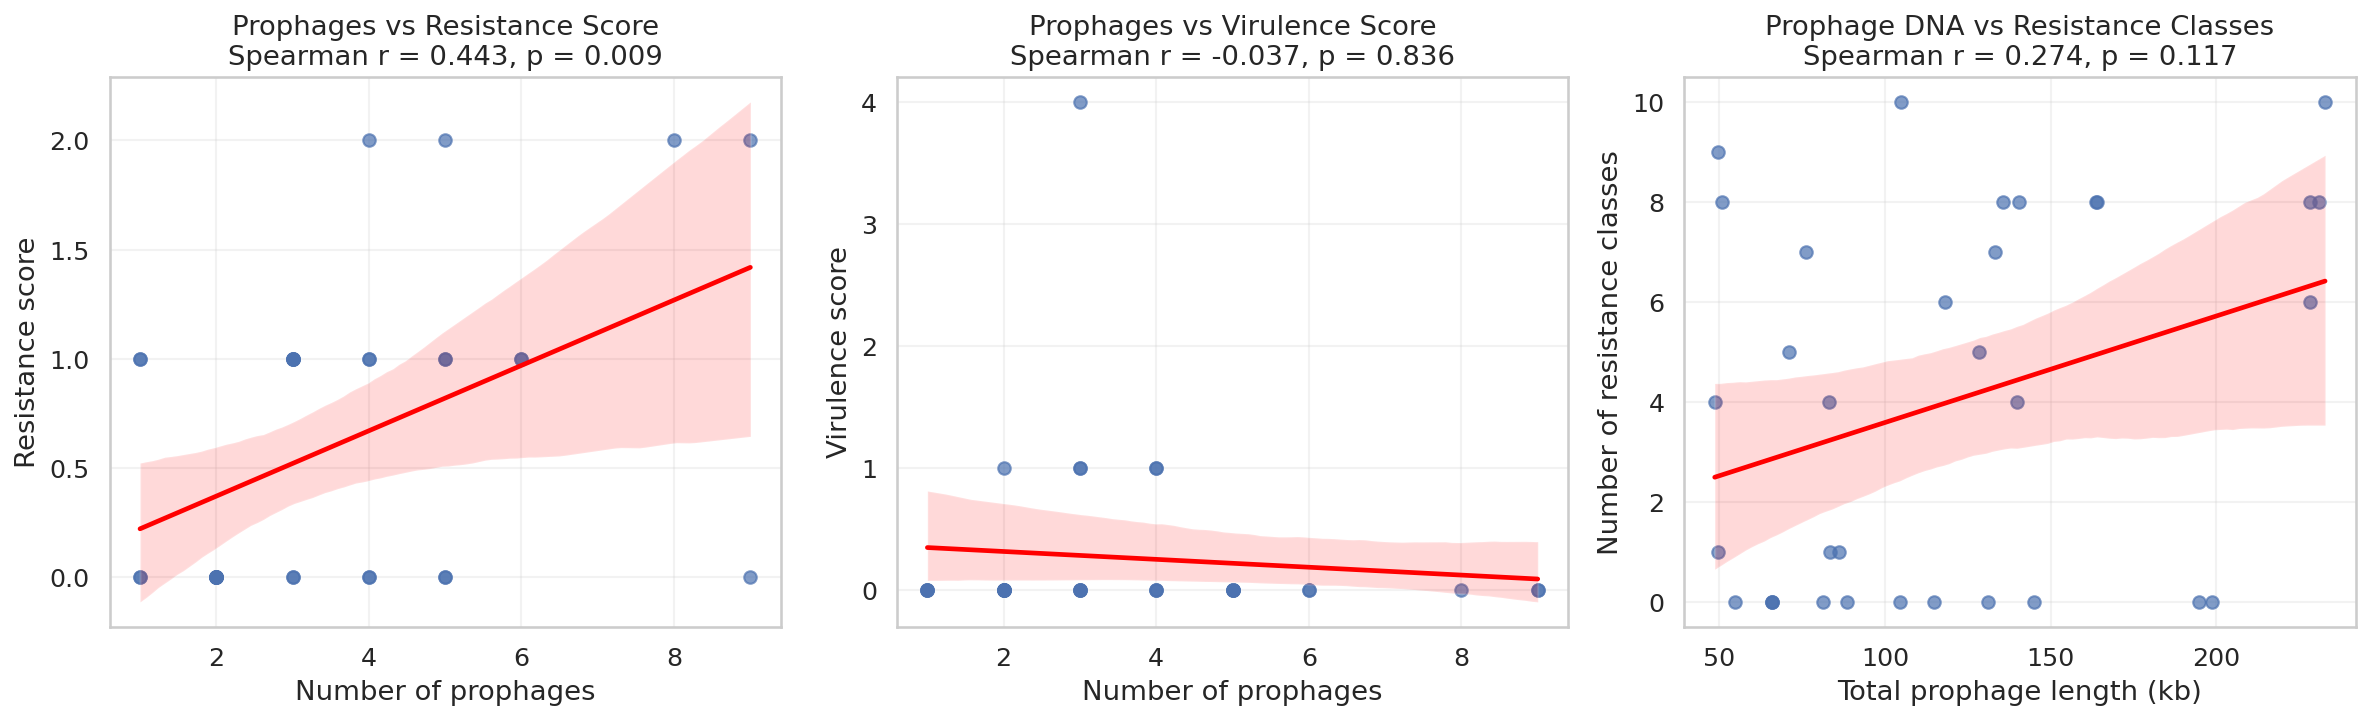

In [ ]:
# ============================================================
# 2. CORRELATION WITH RESISTANCE & VIRULENCE SCORES
# ============================================================

# Merge Kleborate scores (assuming 'df' contains the Kleborate results)
kleb_scores = df[['strain',
                    'klebsiella_pneumo_complex__virulence_score__virulence_score',
                    'klebsiella_pneumo_complex__resistance_score__resistance_score',
                    'klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes']].copy()

kleb_scores = kleb_scores.rename(columns={
    'strain': 'isolate',
    'klebsiella_pneumo_complex__virulence_score__virulence_score': 'virulence_score',
    'klebsiella_pneumo_complex__resistance_score__resistance_score': 'resistance_score',
    'klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes': 'num_res_classes'
})

# Convert to numeric
for col in ['virulence_score', 'resistance_score', 'num_res_classes']:
    kleb_scores[col] = pd.to_numeric(kleb_scores[col], errors='coerce')

merged = local_prophage.merge(kleb_scores, on='isolate', how='left')

# Correlation plots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Prophage count vs Resistance score
sns.regplot(data=merged, x='n_proviruses', y='resistance_score',
            ax=axes[0], scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
r, p = spearmanr(merged['n_proviruses'], merged['resistance_score'], nan_policy='omit')
axes[0].set_title(f"Prophages vs Resistance Score\nSpearman r = {r:.3f}, p = {p:.3f}")
axes[0].set_xlabel("Number of prophages")
axes[0].set_ylabel("Resistance score")

# Prophage count vs Virulence score
sns.regplot(data=merged, x='n_proviruses', y='virulence_score',
            ax=axes[1], scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
r, p = spearmanr(merged['n_proviruses'], merged['virulence_score'], nan_policy='omit')
axes[1].set_title(f"Prophages vs Virulence Score\nSpearman r = {r:.3f}, p = {p:.3f}")
axes[1].set_xlabel("Number of prophages")
axes[1].set_ylabel("Virulence score")

# Total prophage DNA vs Resistance classes
sns.regplot(data=merged, x=merged['total_provirus_bp']/1000, y='num_res_classes',
            ax=axes[2], scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
r, p = spearmanr(merged['total_provirus_bp'], merged['num_res_classes'], nan_policy='omit')
axes[2].set_title(f"Prophage DNA vs Resistance Classes\nSpearman r = {r:.3f}, p = {p:.3f}")
axes[2].set_xlabel("Total prophage length (kb)")
axes[2].set_ylabel("Number of resistance classes")

plt.tight_layout()
plt.savefig("Fig_Prophage_vs_Kleborate.png", dpi=600, bbox_inches='tight')
plt.show()




=== Prophage taxonomy summary ===
taxonomy_simple
Viruses;Duplodnaviria;Heunggongvirae;Uroviricota;Caudoviricetes;;                                 176
Viruses;Varidnaviria;Bamfordvirae;Nucleocytoviricota;Megaviricetes;Algavirales;Phycodnaviridae      1
Unclassified                                                                                        1
Name: count, dtype: int64


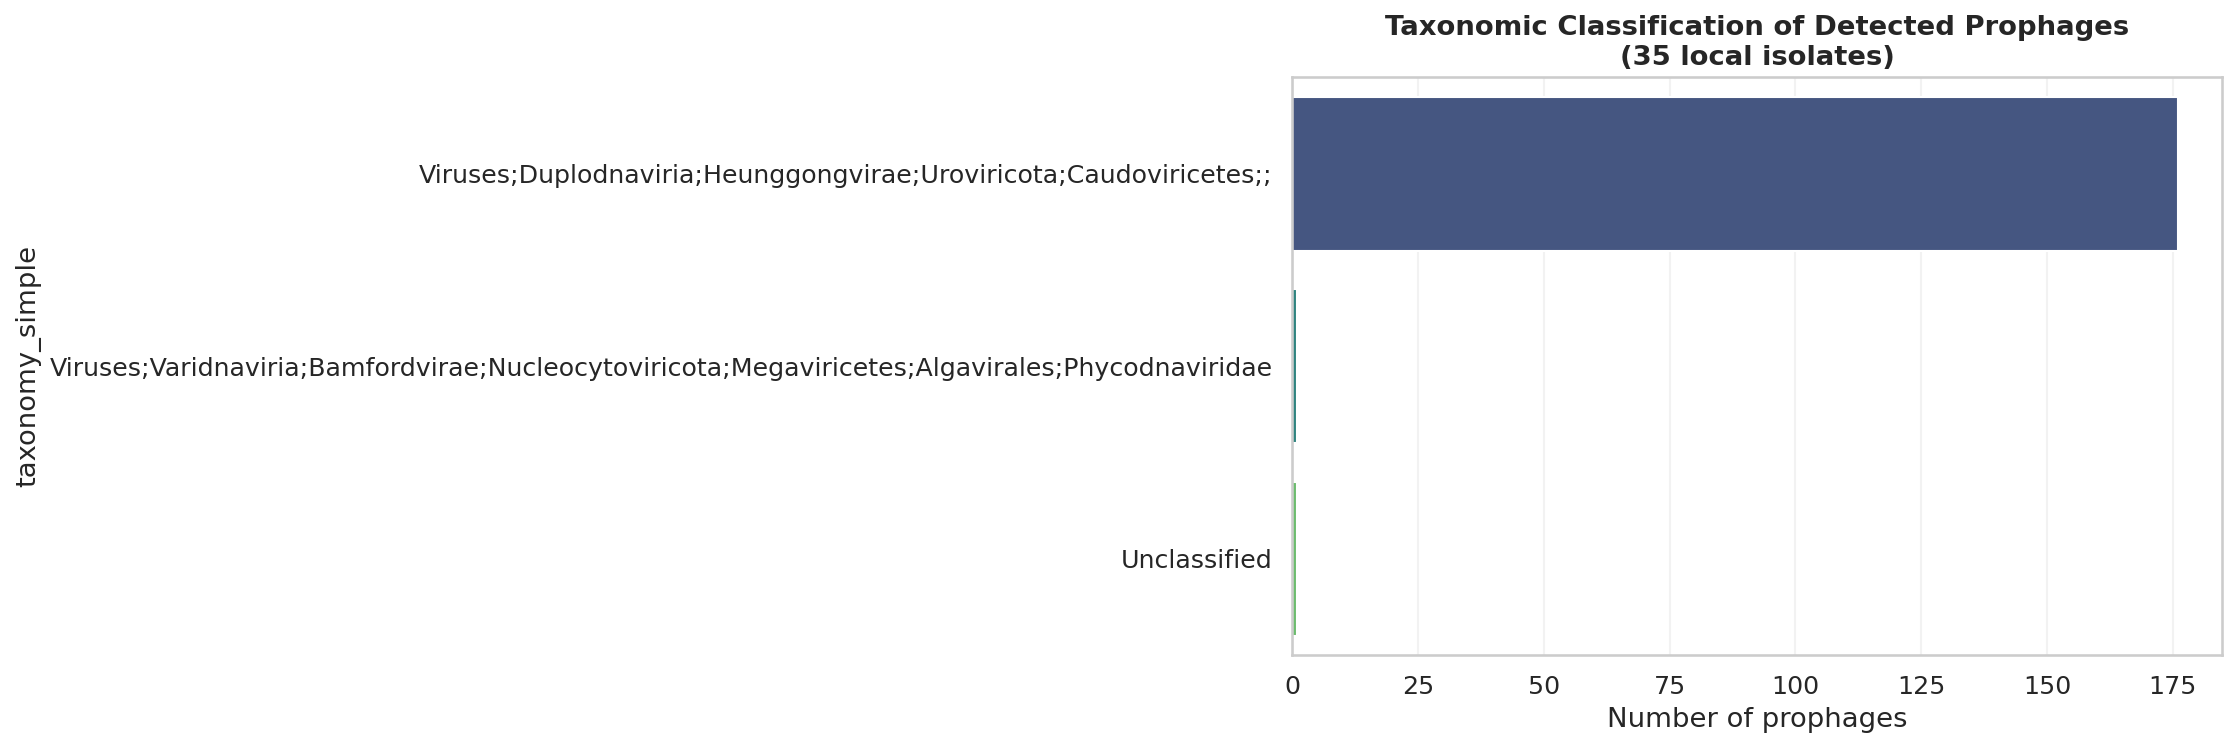


Total prophages analysed: 178
Proportion classified as Caudoviricetes: 98.9%


In [ ]:
# ====== 3. TAXONOMY SUMMARY OF PROPHAGES ===========

# Extract taxonomy from master file (local isolates only)
local_master = master_prophage[master_prophage['isolate'].str.startswith('NSUCE-')].copy()

# Most prophages are classified only to Caudoviricetes
local_master['taxonomy_simple'] = local_master['taxonomy'].fillna('Unclassified')

# Count
tax_counts = local_master['taxonomy_simple'].value_counts()
print("\n=== Prophage taxonomy summary ===")
print(tax_counts)

# Cleaner plot – almost all are Caudoviricetes
plt.figure(figsize=(8, 5))
sns.barplot(x=tax_counts.values, y=tax_counts.index, palette='viridis')
plt.title("Taxonomic Classification of Detected Prophages\n(35 local isolates)", fontweight='bold')
plt.xlabel("Number of prophages")
plt.tight_layout()
plt.savefig("Fig_Prophage_Taxonomy.png", dpi=600, bbox_inches='tight')
plt.show()

print(f"\nTotal prophages analysed: {len(local_master)}")
print(f"Proportion classified as Caudoviricetes: {(local_master['taxonomy'].str.contains('Caudoviricetes', na=False).sum() / len(local_master))*100:.1f}%")



In [ ]:
# ---------- Download all figures ----------
files.download("Fig_Prophage_by_Source.png")
files.download("Fig_Prophage_vs_Kleborate.png")
#files.download("Fig_Prophage_Taxonomy.png")

FileNotFoundError: Cannot find file: Fig_Prophage_by_Source.png

# BD AMR

Upload klebsiella_global753.tsv (Kleborate output):


Saving klebsiella_global753.tsv to klebsiella_global753 (2).tsv
Upload global754_final_metadata_with_source_category.csv:


Saving global754_final_metadata_with_source_category.csv to global754_final_metadata_with_source_category (6).csv
Total Bangladesh isolates in metadata: 604
Bangladesh isolates with Kleborate results: 603
Missing from Kleborate output (e.g. non-KpSC species): {'NSUCE-1256'}
Drug-class prevalence, all Bangladesh isolates:
                drug_class   n  pct
            Aminoglycoside 565 93.7
               Sulfonamide 518 85.9
Fluoroquinolone (acquired) 510 84.6
              Trimethoprim 490 81.3
                      ESBL 465 77.1
       Beta-lactam (broad) 404 67.0
             Carbapenemase 381 63.2
                 Macrolide 378 62.7
                  Phenicol 268 44.4
                 Rifamycin 237 39.3
              Tetracycline 234 38.8
                Fosfomycin   3  0.5
                  Colistin   0  0.0
              Glycopeptide   0  0.0
               Tigecycline   0  0.0
Intrinsic/mutation-based resistance markers:
  SHV mutations                            347/603 (57.5

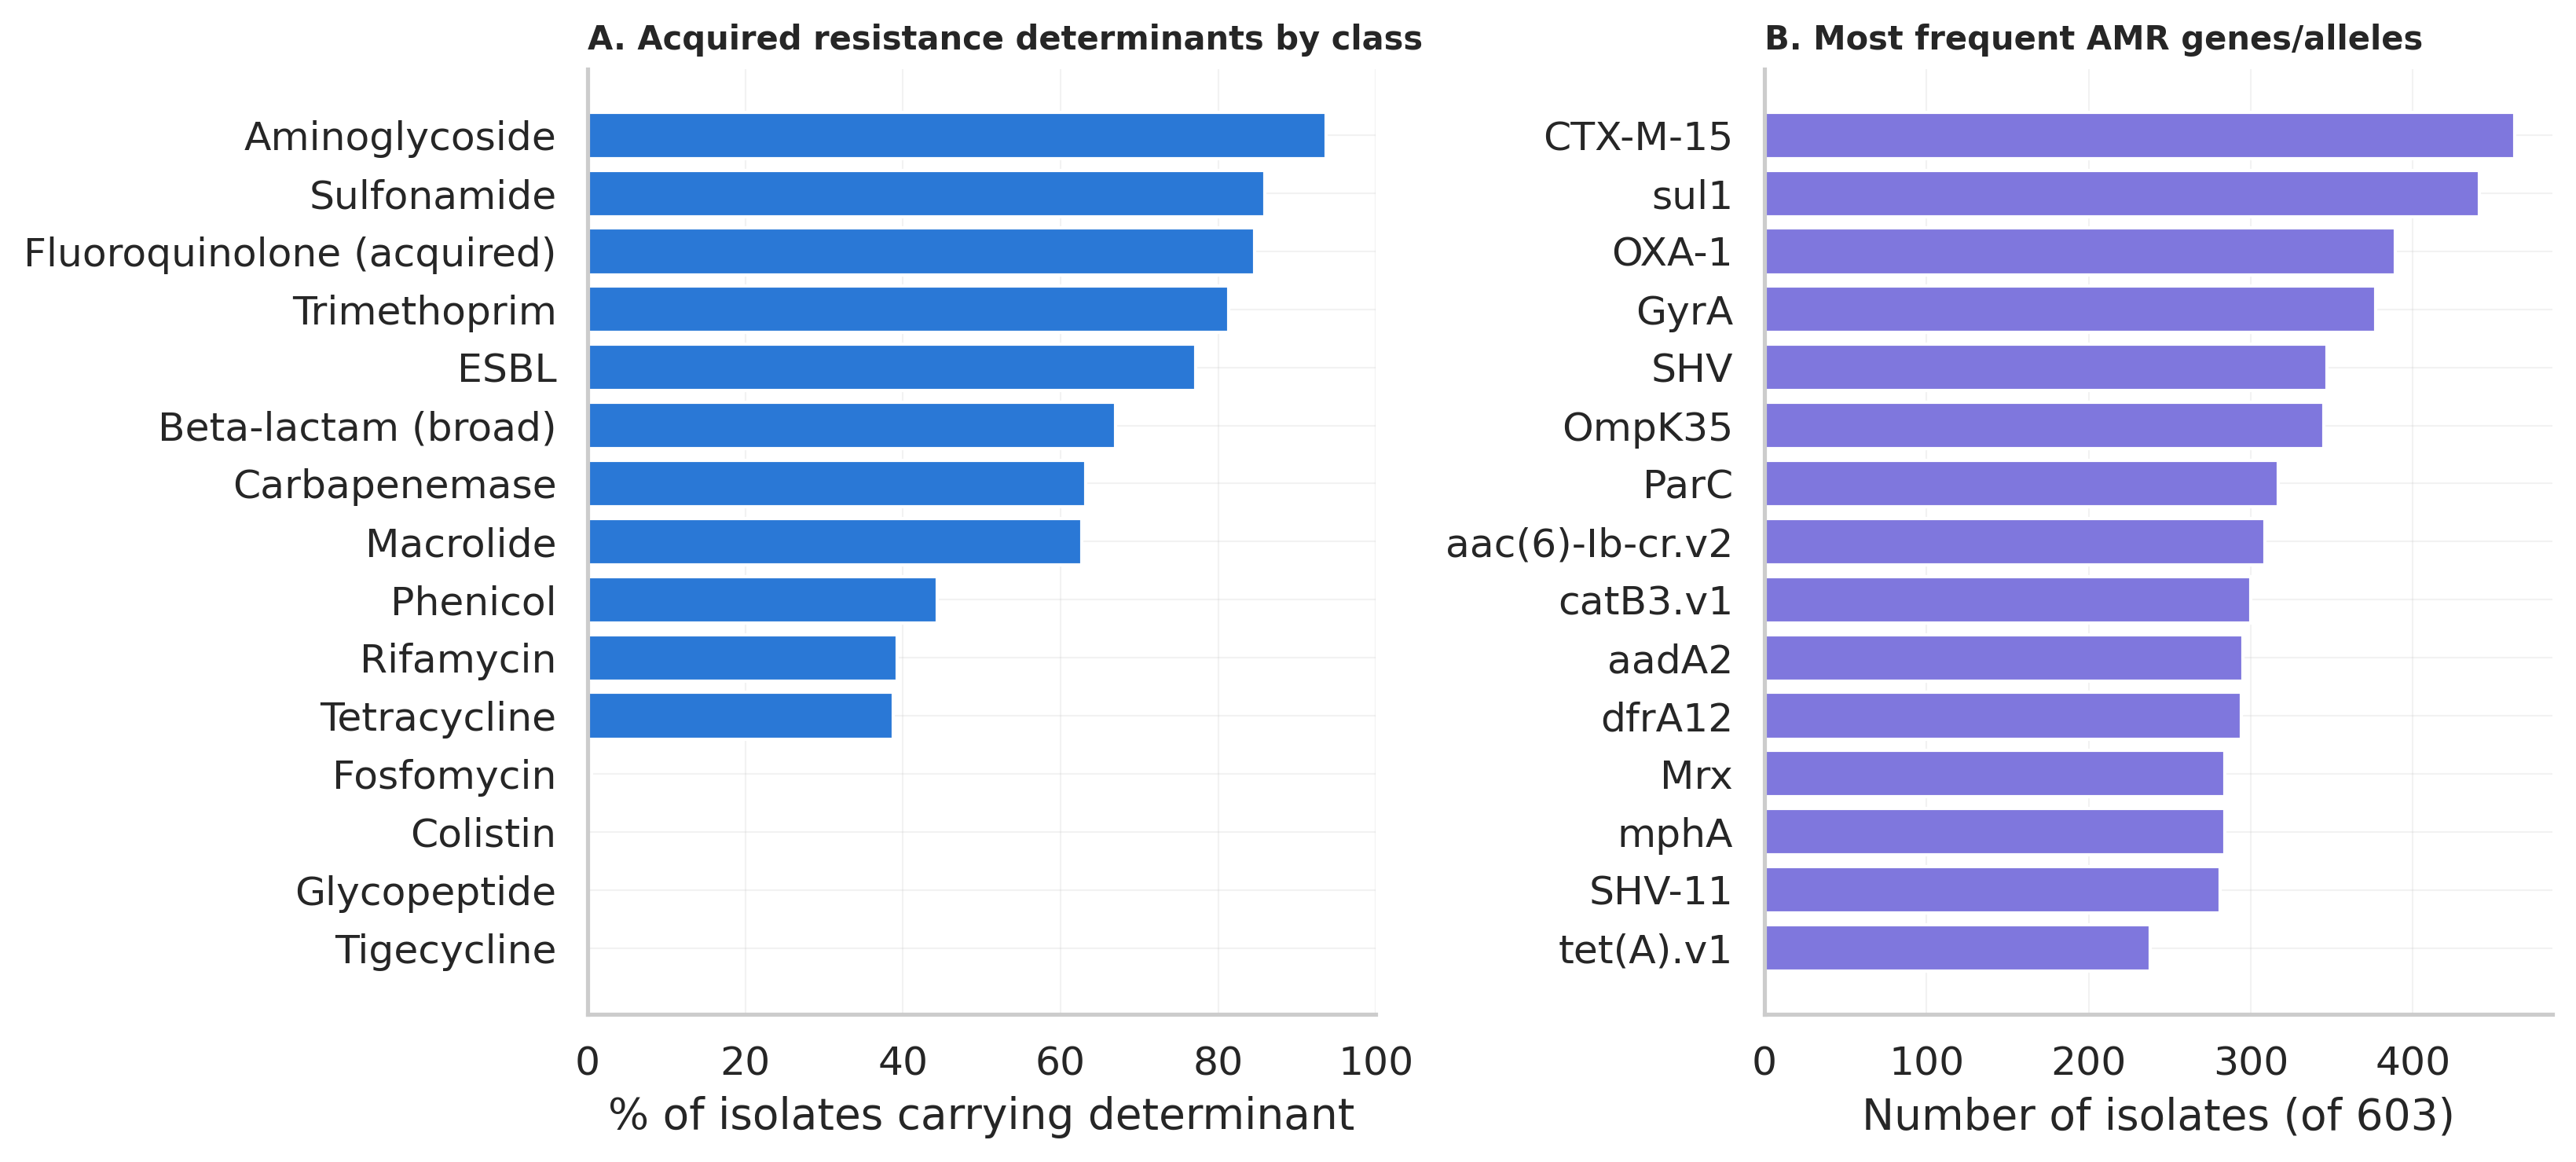

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==============================================================================
# Descriptive AMR gene analysis - all Bangladesh isolates
# (35 study isolates + 569 Pathogenwatch, 603 with Kleborate results)
# ==============================================================================
# Paste each "# %% Cell" block into its own Google Colab cell, in order.

# %% Cell 1 - Install/import
!pip install scipy --quiet

import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 50)

# %% Cell 2 - Upload files
from google.colab import files

print("Upload klebsiella_global753.tsv (Kleborate output):")
u1 = files.upload()
KLEBORATE_FILE = list(u1.keys())[0]

print("Upload global754_final_metadata_with_source_category.csv:")
u2 = files.upload()
METADATA_FILE = list(u2.keys())[0]

# %% Cell 3 - Identify all Bangladesh isolates (study + Pathogenwatch)
df = pd.read_csv(KLEBORATE_FILE, sep='\t', low_memory=False)
meta = pd.read_csv(METADATA_FILE, sep='\t')

bd_ids = meta.loc[meta['Country'] == 'Bangladesh', 'Genome_ID'].tolist()
print(f"Total Bangladesh isolates in metadata: {len(bd_ids)}")

bd = df[df['strain'].isin(bd_ids)].copy()
print(f"Bangladesh isolates with Kleborate results: {len(bd)}")
missing = set(bd_ids) - set(bd['strain'])
if missing:
    print(f"Missing from Kleborate output (e.g. non-KpSC species): {missing}")

n_bd = len(bd)

# %% Cell 4 - Drug-class level prevalence
CLASS_COLS = {
    'Aminoglycoside': 'klebsiella_pneumo_complex__amr__AGly_acquired',
    'Colistin': 'klebsiella_pneumo_complex__amr__Col_acquired',
    'Fosfomycin': 'klebsiella_pneumo_complex__amr__Fcyn_acquired',
    'Fluoroquinolone (acquired)': 'klebsiella_pneumo_complex__amr__Flq_acquired',
    'Glycopeptide': 'klebsiella_pneumo_complex__amr__Gly_acquired',
    'Macrolide': 'klebsiella_pneumo_complex__amr__MLS_acquired',
    'Phenicol': 'klebsiella_pneumo_complex__amr__Phe_acquired',
    'Rifamycin': 'klebsiella_pneumo_complex__amr__Rif_acquired',
    'Sulfonamide': 'klebsiella_pneumo_complex__amr__Sul_acquired',
    'Tetracycline': 'klebsiella_pneumo_complex__amr__Tet_acquired',
    'Tigecycline': 'klebsiella_pneumo_complex__amr__Tgc_acquired',
    'Trimethoprim': 'klebsiella_pneumo_complex__amr__Tmt_acquired',
    'Beta-lactam (broad)': 'klebsiella_pneumo_complex__amr__Bla_acquired',
    'ESBL': 'klebsiella_pneumo_complex__amr__Bla_ESBL_acquired',
    'Carbapenemase': 'klebsiella_pneumo_complex__amr__Bla_Carb_acquired',
}

rows = []
for name, col in CLASS_COLS.items():
    present = (bd[col] != '-').sum()
    rows.append({'drug_class': name, 'n': present, 'pct': round(100 * present / n_bd, 1)})

class_summary = pd.DataFrame(rows).sort_values('pct', ascending=False)
print("Drug-class prevalence, all Bangladesh isolates:")
print(class_summary.to_string(index=False))

# %% Cell 5 - Intrinsic / mutation-based markers
MUT_COLS = {
    'SHV mutations': 'klebsiella_pneumo_complex__amr__SHV_mutations',
    'OmpK porin mutations': 'klebsiella_pneumo_complex__amr__Omp_mutations',
    'Colistin (mgrB etc.) mutations': 'klebsiella_pneumo_complex__amr__Col_mutations',
    'Fluoroquinolone (gyrA/parC) mutations': 'klebsiella_pneumo_complex__amr__Flq_mutations',
}
print("Intrinsic/mutation-based resistance markers:")
for name, col in MUT_COLS.items():
    present = (bd[col] != '-').sum()
    print(f"  {name:40s} {present}/{n_bd} ({100*present/n_bd:.1f}%)")

# %% Cell 6 - Top individual AMR genes/alleles
def gene_counter(subdf, col='AMR_gene_symbols'):
    counter = Counter()
    for v in subdf[col].dropna():
        if v == '-':
            continue
        for g in v.split(';'):
            counter[g.strip()] += 1
    return counter

genes = gene_counter(bd)
print("Top 20 AMR genes/alleles, all Bangladesh isolates:")
for g, c in genes.most_common(20):
    print(f"  {g:20s} {c}/{n_bd}  ({100*c/n_bd:.1f}%)")

# %% Cell 7 - Resistance gene count / resistance score summary statistics
GENE_COUNT_COL = 'klebsiella_pneumo_complex__resistance_gene_count__num_resistance_genes'
RES_SCORE_COL = 'klebsiella_pneumo_complex__resistance_score__resistance_score'
RC_COL = 'klebsiella_pneumo_complex__resistance_class_count__num_resistance_classes'

print("Resistance gene count - descriptive statistics:")
print(bd[GENE_COUNT_COL].describe())
print("\nResistance score - descriptive statistics:")
print(bd[RES_SCORE_COL].describe())
print("\nNumber of resistance classes - descriptive statistics:")
print(bd[RC_COL].describe())

# %% Cell 8 - Figures
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5,
    'figure.dpi': 300,
})

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# Panel A: drug-class prevalence
axes[0].barh(class_summary['drug_class'], class_summary['pct'], color='#2a78d6')
axes[0].set_xlabel('% of isolates carrying determinant')
axes[0].set_xlim(0, 100)
axes[0].invert_yaxis()
axes[0].set_title('A. Acquired resistance determinants by class', loc='left', fontweight='bold', fontsize=10)

# Panel B: top 15 individual genes
top15 = genes.most_common(15)
axes[1].barh([g for g, _ in top15][::-1], [c for _, c in top15][::-1], color='#7f77dd')
axes[1].set_xlabel(f'Number of isolates (of {n_bd})')
axes[1].set_title('B. Most frequent AMR genes/alleles', loc='left', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('Figure_BD_AMR_descriptive.png', dpi=300, bbox_inches='tight')
plt.show()

# %% Cell 9 - Export
with pd.ExcelWriter('BD_AMR_descriptive_summary.xlsx') as writer:
    class_summary.to_excel(writer, sheet_name='Class_prevalence', index=False)
    pd.DataFrame(genes.most_common(30), columns=['gene', 'n_isolates']).to_excel(
        writer, sheet_name='Top_genes', index=False)
    bd[['strain', RC_COL, RES_SCORE_COL, GENE_COUNT_COL]].to_excel(
        writer, sheet_name='Isolate_level', index=False)

from google.colab import files as colab_files
#colab_files.download('BD_AMR_descriptive_summary.xlsx')
colab_files.download('Figure_BD_AMR_descriptive.png')

In [ ]:
# ==============================================================================
# Addressing the study-vs-Bangladesh-public carbapenemase gap:
# stratified by ST, source category, and collection year
# ==============================================================================
# Paste each "# %% Cell" block into its own Google Colab cell, in order.

# %% Cell 1 - Install/import
!pip install scipy --quiet

import pandas as pd
import numpy as np
from scipy.stats import fisher_exact
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.width', 160)

# %% Cell 2 - Upload files
from google.colab import files

print("Upload klebsiella_global753.tsv:")
u1 = files.upload()
KLEBORATE_FILE = list(u1.keys())[0]

print("Upload global754_final_metadata_with_source_category.csv:")
u2 = files.upload()
METADATA_FILE = list(u2.keys())[0]

# %% Cell 3 - Load, merge, restrict to Bangladesh
df = pd.read_csv(KLEBORATE_FILE, sep='\t', low_memory=False)
meta = pd.read_csv(METADATA_FILE, sep='\t').rename(columns={'Genome_ID': 'strain'})
merged = df.merge(meta[['strain', 'Database', 'Country', 'Collection_date', 'Source_category']],
                   on='strain', how='inner')

bd = merged[merged['Country'] == 'Bangladesh'].copy()
bd['group'] = bd['Database'].map({'This_study': 'Study', 'Pathogenwatch': 'Bangladesh-public'})

CARB_COL = 'klebsiella_pneumo_complex__amr__Bla_Carb_acquired'
ST_COL = 'klebsiella_pneumo_complex__mlst__ST'
bd['has_carb'] = bd[CARB_COL].apply(lambda x: x != '-' if pd.notna(x) else False)

print(f"Bangladesh isolates: {len(bd)} (Study={sum(bd.group=='Study')}, "
      f"Bangladesh-public={sum(bd.group=='Bangladesh-public')})")

# %% Cell 4 - Unadjusted comparison (baseline)
ct_overall = pd.crosstab(bd['group'], bd['has_carb'])
print("Overall carbapenemase carriage, Study vs Bangladesh-public:")
print(ct_overall)
odds, p = fisher_exact(ct_overall)
print(f"Odds ratio = {odds:.2f}, Fisher's exact p = {p:.4g}\n")

# %% Cell 5 - Check 1: is the gap explained by ST composition (e.g. ST11 enrichment)?
print("ST composition by group (top 8):")
for g in bd['group'].unique():
    print(f"\n{g} (n={len(bd[bd.group==g])}):")
    print(bd[bd.group == g][ST_COL].value_counts().head(8))

print("\n% ST11 by group:")
print((bd.groupby('group')[ST_COL].apply(lambda x: (x == 'ST11').mean()) * 100).round(1))

# Carbapenemase gap WITHIN ST11 only, and EXCLUDING ST11 - does removing the
# dominant resistant clone from both groups close the gap?
non_st11 = bd[bd[ST_COL] != 'ST11']
ct_non11 = pd.crosstab(non_st11['group'], non_st11['has_carb'])
print("\nCarbapenemase carriage EXCLUDING ST11:")
print(ct_non11)
odds_n, p_n = fisher_exact(ct_non11)
print(f"Odds ratio = {odds_n:.2f}, Fisher's exact p = {p_n:.4g}")
print("(If this OR/p is similar to the unadjusted result above, ST composition")
print(" does NOT explain the gap.)")

# %% Cell 6 - Check 2: is the gap explained by isolation source?
print("Source category by group:")
print(pd.crosstab(bd['group'], bd['Source_category']))

# %% Cell 7 - Check 3: is the gap explained by collection period?
# Parse dates robustly - handles mixed formats like "2016-05-01" and "28-Jan-20"
bd['year'] = pd.to_datetime(bd['Collection_date'], errors='coerce',
                             format='mixed', dayfirst=True).dt.year

print("Collection year range by group:")
print(bd.groupby('group')['year'].describe())

print("\nCarbapenemase prevalence by year - Bangladesh-public (shows temporal trend):")
print(bd[bd.group == 'Bangladesh-public'].groupby('year')['has_carb'].agg(['mean', 'count']))

# The key test: restrict both groups to the SAME collection years and re-compare.
# Adjust this year range to match your study isolates' actual collection period.
study_years = sorted(bd[bd.group == 'Study']['year'].dropna().unique())
print(f"\nStudy isolate collection years: {study_years}")

year_min, year_max = min(study_years), max(study_years)
recent = bd[bd['year'].between(year_min, year_max)]
print(f"\nRestricting comparison to {year_min}-{year_max} only (matching study period):")
print(recent.groupby('group')['has_carb'].agg(['sum', 'count', 'mean']))

ct_recent = pd.crosstab(recent['group'], recent['has_carb'])
print(ct_recent)
odds_r, p_r = fisher_exact(ct_recent)
print(f"Odds ratio = {odds_r:.2f}, Fisher's exact p = {p_r:.4g}")
print("(If this gap is similar to or larger than the unadjusted result, the")
print(" difference is NOT explained by collection period.)")

# %% Cell 8 - Summary table across all three checks
summary = pd.DataFrame([
    {'Comparison': 'Unadjusted (all isolates)', 'OR': odds, 'p': p},
    {'Comparison': 'Excluding ST11', 'OR': odds_n, 'p': p_n},
    {'Comparison': f'Restricted to {year_min}-{year_max}', 'OR': odds_r, 'p': p_r},
])
print("Summary across adjustment checks:")
print(summary.to_string(index=False))

summary.to_csv('carbapenemase_gap_stratified_analysis.csv', index=False)
from google.colab import files as colab_files
colab_files.download('carbapenemase_gap_stratified_analysis.csv')

Upload klebsiella_global753.tsv:


Saving klebsiella_global753.tsv to klebsiella_global753 (3).tsv
Upload global754_final_metadata_with_source_category.csv:


Saving global754_final_metadata_with_source_category.csv to global754_final_metadata_with_source_category (7).csv
Bangladesh isolates: 603 (Study=34, Bangladesh-public=569)
Overall carbapenemase carriage, Study vs Bangladesh-public:
has_carb           False  True 
group                          
Bangladesh-public    192    377
Study                 30      4
Odds ratio = 0.07, Fisher's exact p = 2.467e-10

ST composition by group (top 8):

Study (n=34):
klebsiella_pneumo_complex__mlst__ST
ST515     3
ST16      3
ST4221    2
ST147     2
ST45      2
ST1322    1
ST645     1
ST540     1
Name: count, dtype: int64

Bangladesh-public (n=569):
klebsiella_pneumo_complex__mlst__ST
ST11     89
ST16     57
ST147    51
ST48     50
ST340    18
ST14     17
ST502    17
ST15     14
Name: count, dtype: int64

% ST11 by group:
group
Bangladesh-public    15.6
Study                 2.9
Name: klebsiella_pneumo_complex__mlst__ST, dtype: float64

Carbapenemase carriage EXCLUDING ST11:
has_carb           False

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Notably, carbapenemase carriage was substantially lower among the 34 study isolates (12.1%, excluding ST11) than among Bangladesh-origin Pathogenwatch genomes from the same period (61.3%, excluding ST11; 2019–2021 subset: 93.4% vs. 10.5%). This difference persisted after excluding the ST11 high-risk clone and restricting comparison to isolates collected within the same time window, indicating that neither clonal composition nor temporal trends in national carbapenem resistance explain the gap. This likely reflects differences in sampling frame rather than a true divergence in local epidemiology: publicly deposited genomes are disproportionately drawn from reference collections, outbreak investigations, or resistant-strain-focused studies, which may enrich for carbapenem-resistant isolates relative to the more general clinical sampling reflected in this study's collection.